# 0. 분석 준비

- 03 노트북이 저장한 월말 RFM 스냅샷으로 세그먼트 구성·전환율·매출 추이를 보고, 휴면 구조를 분해합니다.
- 가입 코호트 구성을 고정해도 At_Risk → Dormant 전환율이 오르는지 검증합니다.
- VIP → Loyal 진입 고객의 12개월 경로와, 실제 휴면 전환자의 VIP 경로·구매가치를 추적합니다.

## 0.1. 라이브러리

In [ ]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine, text, inspect
from collections import Counter
import math

import warnings
import os
from pathlib import Path
from IPython.display import display

import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib
from matplotlib.ticker import PercentFormatter
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
from matplotlib.patches import Patch

In [334]:
# =====================================================================================
# [CHART THEME v2] 보고서 게재 차트 공통 규칙  — Layer 1(공통) + Layer 2(유형별)
# =====================================================================================
# 이 셀은 '규칙'만 정의한다. "무엇을 강조할 것인가"(Layer 3)는 각 차트 셀이 스스로 정한다.
#
# [v2 변경점]
#   (1) 범례 규칙 통일 — 예외 없이 '축 바깥 우상단'. legend_loc 인자를 없앴다.
#       바깥 범례는 플롯 폭을 잠식하므로 fig_size() 가 LEGEND_W 만큼 캔버스를 넓힌다.
#   (2) 범례 순서 — sort_legend(on/off) 를 없애고 legend_order(명시 리스트)로 일원화.
#       세그먼트면 SEGMENT_ORDER, 아니면 해당 차트가 순서를 명시한다. '정렬 안 함'은 없다.
#   (3) 제목-부제 간격 — 부제를 축 좌표(1.012)가 아니라 offset points 로 띄운다.
#       축 높이가 2.6인치든 8인치든 간격이 같아진다. 제목 pad 도 20 → 32.
#   (4) 범례 handles/labels 를 직접 넘길 수 있게 함(범례용 더미 핸들을 쓰는 차트 대응).
# =====================================================================================
import matplotlib.ticker as mticker

# ---------- C1 한글 폰트 (셀 1의 koreanize_matplotlib 로 이미 적용됨) -------------------
plt.rcParams["axes.unicode_minus"] = False

# ---------- C2 폰트 크기 위계 ----------------------------------------------------------
FS_TITLE, FS_SUB, FS_AXIS, FS_TICK, FS_LABEL = 16, 10.5, 12, 10, 9
FS_PANEL = 14                      # 다중 패널의 개별 패널 제목

# ---------- C2b 제목 · 부제 간격 --------------------------------------------------------
TITLE_PAD      = 14                # 부제가 없을 때
TITLE_PAD_SUB  = 32                # 부제가 있을 때 (부제가 들어갈 자리를 비운다)
SUB_OFFSET_PT  = 8                 # 축 상단에서 부제까지 (pt 고정 → 축 높이와 무관)

# ---------- C3 캔버스 폭 ----------------------------------------------------------------
FIG_W        = 14.0                # 1패널 '플롯 영역' 폭
FIG_W_2PANE  = 16.0                # 2패널 '플롯 영역' 합계 폭
LEGEND_W     = 2.6                 # 바깥 범례에 할당하는 폭

def fig_size(height, plot_w=None, legends=1):
    """플롯 영역 폭 + 범례 폭. 범례를 바깥에 두면 플롯이 좁아지므로 그만큼 캔버스를 넓힌다.
       legends=0 이면 범례가 없는 차트."""
    return ((FIG_W if plot_w is None else plot_w) + LEGEND_W * legends, height)

# ---------- C4 세그먼트 색상 고정 매핑 (Set3) -------------------------------------------
_SEG_ABC    = ["At_Risk", "Dormant", "Low_Value", "Loyal", "Potential", "Regular", "VIP"]
PALETTE_SEG = dict(zip(_SEG_ABC, sns.color_palette("Set3", n_colors=7)))
PALETTE_SEG["Dormant"] = "darkgray"
palette_dict = PALETTE_SEG          # 기존 셀들이 쓰는 이름을 같은 객체로 묶어 이원화를 방지

# ---------- C5 세그먼트 순서(범례·정렬) 고정 -------------------------------------------
SEGMENT_ORDER  = ["VIP", "Loyal", "At_Risk", "Regular", "Potential", "Low_Value", "Dormant"]
TIER_PRIMARY   = ["VIP", "Loyal", "At_Risk"]
TIER_SECONDARY = ["Regular", "Potential", "Low_Value"]

# ---------- C11 텍스트 위계 : alpha 가 아니라 잉크 색으로 ------------------------------
INK_PRIMARY   = "#1A1A1A"   # 대비 약 16.5:1
INK_SECONDARY = "#5A5A5A"   # 대비 약  6.9:1 (WCAG AA 통과)
INK_MUTED     = "#8A897F"   # 보조선 · 부제
LABEL_BBOX    = dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85)

# ---------- 비(非)세그먼트 범주용 Okabe-Ito --------------------------------------------
CAT_PALETTE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9"]

# =====================================================================================
# Layer 2 — 차트 유형별 스타일
# =====================================================================================
def line_style(seg, primary=None, secondary=None):
    """선: 위계는 alpha + linewidth 로."""
    p = TIER_PRIMARY   if primary   is None else primary
    s = TIER_SECONDARY if secondary is None else secondary
    if seg in p:
        return dict(alpha=1.00, linewidth=3.0, zorder=5, markersize=5)
    if seg in s:
        return dict(alpha=0.55, linewidth=1.8, zorder=3, markersize=3)
    return dict(alpha=0.45, linewidth=1.5, zorder=2, markersize=3)

def bar_style(is_primary=True):
    """막대: 면적이 넓어 alpha 를 쓰면 색이 혼합되므로 edgecolor 로 분리."""
    return dict(alpha=1.00 if is_primary else 0.65,
                edgecolor="white", linewidth=2.0, zorder=3)

def ink(is_primary=True):
    return INK_PRIMARY if is_primary else INK_SECONDARY

# =====================================================================================
# finalize() — C2·C5~C10 일괄 적용. 모든 차트의 마지막에 호출한다.
# =====================================================================================
def finalize(ax, title=None, xlabel=None, ylabel=None, *,
             subtitle=None, panel=False,
             legend=True, legend_title="세그먼트", legend_order=None, legend_ncol=1,
             handles=None, labels=None,
             grid_axis="y", unit_fmt=None, xtick_rotation=None, layout=True):
    # ---- 제목 · 부제 (C2b) -------------------------------------------------------------
    if title is not None:
        ax.set_title(title, fontsize=FS_PANEL if panel else FS_TITLE, fontweight="bold",
                     pad=TITLE_PAD_SUB if subtitle else TITLE_PAD)
    if subtitle:
        ax.annotate(subtitle, xy=(0.5, 1.0), xycoords="axes fraction",
                    xytext=(0, SUB_OFFSET_PT), textcoords="offset points",
                    ha="center", va="bottom", fontsize=FS_SUB, color=INK_MUTED,
                    annotation_clip=False)

    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=FS_AXIS)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=FS_AXIS)
    ax.tick_params(labelsize=FS_TICK)
    if xtick_rotation is not None:
        ax.tick_params(axis="x", rotation=xtick_rotation)

    # ---- C10 축 눈금 단위 = 데이터 라벨 단위 -------------------------------------------
    if unit_fmt:
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: unit_fmt.format(v)))

    # ---- C7 격자 (가로 막대는 "x", 격자가 무의미하면 None) ------------------------------
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle="--", alpha=0.4)
        ax.set_axisbelow(True)

    # ---- C6 spine ----------------------------------------------------------------------
    for s in ["top", "right"] + (["left"] if grid_axis == "x" else []):
        ax.spines[s].set_visible(False)

    # ---- C8 범례 : 예외 없이 '축 바깥 우상단', 순서는 명시 리스트로 --------------------
    if legend:
        h, l = (handles, labels) if handles is not None else ax.get_legend_handles_labels()
        if h:
            order = legend_order if legend_order is not None else SEGMENT_ORDER
            idx = sorted(range(len(l)),
                         key=lambda i: order.index(l[i]) if l[i] in order else 999 + i)
            ax.legend([h[i] for i in idx], [l[i] for i in idx], title=legend_title,
                      bbox_to_anchor=(1.02, 1.0), loc="upper left",
                      fontsize=FS_SUB, title_fontsize=FS_SUB, frameon=False, ncol=legend_ncol)
    if layout:
        plt.tight_layout()

print("[CHART THEME v2] 로드 — FIG_W=%.0f  LEGEND_W=%.1f  세그먼트 순서: %s"
      % (FIG_W, LEGEND_W, " > ".join(SEGMENT_ORDER[:4]) + " ..."))

# [화면용 선택 프로필] 좁은 보고서 본문에서 1개 이미지당 1개 차트 사용.
# 기존 기본값은 유지한다. 범례는 이 프로필에서만 상단 가로 배치를 허용한다.
SCREEN_FIG_W = 9.0
SCREEN_FS_LABEL = 12
SCREEN_FS_TICK = 12
SCREEN_FS_AXIS = 13

def finalize_screen(ax, title, xlabel=None, ylabel=None, grid_axis='y'):
    finalize(ax,title,xlabel,ylabel,legend=False,grid_axis=grid_axis,layout=False)
    ax.tick_params(labelsize=SCREEN_FS_TICK)
    ax.xaxis.label.set_size(SCREEN_FS_AXIS)
    ax.yaxis.label.set_size(SCREEN_FS_AXIS)
    ax.title.set_fontsize(FS_TITLE)


[CHART THEME v2] 로드 — FIG_W=14  LEGEND_W=2.6  세그먼트 순서: VIP > Loyal > At_Risk > Regular ...


In [335]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 500)

warnings.filterwarnings('ignore')

## 0.2. 데이터 로드

In [336]:
# Data 리스트 불러오기
data_path = os.path.join(os.getcwd(), '..', 'data')
data_files = os.listdir(data_path)

# DB Table에 적재하지 않는 파일을 리스트에서 제거
table_order = ['users', 'products', 'promotions', 'events', 'orders', 'order_items']  # 'users', 'products', 'promotions', 'events', 'orders', 'order_items'
data_files = [(file.split('.')[0], file.split('.')[1]) for file in data_files if file.split('.')[0] in table_order]

print(data_files)

[('products', 'csv'), ('orders', 'csv'), ('users', 'csv'), ('events', 'parquet'), ('promotions', 'csv'), ('order_items', 'csv')]


In [337]:
# 테이블별 날짜 컬럼 정의
date_cols = {
    "users": ["created_at", "birth"],
    "products": [],
    "promotions": ["start_date", "end_date"],
    "events": ["created_at"],
    "orders": ["created_at", "withdrawn_at", "returned_at", "shipped_at", "delivered_at"],
    "order_items": ["created_at", "withdrawn_at", "shipped_at", "delivered_at", "returned_at"],
}

if "df_dict" in globals():
    print("========== df_dict already exists ==========")
    for file_name, ext in data_files:
        if ext == 'csv':
            df_dict[file_name] = pd.read_csv(os.path.join(data_path, f"{file_name}.{ext}"), parse_dates=date_cols.get(file_name, []))
        elif ext == 'parquet':
            df_dict[file_name] = pd.read_parquet(os.path.join(data_path, f"{file_name}.{ext}"), engine='pyarrow')
        print(f"✅ {file_name} loaded")
else:
    print("========== df_dict does not exist ==========")
    # DataFrame 딕셔너리 생성
    df_dict = {}
    for file_name, ext in data_files:
        if ext == 'csv':
            df_dict[file_name] = pd.read_csv(
                os.path.join(data_path, f"{file_name}.{ext}"),
                parse_dates=date_cols.get(file_name, [])
            )
        elif ext == 'parquet':
            df_dict[file_name] = pd.read_parquet(
                os.path.join(data_path, f"{file_name}.{ext}"),
                engine='pyarrow'
            )
        print(f"✅ {file_name} loaded")

# 로드 확인
for name, df in df_dict.items():
    print(f"{name}: {df.shape}")

========== df_dict does not exist ==========
✅ products loaded


✅ orders loaded
✅ users loaded
✅ events loaded
✅ promotions loaded
✅ order_items loaded
products: (30000, 8)
orders: (280340, 10)
users: (103648, 11)
events: (15366289, 12)
promotions: (15, 8)
order_items: (548660, 17)


In [338]:
events_df = df_dict['events']
orders_df = df_dict['orders']
order_items_df = df_dict['order_items']
users_df = df_dict['users']
products_df = df_dict['products']
promotions_df = df_dict['promotions']

del df_dict

## 0.3. 데이터마트 생성: 주문 단위 고객 및 주문 정보

03 노트북에서 저장한 월말 RFM 스냅샷을 불러오고, 주문 단위 금액 테이블(`orders_enriched`)을 다시 만듭니다.

In [ ]:
# 03 노트북에서 저장한 월말 RFM 스냅샷
snapshots_df = pd.read_parquet(os.path.join(data_path, "snapshots_df.parquet"))
print(snapshots_df.shape)

In [348]:
def build_order_level_amounts(orders_df: pd.DataFrame, order_items_df: pd.DataFrame) -> pd.DataFrame:
    """
    주문 단위 금액(order_amount) 생성:
      order_amount = Σ(sale_price) by order_id
    """
    o = orders_df.copy()
    oi = order_items_df.copy()

    # datetime 캐스팅
    o["created_at"] = pd.to_datetime(o["created_at"], errors="coerce")
    

    # 숫자 캐스팅
    oi["sale_price"] = pd.to_numeric(oi["sale_price"], errors="coerce").fillna(0.0)
    oi["num_of_items"] = pd.to_numeric(oi["num_of_items"], errors="coerce").fillna(0).astype(int)

    # order_id 기준 집계
    order_amounts = (
        oi[oi['status'].isin(['Purchased', 'Shipped', 'Packing'])].groupby("order_id", as_index=False)
          .agg(
              order_amount=("sale_price", "sum"),           # 주문 총 금액
              item_rows=("id", "count"),                    # 주문 상품 수
              distinct_products=("product_id", "nunique"),  # 주문 상품 종류 수
              qty_sum=("num_of_items", "sum"),              # 주문 상품 총 개수
          )
    )

    # orders에 붙이기 (orders.id == order_items.order_id)
    out = o.merge(order_amounts, left_on="id", right_on="order_id", how="left")
    out = out.dropna(subset=['order_amount', 'item_rows', 'distinct_products', 'qty_sum'])

    # 조인 후 생긴 중복키 정리
    out = out.drop(columns=["order_id"])

    return out
    

In [349]:
orders_enriched = build_order_level_amounts(orders_df, order_items_df)
orders_enriched.head()

,id,user_id,status,gender,created_at,withdrawn_at,shipped_at,delivered_at,returned_at,num_of_items,order_amount,item_rows,distinct_products,qty_sum
0,or-00007c1b304e,70131,Completed,M,2024-12-07 10:01:11,NaT,2024-12-07 23:34:08,2024-12-09 09:31:19,NaT,1,10440.0,1.0,1.0,1.0
1,or-00009bda2202,19543,Processing,M,2024-12-31 15:58:27,NaT,NaT,NaT,NaT,1,41400.0,1.0,1.0,1.0
2,or-0000a689fc6b,41124,Completed,M,2023-07-03 07:10:52,NaT,2023-07-04 00:36:33,2023-07-06 11:17:03,NaT,5,234000.0,2.0,2.0,5.0
3,or-0000c4021e62,36445,Completed,F,2024-01-25 08:45:03,NaT,2024-01-26 02:48:58,2024-01-28 22:58:46,NaT,6,442980.0,4.0,4.0,6.0
4,or-0000c830f7b3,67269,Completed,M,2023-01-30 16:51:49,NaT,2023-01-31 05:31:15,2023-02-03 01:22:45,NaT,4,137290.0,3.0,3.0,4.0


# 1. 세그먼트별 구매빈도 및 객단가 변화

전체 평균 구매빈도·AOV의 변화를 세그먼트 내부 변화와 구성비 변화로 나눕니다 (Shift-Share).

### 1.1. AOV와 구매 빈도의 세그먼트간 이질성 검증  `[A9] [A10] [A12]`

매출 분석은 플랫폼 **전체 평균**으로 구매빈도(1.45\~1.55건)와 AOV를 진단했고, 두 지표 모두 3년간 거의 변하지 않았다고 결론지었다.
그러나 평균이 움직이지 않는 원인은 논리적으로 둘 중 하나다.

| 가설 | 내용 | 함의 |
| --- | --- | --- |
| (a) **균질 정체** | 모든 세그먼트가 똑같이 정체 | 개선 여지가 구조적으로 없음 |
| (b) **상쇄** | 상승 그룹과 하락 그룹이 서로 지움 | 그룹별로 다른 레버가 존재 |

전체 평균만으로는 (a)와 (b)를 구분할 수 없다. 아래에서 세 단계로 검증한다.

- **A9** — 세그먼트별 구매빈도·AOV 추이를 산출해 방향이 서로 다른지 확인
- **A10** — 전사 평균의 변화를 **내부 변화(Within)** 와 **구성 변화(Between)** 로 분해 *(shift-share)*
- **A12** — 세그먼트별 매출 성장을 `구매고객 × 빈도 × AOV`의 로그 기여도로 분해 *(→ 2-5절)*

> **지표 정의** — 세그먼트는 해당 월의 스냅샷 세그먼트를 사용하고, 지표는 **당월 실적** 기준이다(R12M 누적이 아님).
> 이렇게 해야 매출 분석의 월별 평균과 직접 비교·대조할 수 있다.

=== 매출 분석 대조 검증 ===
  2023  평균 구매빈도 1.494건   평균 AOV 144,114원
  2024  평균 구매빈도 1.525건   평균 AOV 150,309원
  (매출 분석 기준: 빈도 1.45~1.55건 · AOV 144,114원 → 150,309원)


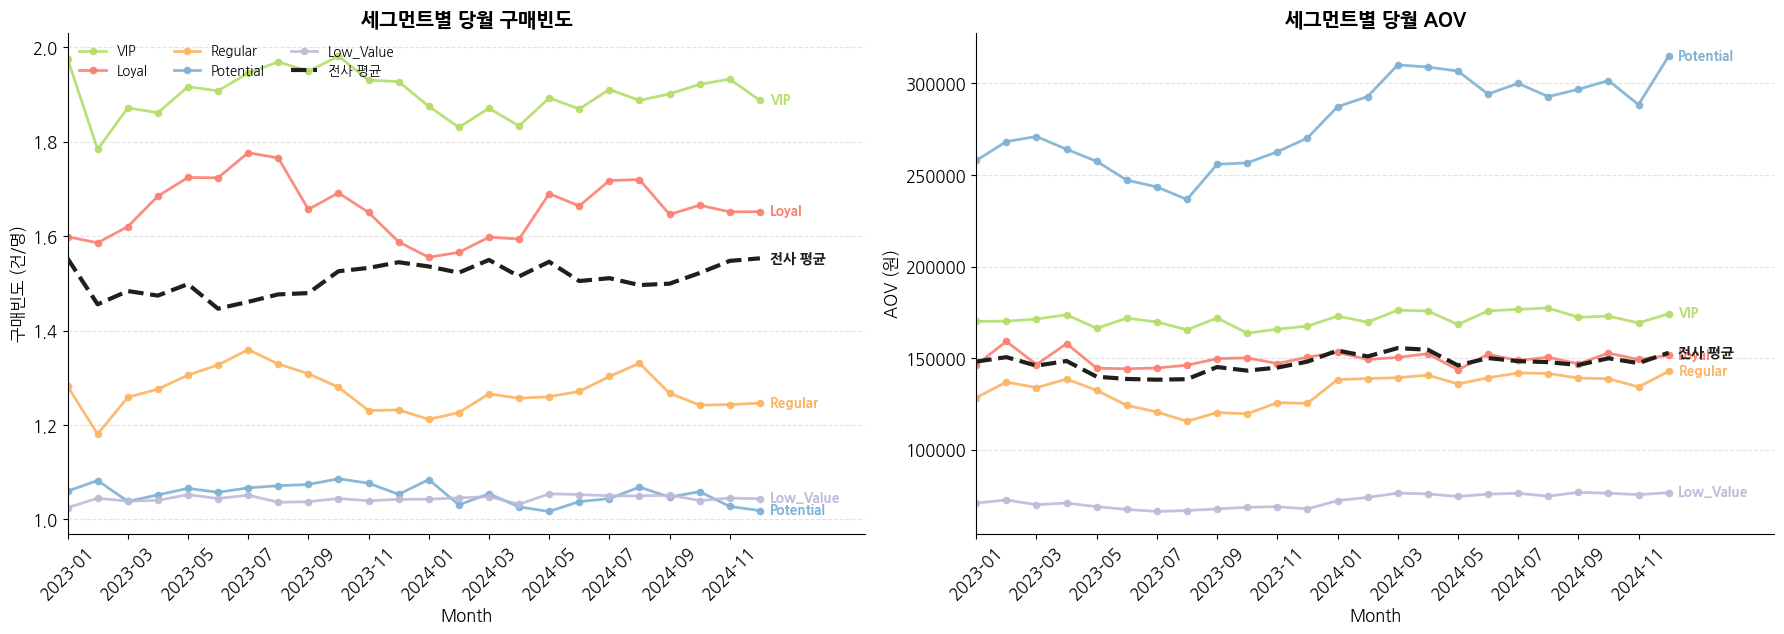


=== 세그먼트별 연간 구매빈도 · AOV ===


freq              aov           
yr         2023  2024       2023       2024
segment                                    
Low_Value  1.04  1.05   68381.38   75407.44
Loyal      1.67  1.64  148500.37  150064.09
Potential  1.07  1.05  254193.01  298796.83
Regular    1.29  1.26  124793.44  139216.17
VIP        1.93  1.88  168429.17  173375.07

→ 구매빈도가 상승한 세그먼트: Low_Value
→ 구매빈도가 하락한 세그먼트: Loyal, Potential, Regular, VIP


In [498]:
# =====================================================================================
# [A9] 세그먼트별 당월 실적 지표 산출 + 구매빈도 추이
# =====================================================================================
# 매출 분석의 월별 평균(빈도 1.45~1.55건, AOV 14~15만원)과 직접 대조하기 위해
# R12M 누적이 아닌 **당월 실적** 기준으로 세그먼트별 지표를 만든다.
#   buyers = 당월 구매 고객 수 / orders = 당월 주문 수 / revenue = 당월 매출
#   freq = orders / buyers      aov = revenue / orders      arppu = revenue / buyers
# 전사 평균은 세그먼트 지표의 가중평균과 정확히 일치하므로(Σorders/Σbuyers),
# 이 테이블 하나로 A10의 shift-share와 A12의 로그 분해가 모두 가능하다.
# =====================================================================================

PAID_STATUSES_A = {"Completed", "Processing"}

def segment_monthly_activity(snapshots_df: pd.DataFrame,
                             orders_enriched_df: pd.DataFrame,
                             paid_statuses: set = PAID_STATUSES_A) -> pd.DataFrame:
    """월 × 세그먼트 단위의 당월 실적 지표(buyers / orders / revenue / freq / aov / arppu)."""
    o = orders_enriched_df.copy()
    o["created_at"] = pd.to_datetime(o["created_at"], errors="coerce")
    if "status" in o.columns:
        o = o[o["status"].isin(paid_statuses)]
    o = o.dropna(subset=["user_id", "created_at"])
    o["month"] = o["created_at"].dt.to_period("M").astype(str)

    # 고객 × 월 단위로 먼저 압축 (스냅샷과 1:1 조인)
    ua = (o.groupby(["month", "user_id"], as_index=False)
            .agg(orders=("id", "nunique"), revenue=("order_amount", "sum")))

    snap = (snapshots_df[["snapshot_month", "user_id", "segment"]]
            .rename(columns={"snapshot_month": "month"}))
    merged = ua.merge(snap, on=["month", "user_id"], how="inner")

    g = (merged.groupby(["month", "segment"], as_index=False)
               .agg(buyers=("user_id", "nunique"),
                    orders=("orders", "sum"),
                    revenue=("revenue", "sum")))
    g["freq"]  = g["orders"] / g["buyers"]
    g["aov"]   = g["revenue"] / g["orders"]
    g["arppu"] = g["revenue"] / g["buyers"]
    return g

seg_act = segment_monthly_activity(snapshots_df, orders_enriched)

# ---- 전사 집계 (검증용) ---------------------------------------------------------------
plat = seg_act.groupby("month").agg(buyers=("buyers", "sum"),
                                    orders=("orders", "sum"),
                                    revenue=("revenue", "sum"))
plat["freq"] = plat["orders"] / plat["buyers"]
plat["aov"]  = plat["revenue"] / plat["orders"]

print("=== 매출 분석 대조 검증 ===")
for y in ["2023", "2024"]:
    sub = plat.loc[plat.index.str.startswith(y)]
    print(f"  {y}  평균 구매빈도 {sub['freq'].mean():.3f}건   평균 AOV {sub['aov'].mean():,.0f}원")
print("  (매출 분석 기준: 빈도 1.45~1.55건 · AOV 144,114원 → 150,309원)")

# ---- 세그먼트별 구매빈도 추이 -----------------------------------------------------------
months = sorted(seg_act["month"].unique())
x = np.arange(len(months))
segs = [s for s in ["VIP", "Loyal", "Regular", "Potential", "Low_Value", "At_Risk"]
        if s in set(seg_act["segment"])]

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
for ax, (col, ylab, ttl) in zip(axes, [("freq", "구매빈도 (건/명)", "세그먼트별 당월 구매빈도"),
                                       ("aov", "AOV (원)", "세그먼트별 당월 AOV")]):
    for sg in segs:
        d = seg_act[seg_act["segment"] == sg].set_index("month").reindex(months)
        ax.plot(x, d[col].values, marker="o", markersize=4.5, linewidth=2,
                color=palette_dict[sg], label=sg, alpha=0.9)
        ax.annotate(sg, xy=(x[-1], d[col].values[-1]), xytext=(7, 0),
                    textcoords="offset points", va="center",
                    fontsize=10, fontweight="bold", color=palette_dict[sg])
    ax.plot(x, plat[col].reindex(months).values, color="#201F1C", linewidth=3,
            linestyle="--", label="전사 평균", zorder=8)
    ax.annotate("전사 평균", xy=(x[-1], plat[col].reindex(months).values[-1]), xytext=(7, 0),
                textcoords="offset points", va="center", fontsize=10,
                fontweight="bold", color="#201F1C")
    ax.set_title(ttl, fontsize=14, fontweight="bold")
    ax.set_ylabel(ylab); ax.set_xlabel("Month")
    ax.set_xticks(x[::2]); ax.set_xticklabels([months[i] for i in range(0, len(months), 2)], rotation=45)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_xlim(0, len(months) + 2.5)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
axes[0].legend(frameon=False, fontsize=9.5, loc="upper left", ncol=3)
plt.tight_layout()
plt.show()

# ---- 연간 요약표 -----------------------------------------------------------------------
seg_act["yr"] = seg_act["month"].str[:4]
seg_year = (seg_act.groupby(["yr", "segment"], as_index=False)
                   .agg(buyers=("buyers", "sum"), orders=("orders", "sum"), revenue=("revenue", "sum")))
seg_year["freq"] = seg_year["orders"] / seg_year["buyers"]
seg_year["aov"]  = seg_year["revenue"] / seg_year["orders"]

_p = seg_year.pivot(index="segment", columns="yr", values=["freq", "aov"]).round(2)
print("\n=== 세그먼트별 연간 구매빈도 · AOV ===")
display(_p)
_f = seg_year.pivot(index="segment", columns="yr", values="freq")
print("→ 구매빈도가 상승한 세그먼트:",
      ", ".join(_f.index[_f["2024"] > _f["2023"]].tolist()) or "없음")
print("→ 구매빈도가 하락한 세그먼트:",
      ", ".join(_f.index[_f["2024"] < _f["2023"]].tolist()) or "없음")


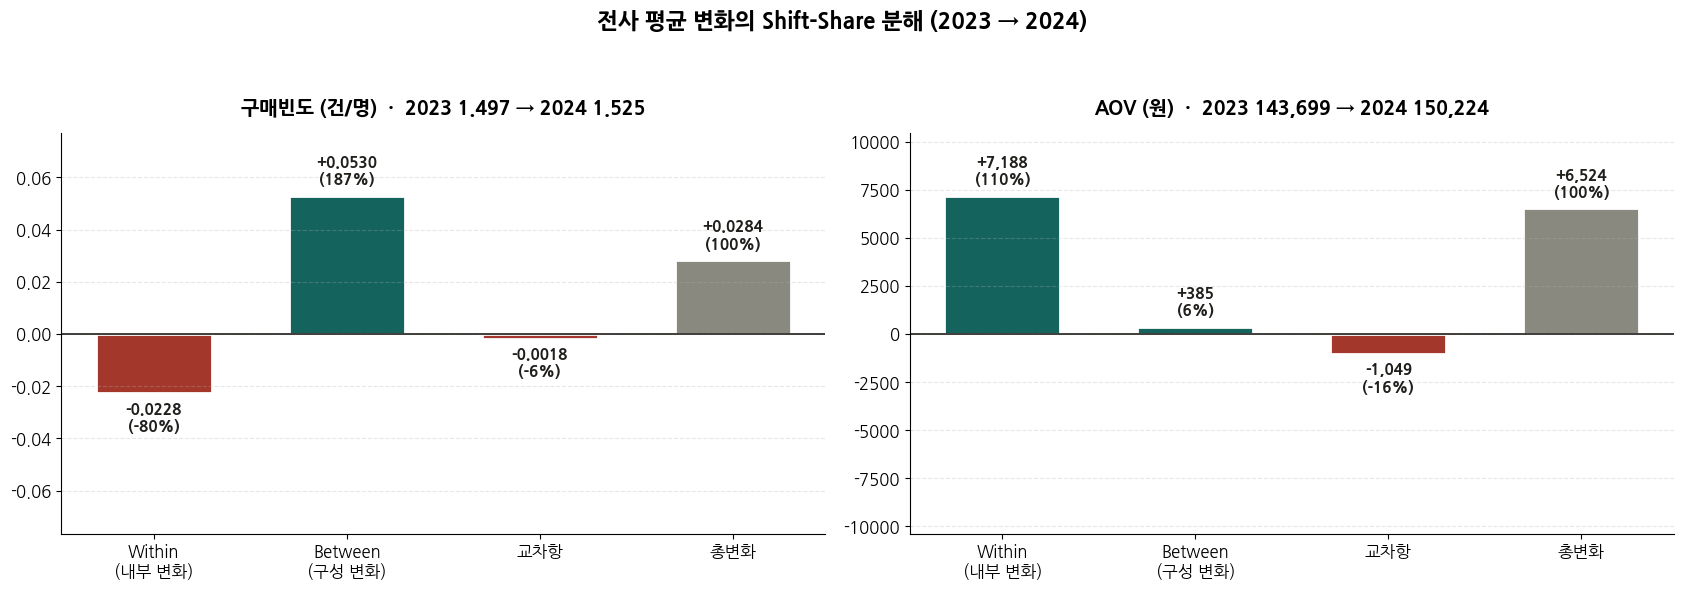


=== 구매빈도 ===
  총변화 +0.0284  =  Within -0.0228  +  Between +0.0530  +  교차 -0.0018
  [판정] **상쇄 확인** — 총변화는 상승이지만 각 세그먼트 내부는 반대 방향(하락)이며, 구성 변화가 이를 가리고 있음.


,w_2023,w_2024,m_2023,m_2024,Δw,Δm
segment,,,,,,
Low_Value,0.3022,0.2796,1.0420,1.0468,-0.0226,0.0048
Loyal,0.2006,0.2000,1.6749,1.6431,-0.0006,-0.0319
Potential,0.0658,0.0335,1.0679,1.0452,-0.0323,-0.0227
Regular,0.0862,0.0782,1.2860,1.2609,-0.0080,-0.0251
VIP,0.3452,0.4087,1.9256,1.8844,0.0635,-0.0411



=== AOV ===
  총변화 +6,524.3303  =  Within +7,188.1813  +  Between +385.1464  +  교차 -1,048.9973
  [판정] 내부 변화가 지배적임 — 실제 개선/악화로 해석 가능.


,w_2023,w_2024,m_2023,m_2024,Δw,Δm
segment,,,,,,
Low_Value,0.2104,0.1919,68381.3835,75407.4443,-0.0185,7026.0608
Loyal,0.2245,0.2155,148500.3661,150064.0916,-0.0090,1563.7255
Potential,0.0470,0.0230,254193.0112,298796.8262,-0.0240,44603.8150
Regular,0.0741,0.0646,124793.4403,139216.1651,-0.0094,14422.7249
VIP,0.4441,0.5050,168429.1681,173375.0694,0.0609,4945.9013


In [499]:
# =====================================================================================
# [A10] Shift-Share 분해 — 전사 평균의 변화를 '내부 변화'와 '구성 변화'로 가르기
# =====================================================================================
# 전사 평균은 세그먼트 지표의 가중평균이다.
#     평균 = Σ wᵢ · mᵢ        (빈도의 가중치 = 구매고객 비중, AOV의 가중치 = 주문 비중)
# 따라서 변화량은 다음 세 항으로 정확히 분해된다.
#     Δ평균 = Σ wᵢ,0·Δmᵢ   [Within · 각 세그먼트 내부의 실제 변화]
#           + Σ mᵢ,0·Δwᵢ   [Between · 세그먼트 구성비 변화]
#           + Σ Δwᵢ·Δmᵢ    [교차항]
# Within이 음수인데 총변화가 양수라면, "평균은 올랐지만 각 그룹 내부는 나빠졌고
# 구성 변화가 그것을 가렸다"는 뜻이다. 이것이 (b) 상쇄 가설의 직접 증거가 된다.
# =====================================================================================

POS_C, NEG_C, NEU_C = "#14635D", "#A3372B", "#8A897F"

def shift_share(df_year: pd.DataFrame, metric: str, weight_col: str,
                y0: str = "2023", y1: str = "2024") -> dict:
    a = df_year[df_year["yr"] == y0].set_index("segment")
    b = df_year[df_year["yr"] == y1].set_index("segment")
    segs = sorted(set(a.index) | set(b.index))
    a, b = a.reindex(segs).fillna(0), b.reindex(segs).fillna(0)

    w0, w1 = a[weight_col] / a[weight_col].sum(), b[weight_col] / b[weight_col].sum()
    m0, m1 = a[metric].fillna(0), b[metric].fillna(0)

    within  = float((w0 * (m1 - m0)).sum())
    between = float((m0 * (w1 - w0)).sum())
    inter   = float(((w1 - w0) * (m1 - m0)).sum())
    total   = float((w1 * m1).sum() - (w0 * m0).sum())
    return {"within": within, "between": between, "inter": inter, "total": total,
            "base": float((w0 * m0).sum()), "end": float((w1 * m1).sum()),
            "detail": pd.DataFrame({"w_2023": w0, "w_2024": w1, "m_2023": m0, "m_2024": m1,
                                    "Δw": w1 - w0, "Δm": m1 - m0})}

SPECS = [("freq", "buyers", "구매빈도 (건/명)", "{:+.4f}"),
         ("aov",  "orders", "AOV (원)",         "{:+,.0f}")]

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
results = {}
for ax, (metric, wcol, label, fmt) in zip(axes, SPECS):
    r = shift_share(seg_year, metric, wcol)
    results[metric] = r
    names = ["Within\n(내부 변화)", "Between\n(구성 변화)", "교차항", "총변화"]
    vals  = [r["within"], r["between"], r["inter"], r["total"]]
    cols  = [POS_C if v >= 0 else NEG_C for v in vals[:3]] + [NEU_C]

    bars = ax.bar(names, vals, color=cols, width=0.6, edgecolor="white", linewidth=2)
    for bar, v in zip(bars, vals):
        off = 6 if v >= 0 else -6
        ax.annotate(fmt.format(v) + (f"\n({v/r['total']*100:.0f}%)" if r["total"] else ""),
                    xy=(bar.get_x() + bar.get_width() / 2, v), xytext=(0, off),
                    textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top",
                    fontsize=11, fontweight="bold", color="#201F1C")
    ax.axhline(0, color="#201F1C", linewidth=1.2)
    ax.set_title(f"{label}  ·  2023 {r['base']:,.3f} → 2024 {r['end']:,.3f}"
                 if metric == "freq" else
                 f"{label}  ·  2023 {r['base']:,.0f} → 2024 {r['end']:,.0f}",
                 fontsize=14, fontweight="bold", pad=14)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    lim = max(abs(min(vals)), abs(max(vals))) * 1.45
    ax.set_ylim(-lim, lim)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

fig.suptitle("전사 평균 변화의 Shift-Share 분해 (2023 → 2024)", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# ---- 판정 -----------------------------------------------------------------------------
for metric, label in [("freq", "구매빈도"), ("aov", "AOV")]:
    r = results[metric]
    print(f"\n=== {label} ===")
    print(f"  총변화 {r['total']:+,.4f}  =  Within {r['within']:+,.4f}"
          f"  +  Between {r['between']:+,.4f}  +  교차 {r['inter']:+,.4f}")
    if r["within"] * r["total"] < 0:
        print(f"  [판정] **상쇄 확인** — 총변화는 {'상승' if r['total']>0 else '하락'}이지만 "
              f"각 세그먼트 내부는 반대 방향({'하락' if r['within']<0 else '상승'})이며, "
              f"구성 변화가 이를 가리고 있음.")
    elif abs(r["between"]) > abs(r["within"]):
        print("  [판정] 구성 변화가 내부 변화보다 크게 작용함.")
    else:
        print("  [판정] 내부 변화가 지배적임 — 실제 개선/악화로 해석 가능.")
    display(results[metric]["detail"].round(4))


# 2. 휴면(Dormant) 현황 분석

휴면을 미구매·단기 휴면·장기 휴면으로 분해하고, 휴면 증가의 구성과 신규 가입자와의 관계를 봅니다.

### 2.1. 휴면(Dormant) 구조 분해  `[A1]`

현재 `Dormant`는 `RFM_sum == 0`, 즉 **스냅샷 기준일로부터 최근 365일간 구매가 없는 고객**으로 정의된다.
이 정의에는 성격이 전혀 다른 세 집단이 섞여 있다.

| 유형 | 정의 | 실패한 단계 | 필요한 액션 |
| --- | --- | --- | --- |
| `Never` | 가입 후 **한 번도 구매하지 않음** | Activation | 첫 구매 유도 (온보딩·첫구매 쿠폰) |
| `Lapsed_Short` | 마지막 구매 후 **365일 초과 \~ 730일 이하** | Retention | Winback (복귀 캠페인) |
| `Lapsed_Long` | 마지막 구매 후 **730일 초과** | \- | 사실상 완전 이탈, 캠페인 모수에서 제외 |

세 집단의 액션이 서로 다르므로, 이를 분해하지 않으면 "휴면 71.73%"라는 수치로부터 어떤 개선 과제도 도출할 수 없다.

> **주의** — `snapshots_df`의 `recency_days`는 **lookback 365일 이내의 주문만** 사용해 계산되므로, 365일을 넘긴 고객은 모두 `lookback_days + 999`(=1364)로 채워져 있어 단기/장기 휴면을 구분할 수 없다.
> 따라서 아래에서는 **lookback 제한이 없는 전체 주문 이력**으로 별도의 `recency_all`을 산출한다.

In [ ]:
# =====================================================================================
# 전체 주문 이력 기반 recency 산출 + 월간 전이 페어 테이블 구축
# =====================================================================================
# 1) user_order_span : lookback 제한 없이 고객별 최초/최종 구매일과 총 주문 수
# 2) snap_ext        : 스냅샷 + recency_all + dormant_type (A1용)
# 3) pair            : (t-1 세그먼트, t 세그먼트) 페어 + 가입 코호트 + tenure (A3용)
#
# 구매 인정 기준은 compute_rfm_purchase(셀 23)와 동일하게 {Completed, Processing}으로 맞춘다.
# =====================================================================================

PAID_STATUSES = {"Completed", "Processing"}
LOOKBACK_DAYS = 365          # 세그먼트 정의에 쓰인 lookback
LONG_DORMANT_DAYS = 730      # 장기 휴면 경계 (24개월)

# ---------- 1) 전체 기간 주문 이력 ----------------------------------------------------
_o = orders_enriched.copy()
_o["created_at"] = pd.to_datetime(_o["created_at"], errors="coerce")
if "status" in _o.columns:
    _o = _o[_o["status"].isin(PAID_STATUSES)]
_o = _o.dropna(subset=["user_id", "created_at"])

user_order_span = (
    _o.groupby("user_id", as_index=False)
      .agg(first_order_dt_all=("created_at", "min"),
           last_order_dt_all=("created_at", "max"),
           orders_all=("id", "nunique"))
)
print(f"[준비] 구매 이력이 있는 고객 수: {len(user_order_span):,}명")

# ---------- 2) 스냅샷 확장 : recency_all + dormant_type -------------------------------
snap_ext = snapshots_df[["snapshot_month", "user_id", "segment", "days_since_signup"]].copy()
snap_ext["month_dt"] = pd.to_datetime(snap_ext["snapshot_month"])
snap_ext["as_of"] = snap_ext["month_dt"] + pd.offsets.MonthEnd(0)
snap_ext = snap_ext.merge(user_order_span, on="user_id", how="left")

# lookback에 갇히지 않은 '진짜' recency
snap_ext["recency_all"] = (snap_ext["as_of"] - snap_ext["last_order_dt_all"]).dt.days

is_dormant = snap_ext["segment"].eq("Dormant")
cond_never = snap_ext["last_order_dt_all"].isna() | (snap_ext["as_of"] < snap_ext["first_order_dt_all"])
cond_short = snap_ext["recency_all"].between(LOOKBACK_DAYS + 1, LONG_DORMANT_DAYS)
cond_long  = snap_ext["recency_all"] > LONG_DORMANT_DAYS

snap_ext["dormant_type"] = np.select(
    [~is_dormant,
     is_dormant & cond_never,
     is_dormant & cond_short,
     is_dormant & cond_long],
    ["(active)", "Never", "Lapsed_Short", "Lapsed_Long"],
    default="Unclassified",
)

# 미분류 발생 여부 점검 (금액 0원 주문 등 경계 사례)
_unc = int((snap_ext["dormant_type"] == "Unclassified").sum())
if _unc:
    print(f"[경고] 분류되지 않은 Dormant {_unc:,}건 — 최근 365일 내 주문이 있으나 monetary=0인 경계 사례일 수 있음")
else:
    print("[준비] Dormant 3분해 완료 — 미분류 0건")

# ---------- 3) 월간 전이 페어 테이블 (t-1 -> t) ---------------------------------------
_d = snapshots_df[["snapshot_month", "user_id", "segment", "days_since_signup"]].copy()
_d["month"] = pd.to_datetime(_d["snapshot_month"])

_prev = (_d.rename(columns={"month": "month_prev", "segment": "seg_prev",
                            "days_since_signup": "tenure_prev"})
           [["user_id", "month_prev", "seg_prev", "tenure_prev"]])
_prev["month_cur"] = _prev["month_prev"] + pd.DateOffset(months=1)

_cur = _d[["user_id", "month", "segment"]].rename(columns={"month": "month_cur", "segment": "seg_cur"})

pair = _prev.merge(_cur, on=["user_id", "month_cur"], how="inner")

# 가입 코호트 부여 (2021년 이전은 하나로 묶음)
_signup = users_df[["id", "created_at"]].rename(columns={"id": "user_id", "created_at": "signup_dt"}).copy()
_signup["signup_dt"] = pd.to_datetime(_signup["signup_dt"], errors="coerce")
_yr = _signup["signup_dt"].dt.year
_signup["signup_cohort"] = np.where(_yr <= 2021, "~2021", _yr.astype("Int64").astype(str))
pair = pair.merge(_signup[["user_id", "signup_cohort"]], on="user_id", how="left")

print(f"[준비] 전이 페어 {len(pair):,}행 · 구간 "
      f"{pair['month_cur'].min():%Y-%m} ~ {pair['month_cur'].max():%Y-%m}")

# ---------- 공통 팔레트 (색맹 안전 · Okabe-Ito 기반, 검증 통과 순서) ------------------
DORMANT_ORDER   = ["Never", "Lapsed_Short", "Lapsed_Long"]
DORMANT_LABEL   = {"Never": "미구매 (Activation 실패)",
                   "Lapsed_Short": "단기 휴면 12~24개월 (Winback 대상)",
                   "Lapsed_Long": "장기 휴면 24개월 초과 (완전 이탈)"}
DORMANT_COLOR   = {"Never": "#0072B2", "Lapsed_Short": "#E69F00", "Lapsed_Long": "#D55E00"}
CAT_COLORS      = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7"]


[준비] 구매 이력이 있는 고객 수: 54,492명
[경고] 분류되지 않은 Dormant 5,495건 — 최근 365일 내 주문이 있으나 monetary=0인 경계 사례일 수 있음
[준비] 전이 페어 1,567,706행 · 구간 2023-02 ~ 2024-12


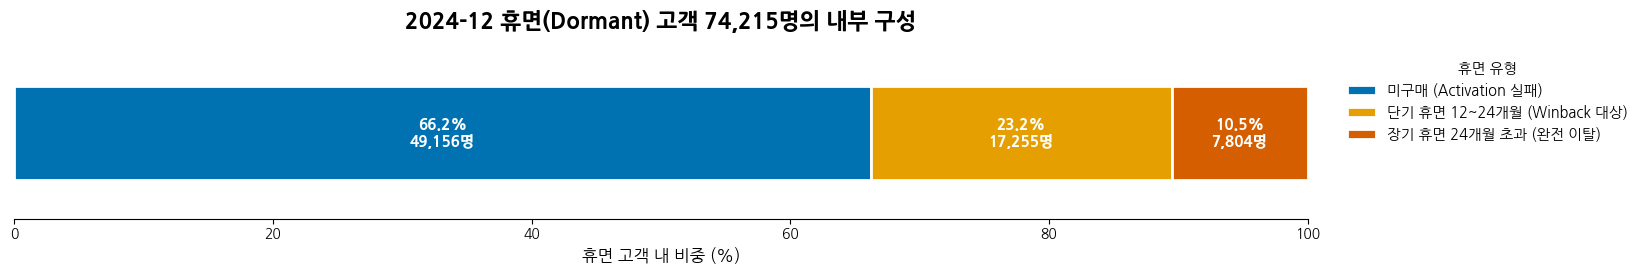

In [ ]:
# =====================================================================================
# [차트] 2024-12 시점 휴면 구조 — 구성표 + 100% 누적 막대
# =====================================================================================
TARGET_MONTH = "2024-12"

_t = snap_ext[snap_ext["snapshot_month"] == TARGET_MONTH]
total_pool = _t["user_id"].nunique()
_dorm = _t[_t["segment"] == "Dormant"]

comp = (_dorm.groupby("dormant_type", as_index=False)
             .agg(고객수=("user_id", "nunique")))
comp = comp.set_index("dormant_type").reindex(DORMANT_ORDER).fillna(0).reset_index()
comp["고객수"] = comp["고객수"].astype(int)
comp["휴면 내 비중(%)"] = (comp["고객수"] / comp["고객수"].sum() * 100).round(2)
comp["전체 고객 대비(%)"] = (comp["고객수"] / total_pool * 100).round(2)
comp["유형"] = comp["dormant_type"].map(DORMANT_LABEL)

fig, ax = plt.subplots(figsize=fig_size(2.9))
left = 0.0
_handles = []
for _, row in comp.iterrows():
    w = row["휴면 내 비중(%)"]
    b = ax.barh(0, w, left=left, height=0.55,
                color=DORMANT_COLOR[row["dormant_type"]],
                label=DORMANT_LABEL[row["dormant_type"]], **bar_style())
    _handles.append(b)
    if w >= 6:
        ax.text(left + w / 2, 0, f"{w:.1f}%\n{row['고객수']:,}명", ha="center", va="center",
                color="white", fontsize=FS_AXIS - 1, fontweight="bold")
    left += w

ax.set_xlim(0, 100); ax.set_ylim(-0.5, 0.5); ax.set_yticks([])
finalize(ax, f"{TARGET_MONTH} 휴면(Dormant) 고객 {comp['고객수'].sum():,}명의 내부 구성",
         "휴면 고객 내 비중 (%)", None, grid_axis=None,
         legend_title="휴면 유형",
         legend_order=[DORMANT_LABEL[k] for k in DORMANT_ORDER])
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
plt.show()


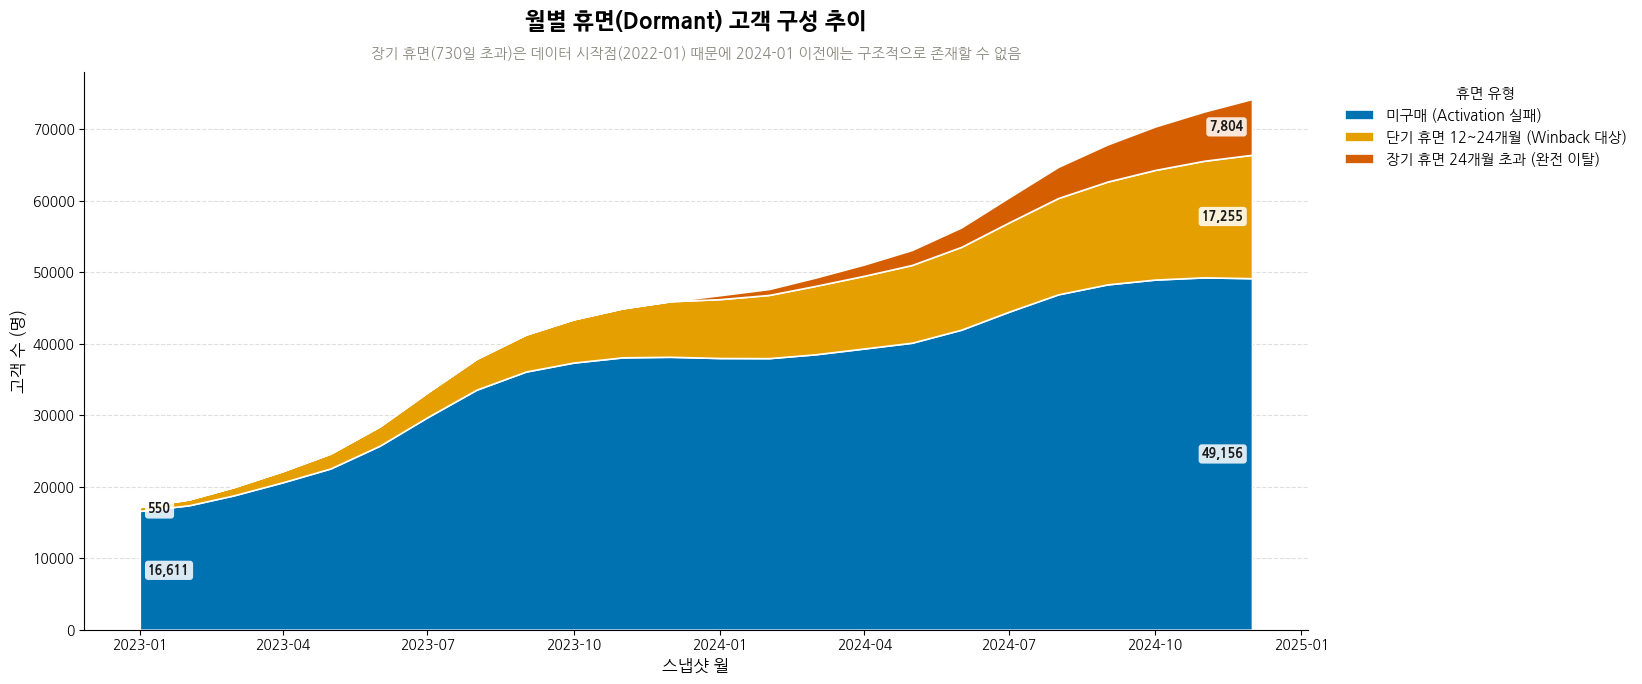

In [ ]:
# =====================================================================================
# [차트] 월별 휴면 구조 추이 — 유형별 고객 수 누적 영역
# =====================================================================================

trend = (snap_ext[snap_ext["segment"] == "Dormant"]
         .groupby(["month_dt", "dormant_type"], as_index=False)
         .agg(customers=("user_id", "nunique")))
trend_piv = (trend.pivot(index="month_dt", columns="dormant_type", values="customers")
                  .reindex(columns=DORMANT_ORDER).fillna(0).sort_index())

fig, ax = plt.subplots(figsize=fig_size(7))
ax.stackplot(trend_piv.index, *[trend_piv[c].values for c in DORMANT_ORDER],
             labels=[DORMANT_LABEL[c] for c in DORMANT_ORDER],
             colors=[DORMANT_COLOR[c] for c in DORMANT_ORDER],
             edgecolor="white", linewidth=1.2)

for m in [trend_piv.index[0], trend_piv.index[-1]]:
    cum, first = 0, (m == trend_piv.index[0])
    for c in DORMANT_ORDER:
        v = trend_piv.loc[m, c]
        if v > 0:
            ax.annotate(f"{int(v):,}", xy=(m, cum + v / 2), xytext=(6 if first else -6, 0),
                        textcoords="offset points", ha="left" if first else "right",
                        va="center", fontsize=FS_LABEL, fontweight="bold",
                        color=ink(True), bbox=LABEL_BBOX, zorder=10)
        cum += v

finalize(ax, "월별 휴면(Dormant) 고객 구성 추이", "스냅샷 월", "고객 수 (명)",
         subtitle="장기 휴면(730일 초과)은 데이터 시작점(2022-01) 때문에 2024-01 이전에는 구조적으로 존재할 수 없음",
         legend_title="휴면 유형",
         legend_order=[DORMANT_LABEL[c] for c in DORMANT_ORDER])
plt.show()


In [437]:
def monthly_segment_summary(
    snapshots_df: pd.DataFrame,
    month_col: str = "snapshot_month",
    seg_col: str = "segment",
    user_col: str = "user_id",
    ensure_segments: list[str] | None = ['At_Risk', 'Dormant', 'Low_Value', 'Loyal', 'Potential', 'Regular', 'VIP'],
) -> pd.DataFrame:
    """
    월별 세그먼트 고객 수 + 구성비(%)를 한 번에 산출.

    Returns columns:
      - snapshot_month (datetime64[ns])
      - segment
      - customers (nunique user_id)
      - total_customers (월 전체 고객수)
      - ratio_pct (customers / total_customers * 100)
    """
    df = snapshots_df[[month_col, seg_col, user_col]].copy()

    # month 정렬 안전장치 (입력이 "YYYY-MM" 문자열인 케이스)
    df[month_col] = pd.to_datetime(df[month_col])

    # 월×세그먼트 고객 수
    seg_cnt = (
        df.groupby([month_col, seg_col], as_index=False)
          .agg(customers=(user_col, "nunique"))
    )

    # 월별 전체 고객 수
    month_total = (
        seg_cnt.groupby(month_col, as_index=False)
               .agg(total_customers=("customers", "sum"))
    )

    out = seg_cnt.merge(month_total, on=month_col, how="left")
    out["ratio_pct"] = (out["customers"] / out["total_customers"] * 100).round(2)

    # (선택) 특정 세그먼트가 어떤 달에 0명이라도 행을 만들어 유지하고 싶을 때
    if ensure_segments is not None:
        months = out[month_col].drop_duplicates().sort_values()
        grid = (
            pd.MultiIndex.from_product([months, ensure_segments], names=[month_col, seg_col])
            .to_frame(index=False)
        )
        out = grid.merge(out, on=[month_col, seg_col], how="left")
        out["customers"] = out["customers"].fillna(0).astype(int)

        # total_customers는 월별로 동일해야 하므로 month_total로 재결합
        out = out.drop(columns=["total_customers", "ratio_pct"], errors="ignore") \
                 .merge(month_total, on=month_col, how="left")
        out["ratio_pct"] = (out["customers"] / out["total_customers"] * 100).round(2)

    return out.sort_values([month_col, seg_col])

In [438]:
segment_monthly_summary_df = monthly_segment_summary(snapshots_df, ensure_segments=snapshots_df["segment"].unique())
segment_monthly_summary_df.head()

,snapshot_month,segment,customers,total_customers,ratio_pct
1,2023-01-01,At_Risk,1629,30127,5.41
2,2023-01-01,Dormant,17267,30127,57.31
3,2023-01-01,Low_Value,5061,30127,16.80
4,2023-01-01,Loyal,2501,30127,8.30
5,2023-01-01,Potential,549,30127,1.82


In [ ]:
df_dormant = segment_monthly_summary_df[
    segment_monthly_summary_df["segment"] == "Dormant"
]

target_segments = snapshots_df["segment"].unique()
target_segments = target_segments[target_segments != "Dormant"]

df_active = monthly_segment_summary(snapshots_df[snapshots_df["segment"] != "Dormant"], ensure_segments=target_segments)

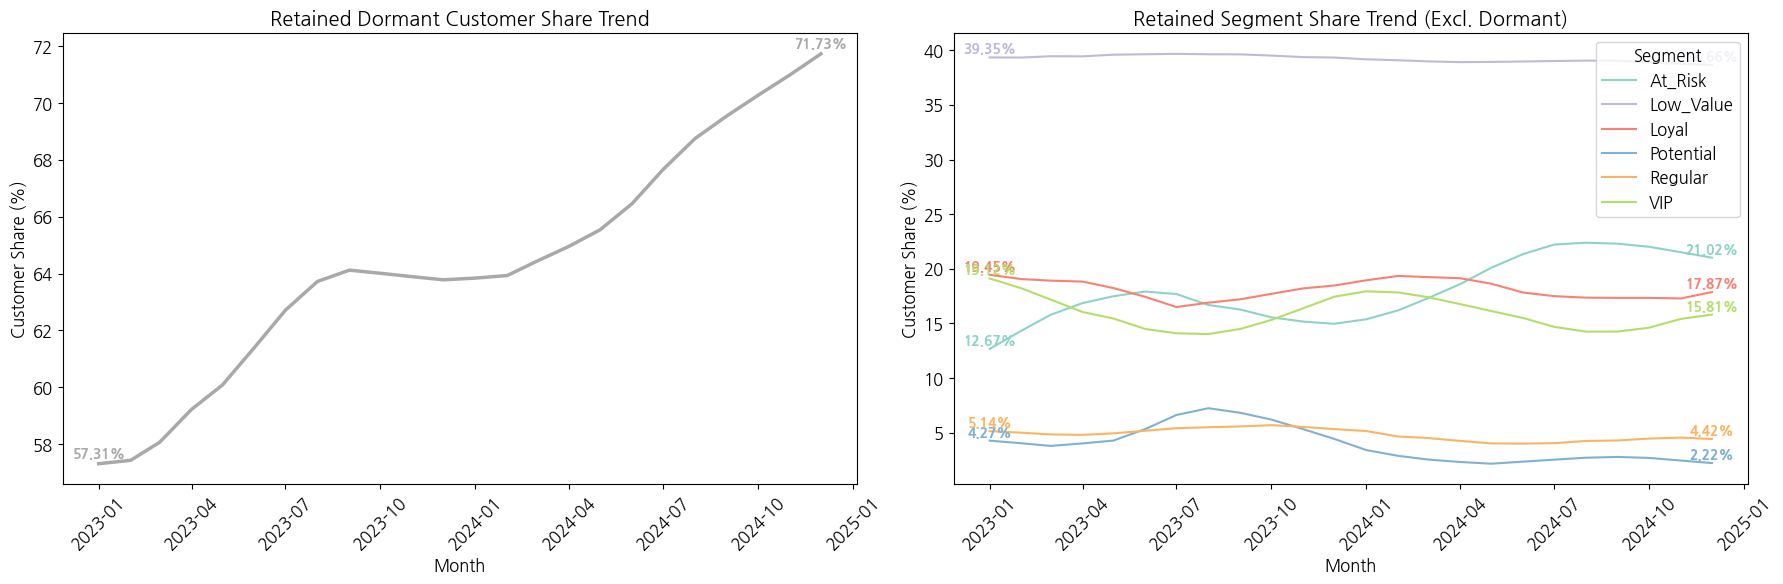

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharex=True)
palette = sns.color_palette("Set3")[2:]

# 음영 색상
shade_color = 'lightgray'
# 강조 색상
highlight_color = palette[1]

# -------------------------
# (1) Dormant 단독
# -------------------------
sns.lineplot(
    data=df_dormant,
    x="snapshot_month",
    y="ratio_pct",
    ax=axes[0],
    color=palette_dict['Dormant'],
    linewidth=2.5,
)

axes[0].set_title("Retained Dormant Customer Share Trend")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Customer Share (%)")
axes[0].tick_params(axis="x", rotation=45)

# x축 양 끝 점의 수치 표시
if not df_dormant.empty:
    first_point = df_dormant.iloc[0]
    last_point = df_dormant.iloc[-1]
    axes[0].text(
        first_point["snapshot_month"],
        first_point["ratio_pct"] + 0.1,
        f"{first_point['ratio_pct']:.2f}%",
        va="bottom",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=palette_dict['Dormant'],
    )
    axes[0].text(
        last_point["snapshot_month"],
        last_point["ratio_pct"] + 0.1,
        f"{last_point['ratio_pct']:.2f}%",
        va="bottom",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=palette_dict['Dormant'],
    )

# -------------------------
# (2) Dormant 제외 세그먼트, At_Risk만 별도 색, 나머지는 VIP와 같은 색상
# -------------------------
for idx, seg in enumerate(df_active["segment"].unique()):
    seg_df = df_active[df_active["segment"] == seg]
    # At_Risk만 별도 색상, 나머지 동일색
    if seg == "At_Risk":
        seg_color = highlight_color
    else:
        seg_color = shade_color
    sns.lineplot(
        data=seg_df,
        x="snapshot_month",
        y="ratio_pct",
        ax=axes[1],
        label=seg,
        color=palette_dict[seg],
    )
    # x축 양 끝 점의 수치 표시
    if not seg_df.empty:
        seg_first = seg_df.iloc[0]
        seg_last = seg_df.iloc[-1]
        axes[1].text(
            seg_first["snapshot_month"],
            seg_first["ratio_pct"] + 0.1,
            f"{seg_first['ratio_pct']:.2f}%",
            va="bottom",
            ha="center",
            fontsize=10,
            fontweight="bold",
            color=palette_dict[seg],
        )
        axes[1].text(
            seg_last["snapshot_month"],
            seg_last["ratio_pct"] + 0.1,
            f"{seg_last['ratio_pct']:.2f}%",
            va="bottom",
            ha="center",
            fontsize=10,
            fontweight="bold",
            color=palette_dict[seg],
        )

axes[1].set_title("Retained Segment Share Trend (Excl. Dormant)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Customer Share (%)")
axes[1].legend(title="Segment")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

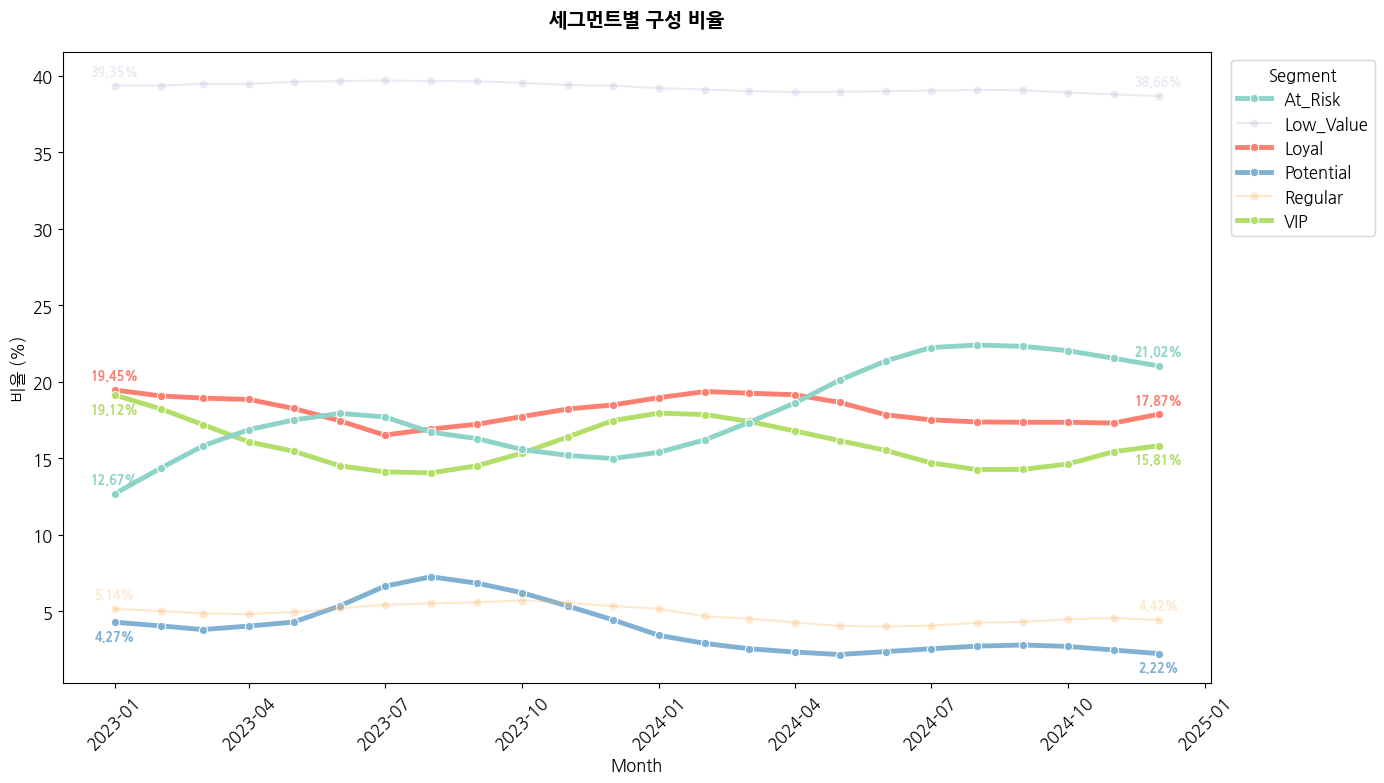

In [ ]:
fig, ax = plt.subplots(figsize=(14, 8))

all_segments = df_active["segment"].unique()

# 핵심 강조 세그먼트 정의
highlight_segments = ["At_Risk", "VIP", "Loyal", "Potential"]

size_dict = {seg: 3.5 if seg in highlight_segments else 1.5 for seg in all_segments}

# 하단 라벨 적용 세그먼트 정의
bottom_label_segments = ["Potential", "VIP"]

# -------------------------
# (2) 세그먼트별 라인 플롯 및 라벨링
# -------------------------
for idx, seg in enumerate(all_segments):
    seg_df = df_active[df_active["segment"] == seg]
    
    # [수정] 조건에 따른 선 두께(lw) 및 투명도(alpha) 설정
    if seg in highlight_segments:
        lw = 3.5
        alpha_val = 1.0  # 핵심 세그먼트는 선명하게
    else:
        lw = 1.5
        alpha_val = 0.3  # 그 외 세그먼트는 투명하게 처리 (Background)
    
    sns.lineplot(
        data=seg_df,
        x="snapshot_month",
        y="ratio_pct",
        label=seg,
        marker="o",
        color=palette_dict[seg],
        linewidth=lw,
        alpha=alpha_val,  # 투명도 적용
        ax=ax
    )

    # [수정] x축 양 끝 점의 수치 표시 및 위치 조정
    if not seg_df.empty:
        seg_first = seg_df.iloc[0]
        seg_last = seg_df.iloc[-1]
        
        # 세그먼트별 텍스트 수직 정렬(va) 및 오프셋 결정
        if seg in bottom_label_segments:
            va_type = "top"
            offset = -0.5  # 라인 하단 배치
        else:
            va_type = "bottom"
            offset = 0.5   # 라인 상단 배치
        
        # 시작점 텍스트
        plt.text(
            seg_first["snapshot_month"],
            seg_first["ratio_pct"] + offset,
            f"{seg_first['ratio_pct']:.2f}%",
            va=va_type, ha="center", fontsize=9, fontweight="bold", 
            color=palette_dict[seg], alpha=alpha_val
        )
        # 끝점 텍스트
        plt.text(
            seg_last["snapshot_month"],
            seg_last["ratio_pct"] + offset,
            f"{seg_last['ratio_pct']:.2f}%",
            va=va_type, ha="center", fontsize=9, fontweight="bold", 
            color=palette_dict[seg], alpha=alpha_val
        )

for line in ax.get_lines():
    if line.get_label() == "At_Risk":
        line.set_zorder(10) # 우선순위를 높여 다른 선에 가려지지 않게 함

# 차트 레이아웃 및 디테일 설정
plt.title("세그먼트별 구성 비율", fontsize=14, fontweight='bold', pad=20)
plt.xlabel("Month")
plt.ylabel("비율 (%)")
plt.xticks(rotation=45)
# plt.grid(axis='y', linestyle='--', alpha=0.4)

# 범례 설정 (투명도가 적용된 항목도 식별 가능하도록)
plt.legend(title="Segment", bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()

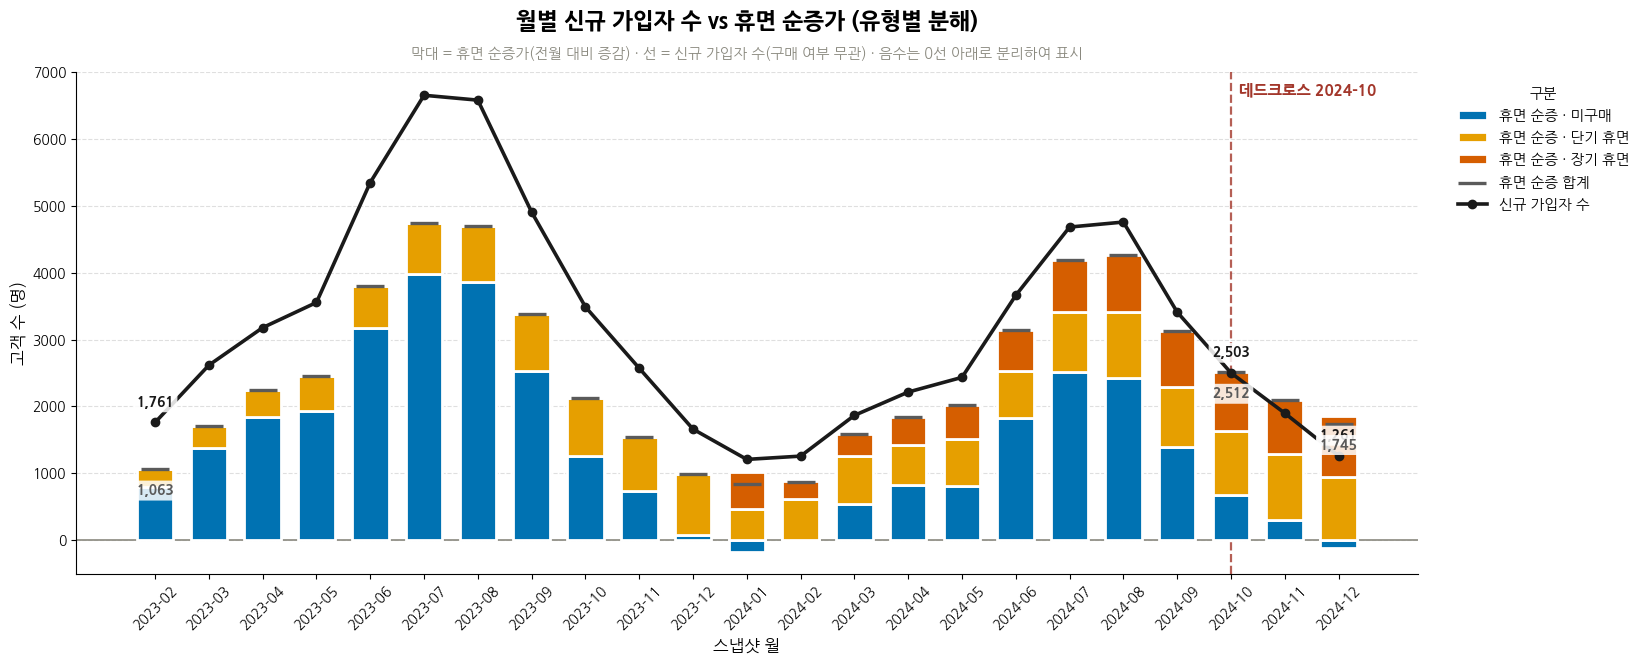

=== 휴면 순증가가 음수인 구간 (휴면에서 빠져나간 수 > 새로 휴면이 된 수) ===


dtype,미구매,단기 휴면,장기 휴면
m,,,
2024-01,-173,464,550
2024-02,-18,608,276
2024-12,-114,947,912


In [ ]:
# =====================================================================================
# [차트] 월별 신규 가입자 수 vs 휴면 순증가 — 휴면 증가를 3유형으로 분해
#
# [설계]
#   · 누적 막대(3유형) = 월별 휴면 순증가, 라인 = 신규 가입자 수.
#   · 막대와 라인의 단위가 같아 단일 축 사용.
#   · 데드크로스 시점을 자동 탐지해 표시.
#   · 이 셀은 앞선 셀에 의존하지 않도록 필요한 값을 자체적으로 계산함.
# =====================================================================================

_PAID = {"Completed", "Processing"}
_DT_ORDER = ["미구매", "단기 휴면", "장기 휴면"]
_DT_COLOR = {"미구매": "#0072B2", "단기 휴면": "#E69F00", "장기 휴면": "#D55E00"}

# ---- 전체 주문 이력 기반 recency + 휴면 유형 ----------------------------------------
_oo = orders_enriched.copy()
_oo["created_at"] = pd.to_datetime(_oo["created_at"], errors="coerce")
if "status" in _oo.columns:
    _oo = _oo[_oo["status"].isin(_PAID)]
_sp = (_oo.dropna(subset=["user_id", "created_at"])
          .groupby("user_id", as_index=False)
          .agg(first_all=("created_at", "min"), last_all=("created_at", "max")))

_ss = snapshots_df[["snapshot_month", "user_id", "segment"]].copy()
_ss["m"] = pd.to_datetime(_ss["snapshot_month"])
_ss["as_of"] = _ss["m"] + pd.offsets.MonthEnd(0)
_ss = _ss.merge(_sp, on="user_id", how="left")
_ss["rec_all"] = (_ss["as_of"] - _ss["last_all"]).dt.days
_isd = _ss["segment"].eq("Dormant")
_ss["dtype"] = np.select(
    [~_isd,
     _isd & (_ss["last_all"].isna() | (_ss["as_of"] < _ss["first_all"])),
     _isd & _ss["rec_all"].between(366, 730),
     _isd & (_ss["rec_all"] > 730)],
    ["(active)", "미구매", "단기 휴면", "장기 휴면"], default="기타")

# ---- 월별 휴면 순증가(유형별) + 신규 가입자 수 ----------------------------------------
_cnt = (_ss[_isd].groupby(["m", "dtype"])["user_id"].nunique()
        .unstack().reindex(columns=_DT_ORDER).fillna(0).sort_index())
_inc = _cnt.diff().iloc[1:]                       # 첫 달은 diff 불가 → 2023-02부터
_new = (_ss.groupby("user_id")["m"].min().value_counts().sort_index()
        .reindex(_inc.index).fillna(0))

# ---- 데드크로스 탐지 -------------------------------------------------------------
_tot_inc = _inc.sum(axis=1)
_cross = _tot_inc[_tot_inc > _new]
_cross_m = _cross.index[0] if len(_cross) else None

# ---- 시각화 ----------------------------------------------------------------------
_x = np.arange(len(_inc))
_total = _inc.sum(axis=1).values
_pos = np.zeros(len(_inc)); _neg = np.zeros(len(_inc))

fig, ax = plt.subplots(figsize=fig_size(6.8))
for k in _DT_ORDER:
    v = _inc[k].values
    base = np.where(v >= 0, _pos, _neg)
    ax.bar(_x, v, bottom=base, width=0.68, color=_DT_COLOR[k],
           label=f"휴면 순증 · {k}", **bar_style())
    _pos = np.where(v >= 0, _pos + v, _pos)
    _neg = np.where(v <  0, _neg + v, _neg)

# 순증 '합계'(대수합) — 양/음이 섞인 달에는 막대 top 이 합계가 아니므로 별도 표시
ax.scatter(_x, _total, marker="_", s=420, linewidths=2.4, color=INK_SECONDARY,
           label="휴면 순증 합계", zorder=7)
ax.plot(_x, _new.values, color=INK_PRIMARY, linewidth=2.6, marker="o", markersize=6,
        label="신규 가입자 수", zorder=8)

_marks = {0, len(_inc) - 1}
if _cross_m is not None:
    _marks.add(list(_inc.index).index(_cross_m))
for i in sorted(_marks):
    ax.annotate(f"{int(_new.values[i]):,}", xy=(_x[i], _new.values[i]), xytext=(0, 12),
                textcoords="offset points", ha="center", fontsize=FS_LABEL + 1,
                fontweight="bold", color=ink(True), bbox=LABEL_BBOX, zorder=10)
    ax.annotate(f"{int(_total[i]):,}", xy=(_x[i], _total[i]), xytext=(0, -18),
                textcoords="offset points", ha="center", fontsize=FS_LABEL + 1,
                fontweight="bold", color=ink(False), bbox=LABEL_BBOX, zorder=10)

if _cross_m is not None:
    xi = list(_inc.index).index(_cross_m)
    ax.axvline(xi, color="#A3372B", linestyle="--", linewidth=1.6, alpha=0.8, zorder=1)
    ax.annotate(f"데드크로스 {_cross_m:%Y-%m}", xy=(xi, ax.get_ylim()[1]), xytext=(6, -16),
                textcoords="offset points", fontsize=FS_SUB + 0.5,
                fontweight="bold", color="#A3372B")

ax.axhline(0, color=INK_MUTED, linewidth=1.2, zorder=2)
ax.set_xticks(_x); ax.set_xticklabels([f"{m:%Y-%m}" for m in _inc.index], rotation=45)
finalize(ax, "월별 신규 가입자 수 vs 휴면 순증가 (유형별 분해)", "스냅샷 월", "고객 수 (명)",
         subtitle="막대 = 휴면 순증가(전월 대비 증감) · 선 = 신규 가입자 수(구매 여부 무관) · 음수는 0선 아래로 분리하여 표시",
         legend_title="구분",
         legend_order=[f"휴면 순증 · {k}" for k in _DT_ORDER] + ["휴면 순증 합계", "신규 가입자 수"])
plt.show()

# ---- 음수 구간 점검 출력 ---------------------------------------------------------------
_negrow = _inc[(_inc < 0).any(axis=1)]
if len(_negrow):
    print("=== 휴면 순증가가 음수인 구간 (휴면에서 빠져나간 수 > 새로 휴면이 된 수) ===")
    _p = _negrow.copy(); _p.index = _p.index.strftime("%Y-%m")
    display(_p.astype(int))


# 3. 휴면(Dormant) 경로 분석

세그먼트별 휴면 전환율, 휴면 전환 고객의 구매가치(R12M), 코호트 구성 통제, At_Risk 유입 경로를 차례로 봅니다.

### 3.1. Dormant는 어떤 구간에서 발생하는가?
`2023-01 부터 2024-12까지 2년의 기간동안 전체 고객 중 Dormant(휴면)의 비율이 57.31%에서 71.73%로 급증.`
- New → Dormant : 거의 불가능 (신규는 최근 구매)
- VIP, Loyal → Dormant : 드묾 (중간 단계가 필요) → VIP와 Loyal의 Recency score는 각 4, 3 이상이고, Dormant는 0이기 때문에 월별 세그먼트가 VIP, Loyal에서 Domant로 바로 이동 불가능.
- `At_Risk → Dormant : 핵심 경로`
- Low_Value → Dormant : 보조 경로

[전환율 정의]
- At_Risk → Dormant 전환율 (t-1 → t, t = 기준 월) = `At_Risk(이탈 위험 고객군) 관리 실패율`
    - 분모: t-1월 기준 At_Risk 고객 수
    - 분자: 그 중 다음 달(t)에 Dormant가 된 고객 수</br>

$\text{Transition Rate}_{t} =\frac{\#(At\_Risk_{t-1} \cap Dormant_{t})}{\#(At\_Risk_{t-1})}$


In [ ]:
# =====================================================================================
#
# [요약 · 전환율 정의]
#   (1) 반복 구간: range(lag, len(months))
#       · 산출 구간: 2023-02 ~ 2024-12
#
#   (2) 결과의 snapshot_month를 '전환이 관측된 월'로 기록.
#       다른 스냅샷 계열(고객 수·R12M·ARPPU)과 x축의 의미가 같아져 겹쳐 그릴 수 있음.
#
#   (3) from_month(t-lag) / to_month(t) 컬럼을 함께 반환 → 기준 월의 모호성 제거.
#
#   (4) lag 인자. lag=1은 직전 달, lag=6은 6개월 전 대비.
#       At_Risk는 recency 181~365일(폭 185일)이므로, 1개월 간격에서는 분모 중
#       약 16%(recency 336~365일)만이 다음 달에 Dormant가 될 수 있음.
#       나머지 84%는 구매를 하지 않아도 물리적으로 전환이 불가능하여 분모에만 남음.
#       → 1개월 전환율은 '유지 실패율'이 아니라 'At_Risk 내부 recency 분포'에 좌우됨.
#       lag=6이면 분모의 약 99%가 전환 가능해져 '행동(재구매 여부)'을 측정하게 됨.
#
#   (5) index_on 인자. "to" = 도착 월 기준(기본), "from" = 출발 월 기준(대조 검증용).
#
# =====================================================================================

def get_transition_rate(
    snapshots_df: pd.DataFrame,
    from_segment: str,
    to_segment: str,
    lag: int = 1,                 # 관측 간격(개월). 1=직전 달, 6=6개월 전 대비
    index_on: str = "to",         # "to"=도착 월 기준(기본), "from"=출발 월 기준(대조 검증용)
) -> pd.DataFrame:
    """
    월별 from_segment -> to_segment 전이율 계산.

    [정의]
      index_on="to" (기본)
          Transition Rate_t = #( from_segment_{t-lag} ∩ to_segment_t ) / #( from_segment_{t-lag} )
          → snapshot_month 는 '전환이 관측된 달'. 처음 lag 개월은 산출 불가.
      index_on="from" (대조 검증용)
          Transition Rate_t = #( from_segment_t ∩ to_segment_{t+lag} ) / #( from_segment_t )
          → snapshot_month 는 '출발 달'. 마지막 lag 개월은 산출 불가.

    Returns:
      snapshot_month   : 기준 월 (index_on 설정에 따라 도착 월 또는 출발 월)
      from_month       : 출발 월 (t-lag)
      to_month         : 도착 월 (t)
      from_segment     : 출발 세그먼트
      to_segment       : 도착 세그먼트
      from_segment_cnt : 출발 세그먼트 고객 수 (분모)
      transitioned_cnt : 전환된 고객 수 (분자)
      transition_rate  : 전이율 (%)
    """
    if index_on not in ("to", "from"):
        raise ValueError(f"index_on은 'to' 또는 'from'이어야 합니다. 입력값: {index_on!r}")
    if lag < 1:
        raise ValueError(f"lag는 1 이상이어야 합니다. 입력값: {lag}")

    df = snapshots_df[["snapshot_month", "user_id", "segment"]].copy()
    df["snapshot_month"] = pd.to_datetime(df["snapshot_month"])

    months = sorted(df["snapshot_month"].unique())

    # 월별 그룹을 dict로 캐싱
    by_month = {m: g for m, g in df.groupby("snapshot_month")}

    records = []

    for i in range(lag, len(months)):
        m_from = months[i - lag]      # t - lag  (출발)
        m_to   = months[i]            # t        (도착) ← 신규 정의의 기준 월

        g_from = by_month.get(m_from)
        g_to   = by_month.get(m_to)
        if g_from is None or g_to is None:
            continue

        from_users = g_from.loc[g_from["segment"] == from_segment, "user_id"]
        to_users   = g_to.loc[g_to["segment"] == to_segment, "user_id"]

        from_segment_cnt = from_users.nunique()

        if from_segment_cnt == 0:
            transitioned_cnt = 0
            transition_rate = 0.0
        else:
            # [수정] merge → 집합 교집합
            transitioned_cnt = len(set(from_users) & set(to_users))
            transition_rate = transitioned_cnt / from_segment_cnt

        records.append({
            # [핵심 수정] 기준 월을 도착 시점으로 기록 (index_on="from"이면 출발 시점)
            "snapshot_month": m_to if index_on == "to" else m_from,
            "from_month": m_from,
            "to_month": m_to,
            "from_segment": from_segment,
            "to_segment": to_segment,
            "from_segment_cnt": from_segment_cnt,
            "transitioned_cnt": transitioned_cnt,
            "transition_rate": round(transition_rate * 100, 2),
        })

    return pd.DataFrame(records)


print("[적용] get_transition_rate 정의 완료 — 기준: t-1 → t (index_on='to', lag=1)")


[적용] get_transition_rate 재정의 완료 — 기준: t-1 → t (index_on='to', lag=1)


In [ ]:
snapshots_df.head()

,snapshot_month,user_id,days_since_signup,age,gender,traffic_source,last_order_dt,recency_days,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_sum,segment
0,2023-01,7,247,30,M,email,2023-01-16 09:17:42,15,15,2636270.0,5,5,5,555,15,VIP
1,2023-01,13,851,27,F,paid_search,2022-02-23 00:52:56,342,1,298400.0,1,1,3,113,5,At_Risk
2,2023-01,15,40,25,M,instagram,NaT,1364,0,0.0,0,0,0,000,0,Dormant
3,2023-01,18,287,24,M,instagram,NaT,1364,0,0.0,0,0,0,000,0,Dormant
4,2023-01,24,331,31,M,organic_search,2022-10-20 19:05:30,103,1,83340.0,3,1,2,312,6,Low_Value


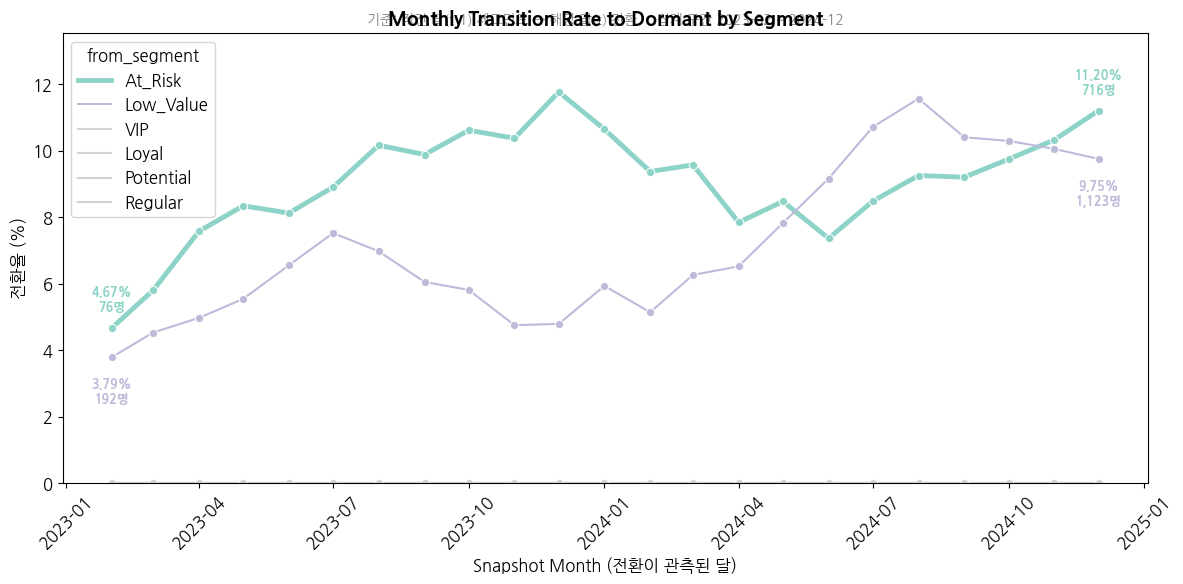

In [ ]:
# =====================================================================================
# [차트]
#   · Monthly Transition Rate to Dormant
# =====================================================================================

dest_segment = "Dormant"
segments = [s for s in snapshots_df["segment"].dropna().unique() if s != dest_segment]

dormant_transition_df = pd.concat(
    [get_transition_rate(snapshots_df, seg, dest_segment) for seg in segments],
    ignore_index=True,
)

target_segments = dormant_transition_df.loc[dormant_transition_df["transition_rate"] > 0, "from_segment"].unique()
size_dict = {seg: 3.5 if seg == "At_Risk" else 1.5 for seg in target_segments}

fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=dormant_transition_df[dormant_transition_df["from_segment"].isin(target_segments)],
    x="snapshot_month",
    y="transition_rate",
    hue="from_segment",
    marker="o",
    size="from_segment",
    sizes=size_dict,
    palette=palette_dict,
    hue_order=target_segments,
    ax=ax,
)

non_target_data = dormant_transition_df[~dormant_transition_df["from_segment"].isin(target_segments)]
if not non_target_data.empty:
    sns.lineplot(
        data=non_target_data,
        x="snapshot_month",
        y="transition_rate",
        hue="from_segment",
        marker="o",
        palette=["lightgray"] * non_target_data["from_segment"].nunique(),
        ax=ax,
    )

for line in ax.get_lines():
    if line.get_label() == "At_Risk":
        line.set_zorder(10)

target_dates = [
    dormant_transition_df["snapshot_month"].min(),
    dormant_transition_df["snapshot_month"].max(),
]

for segment in target_segments:
    for date_val in target_dates:
        subset = dormant_transition_df[
            (dormant_transition_df["from_segment"] == segment)
            & (dormant_transition_df["snapshot_month"] == date_val)
        ]
        if subset.empty:
            continue

        x_val = subset["snapshot_month"].values[0]
        y_val = subset["transition_rate"].values[0]
        cnt_val = subset["transitioned_cnt"].values[0]

        if segment == "Low_Value":
            va, xytext = "top", (0, -15)
        else:
            va, xytext = "bottom", (0, 10)

        ax.annotate(
            f"{y_val:.2f}%\n{cnt_val:,.0f}명",
            xy=(x_val, y_val),
            xytext=xytext,
            textcoords="offset points",
            ha="center",
            va=va,
            fontsize=9,
            fontweight="bold",
            color=palette_dict.get(segment, "black"),
        )

_lo = dormant_transition_df["snapshot_month"].min().strftime("%Y-%m")
_hi = dormant_transition_df["snapshot_month"].max().strftime("%Y-%m")
ax.set_title(f"Monthly Transition Rate to {dest_segment} by Segment", fontsize=14, fontweight="bold")
ax.text(
    0.5, 1.015,
    f"기준: 직전 달(t-1) 세그먼트 → 해당 달(t) 전환  ·  집계 구간 {_lo} ~ {_hi}",
    transform=ax.transAxes, ha="center", va="bottom", fontsize=10, color="gray",
)
ax.set_ylabel("전환율 (%)")
ax.set_xlabel("Snapshot Month (전환이 관측된 달)")
ax.set_ylim(0, dormant_transition_df["transition_rate"].max() * 1.15)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
# =====================================================================================
# [검증]
#   · 앞서 전환율 정의를 t -> t+1 시점 기준에서 t-1 -> t으로 변경하여, 신규 정의로 dormant_transition_df 재생성 + 산출 구간/동치성 검증
#   · lag=1에서 Dormant 증가의 주된 경로인 At_Risk → Dormant 전환율 증가가 At_Risk 고객의 리텐션 관리 실패인지 확인하기 위해 lag=6 확인
# =====================================================================================

# ---- 검증 1) 산출 구간이 2023-02 ~ 2024-12 로 이동했는가 ------------------------------
_min = dormant_transition_df["snapshot_month"].min().strftime("%Y-%m")
_max = dormant_transition_df["snapshot_month"].max().strftime("%Y-%m")
print(f"[검증1] 전환율 산출 구간: {_min} ~ {_max}   (기존 정의는 2023-01 ~ 2024-11)")
assert _max == "2024-12", "최종월(2024-12) 전환율이 산출되지 않았습니다. index_on / lag 설정을 확인하십시오."

# ---- 검증 2) 값은 그대로이고 기준 월만 이동했는가 -------------------------------------
_old = get_transition_rate(snapshots_df, "At_Risk", "Dormant", index_on="from")
_new = get_transition_rate(snapshots_df, "At_Risk", "Dormant", index_on="to")
_cmp = _old.merge(_new, on=["from_month", "to_month"], suffixes=("_old", "_new"))
assert (_cmp["transition_rate_old"] == _cmp["transition_rate_new"]).all(), \
    "정의 변경으로 값 자체가 바뀌었습니다. 인덱싱 로직을 재확인하십시오."
print(f"[검증2] 통과 — 값 동일, 기준 월만 1개월 이동 ({len(_cmp)}개 시점 대조)")

# ---- 보고서 전사용: At_Risk → Dormant 양 끝점 ---------------------------------------
_ar = dormant_transition_df.query("from_segment == 'At_Risk'").sort_values("snapshot_month")
print("\n=== At_Risk → Dormant (보고서 전사용) ===")
display(_ar.iloc[[0, -1]][["snapshot_month", "from_month", "from_segment_cnt",
                           "transitioned_cnt", "transition_rate"]])

# =====================================================================================
# [At_Risk 세그먼트 관리 실패 검증]
#   1개월 간격은 분모(At_Risk)의 약 16%만 휴면(Dormant) 전환 가능하여 'At_Risk 내부 recency 분포'를 반영하지만,
#   6개월 간격은 분모의 약 99%가 전환 가능하여 '재구매하지 않은 비율' = 유지 실패율에 해당함.
#   두 지표는 대체가 아니라 병기 관계:
#     · lag=1 → 월 단위 이탈 인원 / 손실액 산정
#     · lag=6 → At_Risk 고객의 최종 유지 실패율 / 개선 목표 설정
# =====================================================================================
dormant_transition_6m_df = pd.concat(
    [get_transition_rate(snapshots_df, seg, dest_segment, lag=6) for seg in segments],
    ignore_index=True,
)

_ar6 = dormant_transition_6m_df.query("from_segment == 'At_Risk'").sort_values("snapshot_month")
print("\n=== At_Risk → Dormant · 6개월 간격 (lag=6) ===")
print(f"산출 구간: {_ar6['snapshot_month'].min():%Y-%m} ~ {_ar6['snapshot_month'].max():%Y-%m}")
display(_ar6.iloc[[0, -1]][["snapshot_month", "from_month", "from_segment_cnt",
                            "transitioned_cnt", "transition_rate"]])


[검증1] 전환율 산출 구간: 2023-02 ~ 2024-12   (기존 정의는 2023-01 ~ 2024-11)
[검증2] 통과 — 값 동일, 기준 월만 1개월 이동 (23개 시점 대조)

=== At_Risk → Dormant (보고서 전사용) ===


,snapshot_month,from_month,from_segment_cnt,transitioned_cnt,transition_rate
23,2023-02-01,2023-01-01,1629,76,4.67
45,2024-12-01,2024-11-01,6392,716,11.20



=== At_Risk → Dormant · 6개월 간격 (lag=6) ===
산출 구간: 2023-07 ~ 2024-12


,snapshot_month,from_month,from_segment_cnt,transitioned_cnt,transition_rate
18,2023-07-01,2023-01-01,1629,1554,95.40
35,2024-12-01,2024-06-01,6096,6025,98.84


In [ ]:
# =====================================================================================
#
# [차트] 세그먼트 전환율 추이  — 노션 2-3절 (유입·유출 공용)
#
#   by="from" (기본) : 계열 = 출발 세그먼트, 고정 = 도착 세그먼트(focus_segment)
#                     "무엇이 Dormant 로 흘러드는가"
#   by="to"          : 계열 = 도착 세그먼트, 고정 = 출발 세그먼트(focus_segment)
#                     "At_Risk 고객은 어디로 가는가"
#
#   by="to" 에서는 한 달의 전환율 합이 100%가 된다(모든 고객이 어딘가의 세그먼트에 속하므로).
#   따라서 exclude_self=True 로 잔존(At_Risk→At_Risk)을 빼면 합이 100%에 못 미치며,
#   그 차이가 곧 잔존율이다.
#
# =====================================================================================
def plot_transition_themed(df, focus_segment, main_segs, label_below=(), title=None,
                           exclude_self=True, by="from"):
    """세그먼트 전환율 월별 추이.

    df            : get_transition_rate() 결과(들)를 concat 한 데이터프레임
    focus_segment : by="from"이면 '도착' 세그먼트, by="to"이면 '출발' 세그먼트
    main_segs     : 이 차트에서 강조할 계열(Layer 3). main_segs[0]이 최우선 메시지
    by            : "from"=유입 관점(계열이 출발지) / "to"=유출 관점(계열이 도착지)
    """
    if by not in ("from", "to"):
        raise ValueError(f"by는 'from' 또는 'to'여야 합니다. 입력값: {by!r}")
    series_col = "from_segment" if by == "from" else "to_segment"

    segs = df.loc[df["transition_rate"] > 0, series_col].unique().tolist()
    if exclude_self:
        segs = [s for s in segs if s != focus_segment]          # 잔존율 제외
    segs = [s for s in SEGMENT_ORDER if s in segs] + [s for s in segs if s not in SEGMENT_ORDER]
    if not segs:
        raise ValueError("그릴 계열이 없습니다. focus_segment / by 설정을 확인하십시오.")

    d = df[df[series_col].isin(segs)]
    fig, ax = plt.subplots(figsize=fig_size(7))
    for seg in segs:
        g = d[d[series_col] == seg].sort_values("snapshot_month")
        ax.plot(g["snapshot_month"], g["transition_rate"], marker="o",
                color=PALETTE_SEG[seg], label=seg,
                **line_style(seg, primary=main_segs, secondary=[]))

    lo, hi = d["snapshot_month"].min(), d["snapshot_month"].max()
    for seg in [s for s in segs if s in main_segs]:
        is_main = seg == main_segs[0]
        for m in (lo, hi):
            row = d[(d[series_col] == seg) & (d["snapshot_month"] == m)]
            if row.empty:
                continue
            y, cnt = row["transition_rate"].values[0], row["transitioned_cnt"].values[0]
            va, dy = ("top", -14) if seg in label_below else ("bottom", 12)
            ax.annotate(f"{y:.2f}%\n{cnt:,.0f}명", xy=(m, y), xytext=(0, dy),
                        textcoords="offset points", ha="center", va=va,
                        fontsize=FS_LABEL, fontweight="bold" if is_main else "normal",
                        color=ink(is_main), bbox=LABEL_BBOX, zorder=10)

    ax.set_ylim(0, d["transition_rate"].max() * 1.20)
    _self = "  ·  잔존(자기 전환) 계열 제외" if exclude_self else ""
    _basis = (f"기준: 직전 달(t-1) 세그먼트 → 해당 달(t) {focus_segment} 전환" if by == "from"
              else f"기준: 직전 달(t-1) {focus_segment} 고객이 해당 달(t)에 각 세그먼트로 이동한 비율")
    _deft  = (f"세그먼트별 {focus_segment} 전환율 월별 추이" if by == "from"
              else f"{focus_segment} 고객의 세그먼트별 이동 비율 월별 추이")
    finalize(ax, title or _deft,
             "스냅샷 월 (전환이 관측된 달)", "전환율 (%)",
             subtitle=f"{_basis}  ·  집계 구간 {lo:%Y-%m} ~ {hi:%Y-%m}{_self}",
             unit_fmt="{:,.0f}", xtick_rotation=45)
    plt.show()


# --- Layer 3: 이 차트는 At_Risk 가 메시지, Low_Value 라벨은 아래로 --------------------
plot_transition_themed(dormant_transition_df, "Dormant",
                       main_segs=["At_Risk", "Low_Value"], label_below=("Low_Value",),
                       title="세그먼트별 휴면(Dormant) 전환율 월별 추이")


### 3.2. 공통 전이·R12M 검증

- 각 월말 스냅샷의 Monetary를 원자료의 최근 365일 구매금액과 대조합니다.
- 주문 Completed·Processing, 상품 Purchased·Shipped·Packing 기준입니다.
- 전이는 인접한 두 월의 동일 고객을 연결하며 출발월 구매금액을 사용합니다.

In [ ]:
# [C02~C04 공통] 출발월 상태·365일 구매금액을 보존한 월별 전이
# 선행: 공통 테마, snapshots_df, orders_enriched. 기존 전역 pair는 덮어쓰지 않는다.

c234_out = Path(globals().get('C234_OUTPUT_DIR', '../outputs'))
c234_out.mkdir(parents=True, exist_ok=True)
c234_snap = snapshots_df[['snapshot_month','user_id','segment','monetary']].copy()
c234_snap['month'] = pd.to_datetime(c234_snap['snapshot_month'])
assert not c234_snap.duplicated(['user_id','month']).any()
assert c234_snap[['segment','monetary']].notna().all().all()
assert set(c234_snap.segment).issubset(SEGMENT_ORDER)
c234_months = pd.date_range(c234_snap.month.min(), c234_snap.month.max(), freq='MS')
assert set(c234_snap.month.unique()) == set(c234_months)

# 스냅샷 Monetary를 주문 원자료의 같은 365일 구간과 대조한다.
c234_orders = orders_enriched.copy()
c234_orders['created_at'] = pd.to_datetime(c234_orders['created_at'])
c234_orders = c234_orders[c234_orders.status.isin({'Completed','Processing'})]
assert not c234_orders.id.duplicated().any()
for month, group in c234_snap.groupby('month'):
    end = month + pd.offsets.MonthBegin(1)
    start = end - pd.Timedelta(days=365)
    observed = c234_orders.loc[c234_orders.created_at.ge(start) & c234_orders.created_at.lt(end)]
    amounts = observed.groupby('user_id').order_amount.sum()
    expected = group.user_id.map(amounts).fillna(0).to_numpy()
    assert np.allclose(group.monetary, expected, rtol=1e-12, atol=.01), f'R12M 불일치: {month}'

c234_from = c234_snap[['user_id','month','segment','monetary']].rename(columns={
    'month':'from_month','segment':'from_segment','monetary':'from_r12m'})
c234_from['to_month'] = c234_from.from_month + pd.offsets.MonthBegin(1)
c234_to = c234_snap[['user_id','month','segment']].rename(columns={'month':'to_month','segment':'to_segment'})
c234_pair = c234_from.merge(c234_to, on=['user_id','to_month'], how='inner', validate='one_to_one')
expected_pairs = c234_from[c234_from.to_month.le(c234_snap.month.max())]
assert len(c234_pair) == len(expected_pairs), '다음 월 고객 스냅샷 누락'
c234_den = c234_from.groupby(['to_month','from_segment']).user_id.nunique().rename('source_n')

def c234_transition_summary(destination, origins):
    transitions = c234_pair[c234_pair.to_segment.eq(destination) & c234_pair.from_segment.isin(origins)]
    index = pd.MultiIndex.from_product([c234_months[1:],origins],names=['to_month','from_segment'])
    summary = transitions.groupby(['to_month','from_segment']).agg(
        n=('user_id','nunique'),r12m_sum=('from_r12m','sum')).reindex(index,fill_value=0)
    summary = summary.join(c234_den)
    assert summary.source_n.notna().all()
    assert summary.n.le(summary.source_n).all()
    summary['rate_pct'] = np.where(summary.source_n.gt(0),summary.n/summary.source_n*100,np.nan)
    summary['r12m_mean'] = np.where(summary.n.gt(0),summary.r12m_sum/summary.n,np.nan)
    return summary.reset_index()

print(f'C02~C04 공통 검증: {len(c234_snap):,}개 고객-월 R12M 원자료 일치 / {len(c234_pair):,}개 인접월 전이')


C02~C04 공통 검증: 1,671,354개 고객-월 R12M 원자료 일치 / 1,567,706개 인접월 전이


### 3.3. 실제 휴면 전환 고객의 출발월 R12M

- At_Risk와 Low_Value를 비교하며, 각 월의 실제 전환자 개인별 출발월 365일 금액을 합산합니다.
- 재활성화 후 다른 월에 재전환한 고객은 다시 포함될 수 있으므로 월별 금액을 연간 매출·미래 손실로 합산하지 않습니다.

     to_month from_segment     n     r12m_sum  source_n   rate_pct      r12m_mean
0  2023-02-01      At_Risk    76   25389440.0      1629   4.665439  334071.578947
1  2023-02-01    Low_Value   192   14365970.0      5061   3.793717   74822.760417
44 2024-12-01      At_Risk   716  294140460.0      6392  11.201502  410810.698324
45 2024-12-01    Low_Value  1123  102441880.0     11517   9.750803   91221.620659

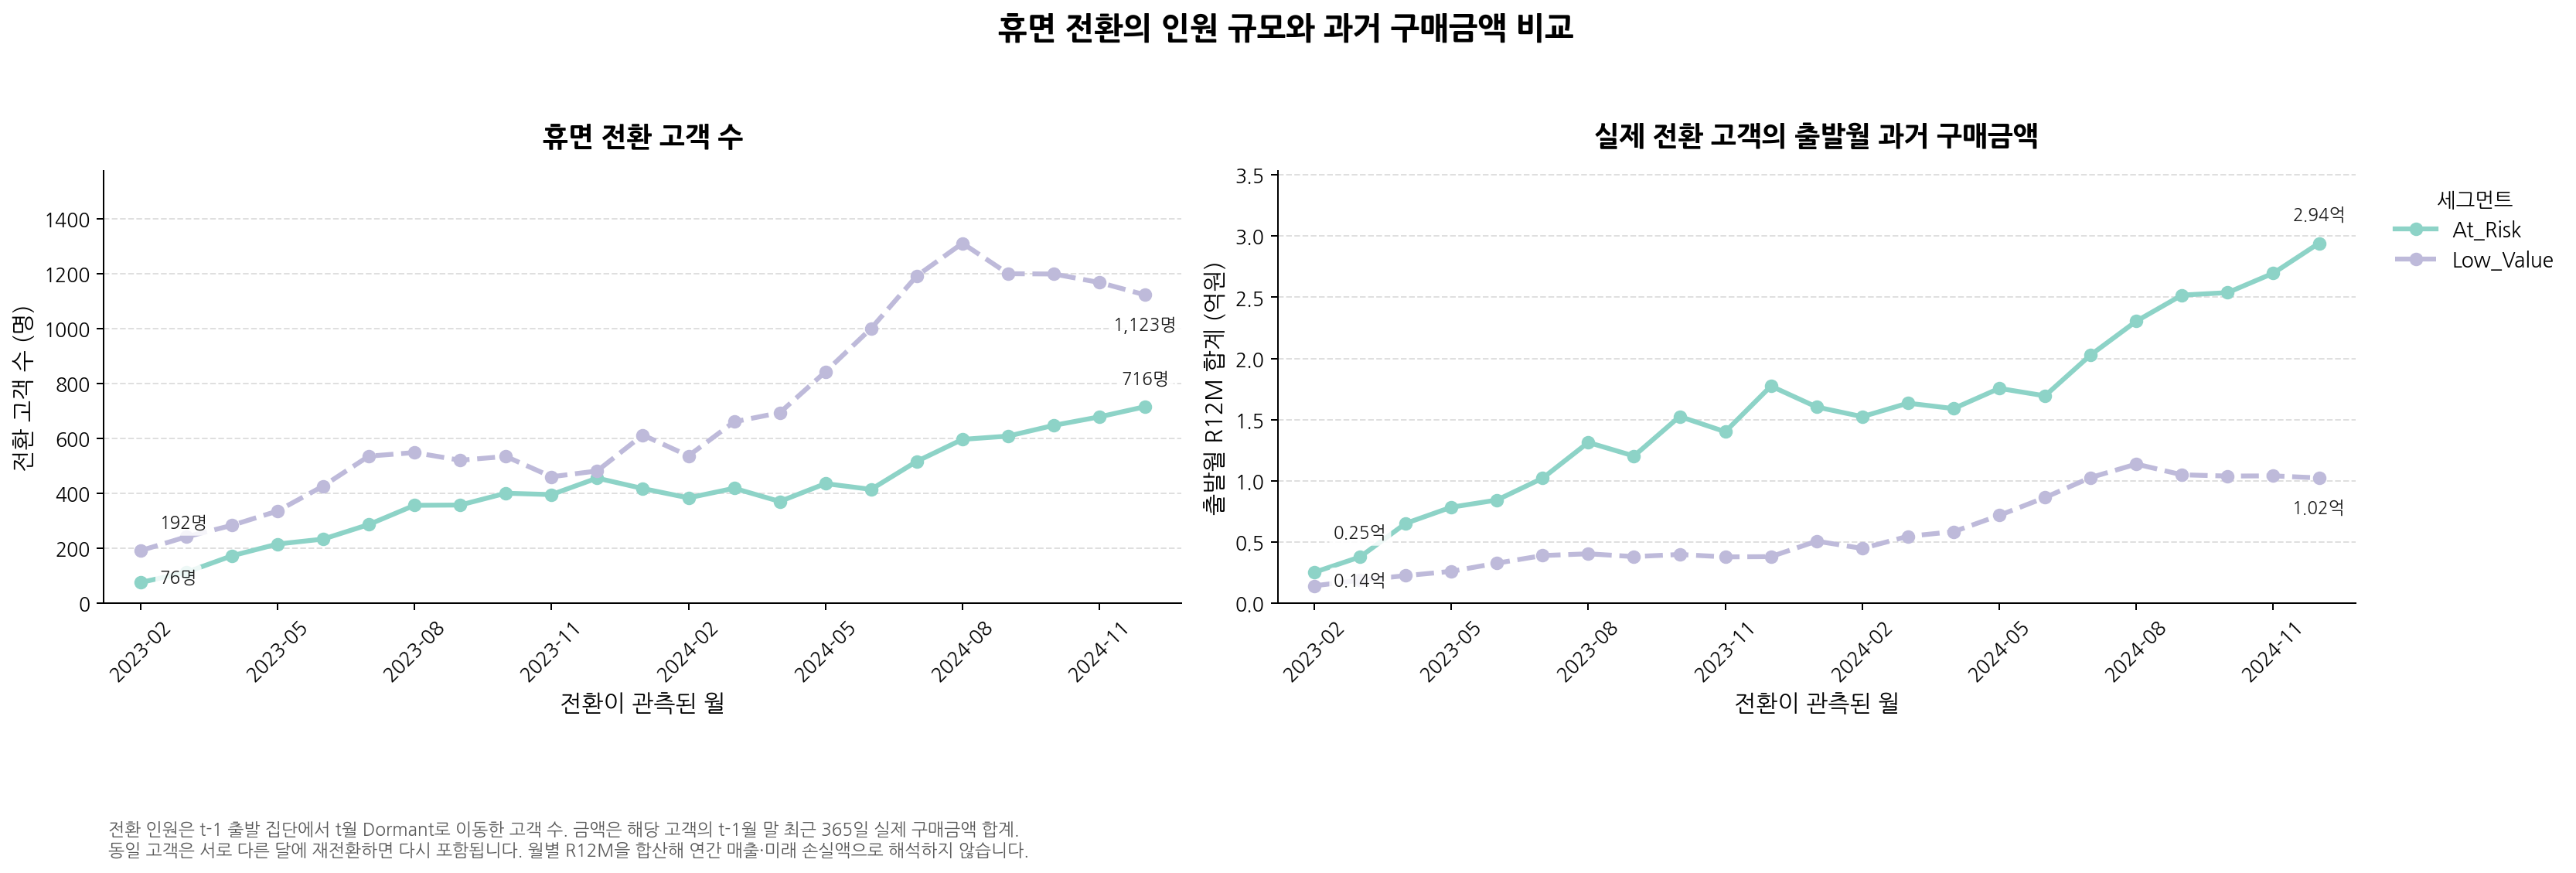

In [1]:
# [C04] 실제 휴면 전환자의 출발월 R12M. 전체 At_Risk 평균을 대신 곱하지 않는다.
c04_origins=['At_Risk','Low_Value']
c04_monthly=c234_transition_summary('Dormant',c04_origins)
c04_monthly.to_csv(c234_out/'c04_dormant_transition_monthly.csv',index=False)
c04_other=c234_pair[c234_pair.to_segment.eq('Dormant')&~c234_pair.from_segment.isin(['Dormant']+c04_origins)]
assert c04_other.empty, '추가 휴면 전환 출발 집단이 존재합니다.'
fig_c04,axes_c04=plt.subplots(1,2,figsize=fig_size(6.4,plot_w=FIG_W_2PANE,legends=1))
c04_dates=c234_months[1:];c04_x=np.arange(len(c04_dates))
for j,(col,div,title,ylabel) in enumerate([
    ('n',1,'휴면 전환 고객 수','전환 고객 수 (명)'),
    ('r12m_sum',1e8,'실제 전환 고객의 출발월 과거 구매금액','출발월 R12M 합계 (억원)')]):
    ax=axes_c04[j]
    for seg in c04_origins:
        d=c04_monthly[c04_monthly.from_segment.eq(seg)].set_index('to_month').reindex(c04_dates)
        vals=d[col]/div
        ax.plot(c04_x,vals,label=seg,color=PALETTE_SEG[seg],marker='o',linewidth=2.5,
                linestyle='-' if seg=='At_Risk' else '--')
        for i in [0,len(c04_x)-1]:
            label=f'{vals.iloc[i]:,.0f}명' if j==0 else f'{vals.iloc[i]:.2f}억'
            offset=((10,0 if seg=='At_Risk' else 12) if j==0 else (10,18 if seg=='At_Risk' else 0)) if i==0 else (0,12 if seg=='At_Risk' else -18)
            ax.annotate(label,(i,vals.iloc[i]),xytext=offset,
                        textcoords='offset points',fontsize=FS_LABEL,color=INK_PRIMARY,ha='left' if i==0 else 'center',bbox=LABEL_BBOX)
    ax.set_xticks(c04_x[::3],[d.strftime('%Y-%m') for d in c04_dates[::3]])
    ax.set_ylim(bottom=0,top=c04_monthly[col].max()/div*1.2)
    ax.set_xlim(-.8,len(c04_x)-.2)
    finalize(ax,title,'전환이 관측된 월',ylabel,panel=True,legend=(j==1),
             legend_order=c04_origins,xtick_rotation=45,layout=False)
fig_c04.suptitle('휴면 전환의 인원 규모와 과거 구매금액 비교',fontsize=FS_TITLE,fontweight='bold')
fig_c04.text(.045,.035,
    '전환 인원은 t-1 출발 집단에서 t월 Dormant로 이동한 고객 수. 금액은 해당 고객의 t-1월 말 최근 365일 실제 구매금액 합계.\n'
    '동일 고객은 서로 다른 달에 재전환하면 다시 포함됩니다. 월별 R12M을 합산해 연간 매출·미래 손실액으로 해석하지 않습니다.',
    fontsize=FS_LABEL,color=INK_SECONDARY)
fig_c04.tight_layout(rect=(0,.17,1,.94))
fig_c04.savefig(c234_out/'c04_dormant_transition_value.png',dpi=180,bbox_inches='tight',facecolor='white')
display(c04_monthly[c04_monthly.to_month.isin([c04_dates[0],c04_dates[-1]])])
plt.show()


<!--
## C03 보완 초안 · 12개월 추적 포함/제외 고객의 진입 특성 비교

기존 12개월 경로 분석의 고객당 **관측상 첫 VIP→Loyal 진입** 정의를 그대로 재현합니다. 포함 여부는 2024-12 관측 종료일에 따라 정하며, 비교 특성은 모두 **Loyal 진입월 말** 값입니다. 진입 이후 결과를 특성으로 사용하지 않습니다.

- R: 마지막 구매 후 경과일, F: 최근 365일 주문 수, M: 최근 365일 구매금액. 구매금액과 주문 수는 M/F와 같은 지표이므로 중복 집계하지 않습니다.
- 각 지표의 평균·표준편차·P10/P25/중앙값/P75/P90, 표준화 평균차(SMD), 누적분포 최대 차이를 출력합니다. R/F/M 점수별 비중과 월별 진입 인원도 출력합니다.
- SMD는 (제외 평균−포함 평균) / 두 집단 분산 평균의 제곱근입니다. 크기와 분포를 기술적으로 비교하며, 유사성 검정이나 인과 추론으로 해석하지 않습니다.
- 저장된 snapshots_df.parquet를 독립적으로 읽으며 기존 분석 셀과 결과는 수정하지 않습니다.

-->

<!--
### 초안 해석

**진입 당시의 구매 특성은 대체로 비슷하지만, 서로 다른 연도의 진입 고객이다.**

- 포함 5,098명은 2023-02~12 진입, 제외 9,293명은 2024-01~12 진입이다. 제외 고객은 데이터 종료일까지 0~11개월만 관측 가능하다. 중간 월 누락으로 제외된 고객은 없다.
- 구매 공백 중앙값은 두 집단 모두 105일(중앙 50% 97~113일), 주문 횟수는 모두 8회(6~10회)다. 구매금액 중앙값은 115.7만→120.4만원, 가입 경과일 중앙값은 336→362일이다.
- 원지표 4개의 절대 SMD는 0.025~0.080이다. 가입 경과일의 누적분포 최대 차이는 7.33%p로 구매 지표의 1.46~3.48%p보다 크다. M 점수 5점 비중도 69.36%와 63.78%로 5.58%p 차이가 있다. 점수와 원금액은 함께 해석한다.
- 관측한 특성에서 큰 평균 차이는 발견되지 않았지만, 진입 연도가 완전히 분리되어 시기 효과를 분리할 수 없다. **97.47%는 2023년 진입 완전 관측 고객에게서 확인한 두 주요 휴면 경로의 비중**으로 유지한다. 특성 유사성은 2024년 진입자의 동일한 12개월 결과를 보장하지 않는다.

이번 보완은 포함/제외 집단의 기초 특성 비교이다. 생존분석 및 미래 휴면율 추정은 수행하지 않았다.

-->

<!--
## C03 보완 · 포함/제외 고객 특성 분포 차트

앞선 비교 집계와 공통 테마 셀을 실행한 뒤 사용합니다. 공통 비세그먼트 색상·서체를 사용하고 화면 가독성을 위해 10×6.5인치, 12~17pt로 조정했습니다. 점은 중앙값, 굵은 선은 P25~P75, 가는 선은 P10~P90입니다. 신뢰구간이 아닌 고객 분포 구간입니다.
-->

### 3.4. 세그먼트별 연간 매출이 많이 발생하는 세그먼트와 그 추이는?

In [462]:
def segment_monthly_sales(
    snapshots_df: pd.DataFrame,
    orders_enriched: pd.DataFrame,
) -> pd.DataFrame:
    """
    연산 효율성을 극대화한 snapshot_month별 segment별 1-year lookback 매출 집계 함수
    """
    # 1. 주문 데이터 사전 준비 (필요 컬럼만 추출, 타입 변환 및 결측치 제거)
    orders_dt = orders_enriched[["user_id", "created_at", "order_amount"]].copy()
    orders_dt["created_at"] = pd.to_datetime(orders_dt["created_at"], errors="coerce")
    orders_dt = orders_dt.dropna(subset=["created_at"])
    
    # 2. 스냅샷 데이터 월별 그룹화 (매 반복 시 탐색 비용을 O(1)로 줄이기 위해 dict로 캐싱)
    snapshots_grouped = dict(tuple(snapshots_df[["snapshot_month", "user_id", "segment"]].groupby("snapshot_month")))
    unique_months = snapshots_df["snapshot_month"].unique()
    
    results = []
    
    # 3. 기준월(snapshot_month) 단위로 순회 (Cartesian Product 원천 차단)
    for month in unique_months:
        # 기준월에 대한 Lookback 윈도우(해당 월 말일 기준 최근 365일) 계산
        month_end = pd.to_datetime(month) + pd.offsets.MonthEnd(0) + pd.Timedelta(days=1)
        month_start = month_end - pd.Timedelta(days=365)
        
        # 가. 해당 월의 Lookback 기간 내에 발생한 주문만 1차 필터링
        mask = (orders_dt["created_at"] >= month_start) & (orders_dt["created_at"] < month_end)
        valid_orders = orders_dt[mask]
        
        # 나. "유저별 총 주문금액"으로 우선 집계 (유저 1명당 최대 1행으로 압축)
        user_sales = valid_orders.groupby("user_id", as_index=False)["order_amount"].sum()
        
        # 다. 기준월의 스냅샷 데이터 가져오기
        month_snapshots = snapshots_grouped.get(month)
        if month_snapshots is None:
            print(f"No snapshots found for {month}")
            continue
            
        # 라. 스냅샷 데이터와 압축된 유저별 주문 금액 조인 (완벽한 1:1 매핑 연산)
        merged = month_snapshots.merge(user_sales, on="user_id", how="left")
        
        # 마. 해당 월의 세그먼트별 매출 최종 집계 (결측치(NaN)는 자동으로 제외)
        month_segment_sales = merged.groupby(["snapshot_month", "segment"], as_index=False)["order_amount"].sum()
        
        results.append(month_segment_sales)
        
    # 예외: 유효한 데이터가 없을 경우 빈 DataFrame 반환 방어 코드
    if not results:
        return pd.DataFrame(columns=["snapshot_month", "segment", "segment_sales"])
        
    # 4. 결과 병합 및 컬럼명 일치화
    final_result = pd.concat(results, ignore_index=True)
    final_result.rename(columns={"order_amount": "segment_sales"}, inplace=True)
    
    return final_result

In [463]:
segment_monthly_sales_df = segment_monthly_sales(snapshots_df, orders_enriched)
segment_monthly_sales_df.head(7)

,snapshot_month,segment,segment_sales
0,2023-01,At_Risk,1.018753e+09
1,2023-01,Dormant,0.000000e+00
2,2023-01,Low_Value,3.936822e+08
3,2023-01,Loyal,1.822605e+09
4,2023-01,Potential,1.652384e+08
5,2023-01,Regular,1.669777e+08
6,2023-01,VIP,3.130263e+09


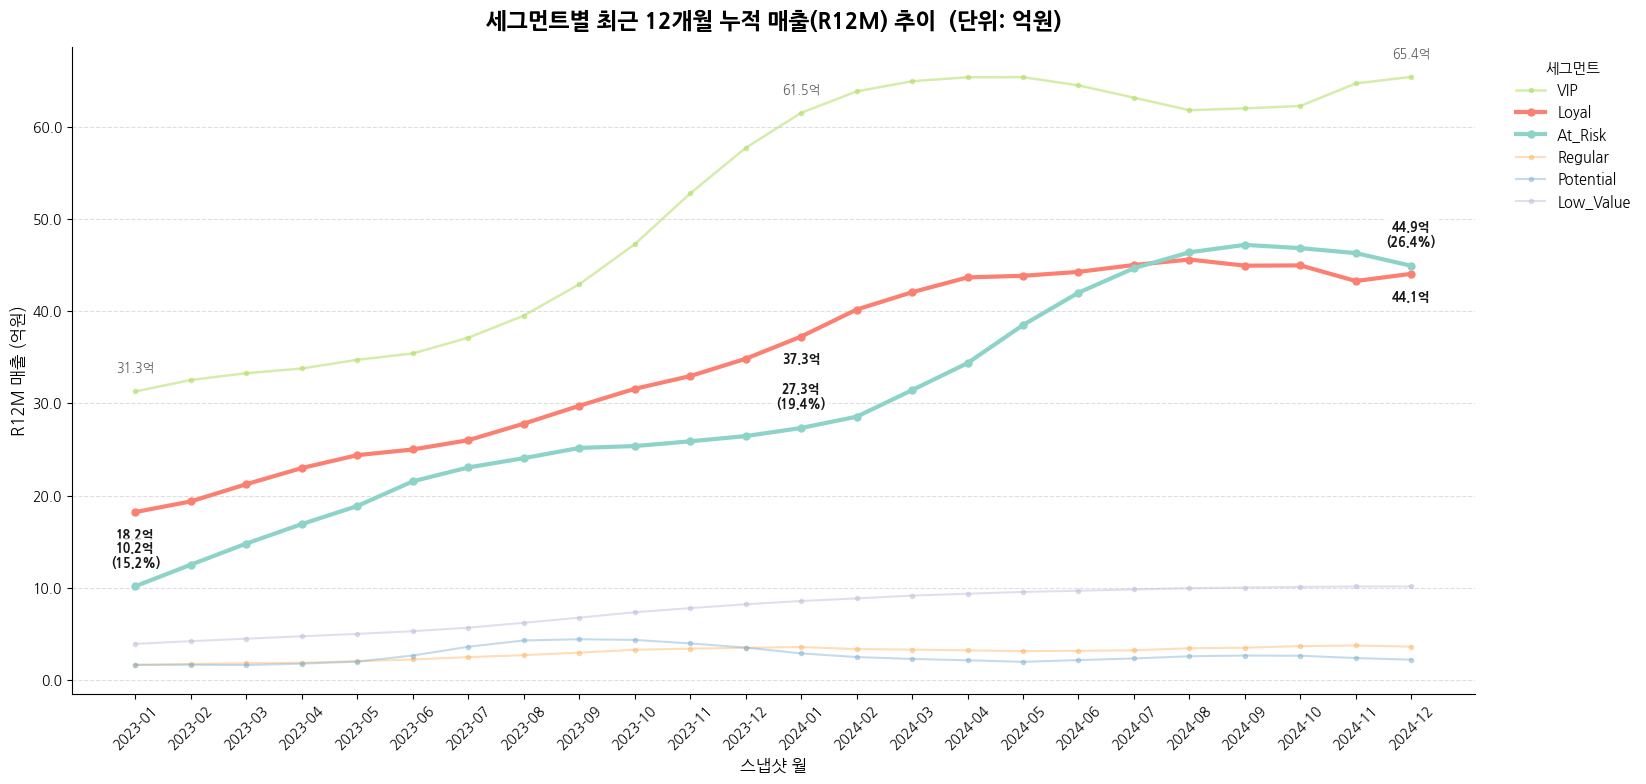

In [ ]:
# =====================================================================================
# [차트] 세그먼트별 최근 12개월 누적 매출(R12M) 추이  — 노션 2-4절
# =====================================================================================

UNIT_DIV, UNIT_SUFFIX, UNIT_FMT = 1e8, "억", "{:,.1f}"
_PRIMARY  = ["Loyal", "At_Risk"]
_ANNOTATE = ["VIP", "Loyal", "At_Risk"]

_d9 = segment_monthly_sales_df[segment_monthly_sales_df["segment"] != "Dormant"].copy()
_d9["v"] = _d9["segment_sales"] / UNIT_DIV
_tot9 = _d9.groupby("snapshot_month")["v"].sum().rename("tot")
_d9 = _d9.merge(_tot9, on="snapshot_month")
_d9["ratio"] = _d9["v"] / _d9["tot"] * 100

_mo = sorted(_d9["snapshot_month"].unique())
_pts = [m for m in [_mo[0], next((m for m in _mo if "2024-01" in str(m)), None), _mo[-1]] if m]

fig, ax = plt.subplots(figsize=fig_size(8))
for seg in [s for s in SEGMENT_ORDER if s in set(_d9["segment"])]:
    g = _d9[_d9["segment"] == seg].sort_values("snapshot_month")
    ax.plot([_mo.index(m) for m in g["snapshot_month"]], g["v"], marker="o",
            color=PALETTE_SEG[seg], label=seg,
            **line_style(seg, primary=_PRIMARY, secondary=["VIP"]))

for seg in _ANNOTATE:
    g = _d9[_d9["segment"] == seg]
    is_main = seg in _PRIMARY
    for m in _pts:
        r = g[g["snapshot_month"] == m]
        if r.empty:
            continue
        y = r["v"].values[0]
        txt = UNIT_FMT.format(y) + UNIT_SUFFIX
        if seg == "At_Risk":
            txt += f"\n({r['ratio'].values[0]:.1f}%)"
        va, dy = ("top", -12) if seg == "Loyal" else ("bottom", 12)
        ax.annotate(txt, xy=(_mo.index(m), y), xytext=(0, dy), textcoords="offset points",
                    ha="center", va=va, fontsize=FS_LABEL,
                    fontweight="bold" if is_main else "normal",
                    color=ink(is_main), bbox=LABEL_BBOX, zorder=10)

ax.set_xticks(range(len(_mo))); ax.set_xticklabels([str(m) for m in _mo], rotation=45)
finalize(ax, f"세그먼트별 최근 12개월 누적 매출(R12M) 추이  (단위: {UNIT_SUFFIX}원)",
         "스냅샷 월", f"R12M 매출 ({UNIT_SUFFIX}원)", unit_fmt=UNIT_FMT)
plt.show()


### 3.5. 코호트 규모 통제 검증  `[A3]`

세그먼트 모수는 각 시점까지 가입한 **전체 회원**이므로 시간에 따라 단조 증가한다(2023-01 30,127명 → 2024-12 약 103,600명, 약 3.4배).
모수가 3.4배 팽창한 시계열에서 전환율이 상승했다는 사실만으로는 **행동이 나빠진 것인지, 고객 구성이 바뀐 것인지** 구분할 수 없다.

- **구성 효과 가설** — 2023년에 대량 유입된 코호트가 시간이 지나며 `At_Risk` 후반부(recency 만료 임박 구간)로 이동했을 뿐, 개인의 재구매 확률은 그대로다.
- **행동 악화 가설** — 코호트 구성을 고정해도 전환율이 상승한다. 즉 실제로 유지력이 나빠졌다.

매출 분석의 리텐션 히트맵은 "코호트별 구매 지속 패턴은 유입 시기와 무관하게 유사하다"고 결론지었으므로, **구성 효과 가설이 맞다면 두 분석이 정합**하고, **행동 악화 가설이 맞다면 히트맵이 포착하지 못한 변화가 존재**한다는 뜻이 된다.

아래에서는 ① 가입 코호트를 고정한 전환율 추적, ② 직접 표준화(direct standardization)를 통한 구성/행동 효과 분해, ③ 가입 후 경과기간(tenure) 통제 세 가지로 이를 판정한다.

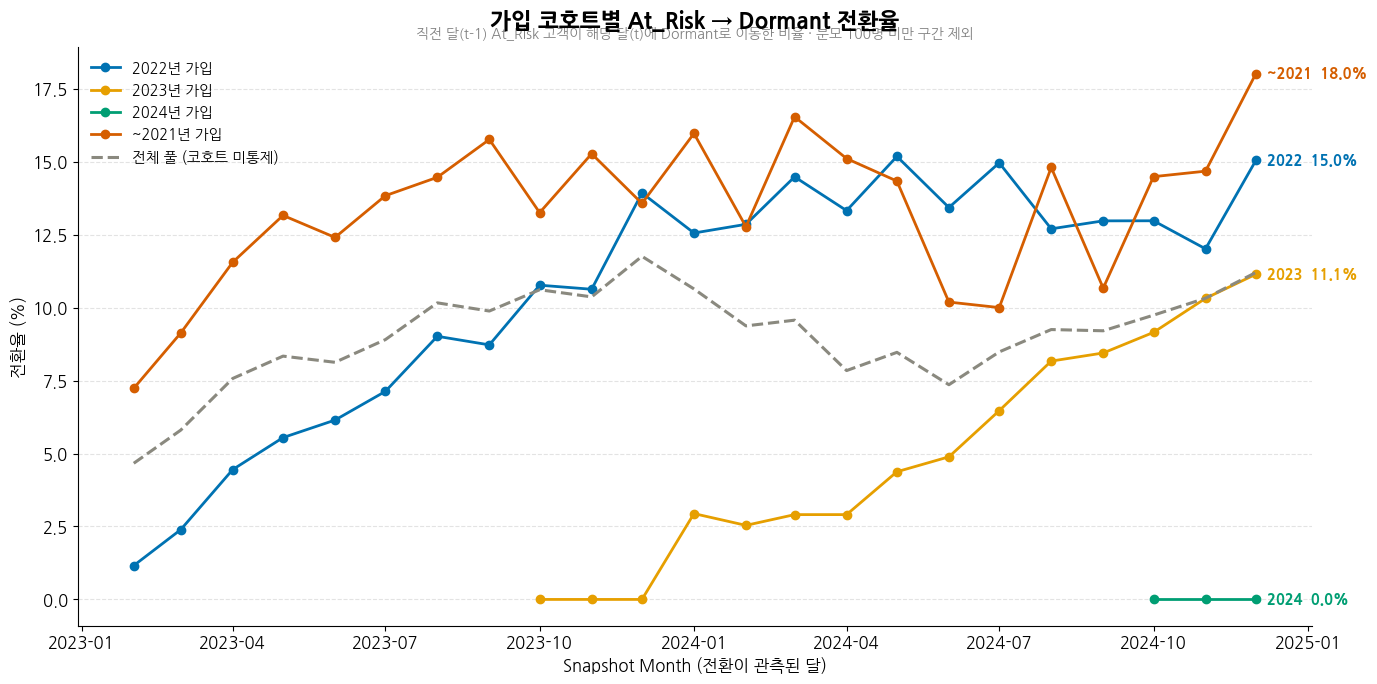

=== 코호트 고정 시 전환율 변화 ===


,가입 코호트,시작,시작 전환율(%),종료,종료 전환율(%),변화(%p)
0,2022,2023-02,1.16,2024-12,15.04,13.88
1,2023,2023-10,0.00,2024-12,11.14,11.14
2,2024,2024-10,0.00,2024-12,0.00,0.00
3,~2021,2023-02,7.23,2024-12,18.01,10.78


In [ ]:
# =====================================================================================
# [차트] 가입 코호트를 고정한 At_Risk → Dormant 전환율 추적
#
# 전체 풀의 전환율은 코호트 구성 변화에 오염된다. 코호트를 고정하면 그 안에서의
# 전환율 변화는 '행동' 변화만을 반영한다.
# =====================================================================================
FROM_SEG, TO_SEG = "At_Risk", "Dormant"
MIN_N = 100     # 분모가 작은 코호트-월은 노이즈가 크므로 시각화에서 제외

sub = pair[pair["seg_prev"] == FROM_SEG].copy()
sub["is_to"] = (sub["seg_cur"] == TO_SEG)

coh = (sub.groupby(["month_cur", "signup_cohort"], as_index=False)
          .agg(n=("user_id", "size"), k=("is_to", "sum")))
coh["rate"] = coh["k"] / coh["n"] * 100

coh_plot = coh[coh["n"] >= MIN_N]
cohorts = sorted(coh_plot["signup_cohort"].unique())

fig, ax = plt.subplots(figsize=(14, 7))
for i, c in enumerate(cohorts):
    g = coh_plot[coh_plot["signup_cohort"] == c].sort_values("month_cur")
    color = CAT_COLORS[i % len(CAT_COLORS)]
    ax.plot(g["month_cur"], g["rate"], marker="o", markersize=6, linewidth=2,
            color=color, label=f"{c}년 가입")
    last = g.iloc[-1]
    ax.annotate(f"{c}  {last['rate']:.1f}%", xy=(last["month_cur"], last["rate"]),
                xytext=(8, 0), textcoords="offset points", va="center",
                fontsize=10.5, fontweight="bold", color=color)

# 전체 풀 기준(코호트 미통제) 전환율을 회색 기준선으로 함께 표시
overall = coh.groupby("month_cur").apply(lambda g: g["k"].sum() / g["n"].sum() * 100)
ax.plot(overall.index, overall.values, linestyle="--", linewidth=2.2,
        color="#8A897F", label="전체 풀 (코호트 미통제)")

ax.set_title(f"가입 코호트별 {FROM_SEG} → {TO_SEG} 전환율", fontsize=16, fontweight="bold", pad=14)
ax.text(0.5, 1.012, f"직전 달(t-1) {FROM_SEG} 고객이 해당 달(t)에 {TO_SEG}로 이동한 비율 · 분모 {MIN_N}명 미만 구간 제외",
        transform=ax.transAxes, ha="center", va="bottom", fontsize=10, color="gray")
ax.set_xlabel("Snapshot Month (전환이 관측된 달)", fontsize=12)
ax.set_ylabel("전환율 (%)", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(frameon=False, fontsize=10.5, loc="upper left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

# ---------- 코호트별 시작/끝 비교표 ----------------------------------------------------
_rows = []
for c in cohorts:
    g = coh_plot[coh_plot["signup_cohort"] == c].sort_values("month_cur")
    _rows.append({"가입 코호트": c,
                  "시작": f"{g.iloc[0]['month_cur']:%Y-%m}",
                  "시작 전환율(%)": round(g.iloc[0]["rate"], 2),
                  "종료": f"{g.iloc[-1]['month_cur']:%Y-%m}",
                  "종료 전환율(%)": round(g.iloc[-1]["rate"], 2),
                  "변화(%p)": round(g.iloc[-1]["rate"] - g.iloc[0]["rate"], 2)})
print("=== 코호트 고정 시 전환율 변화 ===")
display(pd.DataFrame(_rows))


In [ ]:
# =====================================================================================
# [테마 적용 v3] 가입 코호트별 At_Risk → Dormant 전환율  — 노션 2-3절
#   · 위 셀(원본)은 수정하지 않았습니다. 위 셀의 coh / coh_plot / cohorts 재사용.
# [v3 변경점]
#   본문이 "7.23% → 18.01%" 처럼 시작→종료로 변화를 서술하는데 차트에는 종료값만
#   찍혀 있어 시작값을 차트에서 확인할 수 없었음. **각 코호트의 시작점에도 라벨 추가**.
#     · 시작 라벨 = 점 왼쪽, 보조 잉크(#5A5A5A)  → 기준점이라는 위계를 표현
#     · 종료 라벨 = 점 오른쪽, 주력 잉크(#1A1A1A)
#   라벨이 잘리지 않도록 x축 여백(margins)을 확보함.
# [v2 유지] 범례 바깥 우상단 + 순서 명시, 범주가 세그먼트가 아니므로 CAT_PALETTE 사용.
# =====================================================================================
_COH_LABEL = [f"{c}년 가입" for c in cohorts]
_L_POOL    = "전체 풀 (코호트 미통제)"

fig, ax = plt.subplots(figsize=fig_size(7))
_rows_se = []
for i, c in enumerate(cohorts):
    g = coh_plot[coh_plot["signup_cohort"] == c].sort_values("month_cur")
    if g.empty:
        continue
    col = CAT_PALETTE[i % len(CAT_PALETTE)]
    ax.plot(g["month_cur"], g["rate"], marker="o", markersize=5, linewidth=2.4,
            color=col, label=f"{c}년 가입", zorder=5)

    first, last = g.iloc[0], g.iloc[-1]
    # [v3] 시작점 라벨 — 점 왼쪽 · 보조 잉크
    ax.annotate(f"{first['rate']:.1f}%", xy=(first["month_cur"], first["rate"]),
                xytext=(-9, 0), textcoords="offset points", ha="right", va="center",
                fontsize=FS_LABEL + 1, fontweight="normal", color=ink(False),
                bbox=LABEL_BBOX, zorder=10)
    # 종료점 라벨 — 점 오른쪽 · 주력 잉크
    ax.annotate(f"{last['rate']:.1f}%", xy=(last["month_cur"], last["rate"]),
                xytext=(9, 0), textcoords="offset points", ha="left", va="center",
                fontsize=FS_LABEL + 1, fontweight="bold", color=ink(True),
                bbox=LABEL_BBOX, zorder=10)
    _rows_se.append({"가입 코호트": c,
                     "시작": f"{first['month_cur']:%Y-%m}", "시작(%)": round(first["rate"], 2),
                     "시작 모수(명)": int(first["n"]),
                     "종료": f"{last['month_cur']:%Y-%m}", "종료(%)": round(last["rate"], 2),
                     "종료 모수(명)": int(last["n"]),
                     "변화(%p)": round(last["rate"] - first["rate"], 2)})

_ov = coh.groupby("month_cur").apply(lambda g: g["k"].sum() / g["n"].sum() * 100)
ax.plot(_ov.index, _ov.values, linestyle="--", linewidth=2.0, color=INK_MUTED,
        label=_L_POOL, zorder=3)

ax.margins(x=0.07)                      # [v3] 양 끝 라벨이 잘리지 않도록 여백 확보
finalize(ax, f"가입 코호트별 {FROM_SEG} → {TO_SEG} 전환율",
         "스냅샷 월 (전환이 관측된 달)", "전환율 (%)",
         subtitle=f"직전 달(t-1) {FROM_SEG} 고객이 해당 달(t)에 {TO_SEG}로 이동한 비율 · 분모 {MIN_N}명 미만 구간 제외"
                  "  ·  왼쪽 라벨 = 시작값, 오른쪽 라벨 = 종료값",
         legend_title="가입 코호트", legend_order=_COH_LABEL + [_L_POOL], unit_fmt="{:,.0f}")
plt.show()

print("=== 코호트 고정 시 전환율 변화 (차트 라벨과 동일한 값) ===")
display(pd.DataFrame(_rows_se))


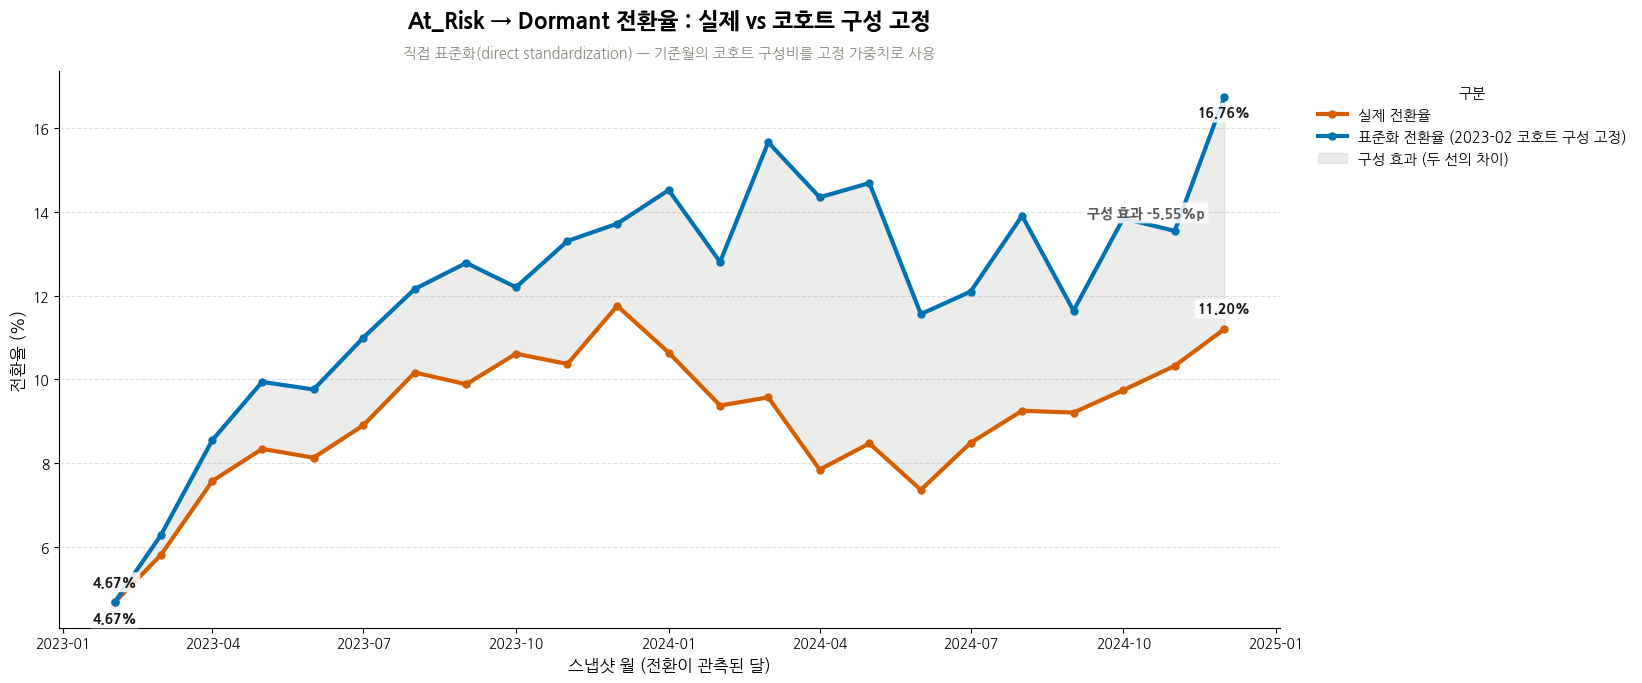

In [ ]:
# =====================================================================================
# [차트] 직접 표준화 — 구성 효과와 행동 효과의 분해
#
# 기준월의 코호트 구성비 w를 고정한 채 각 시점의 코호트별 전환율을 가중평균하면,
# "고객 구성이 변하지 않았다면 전환율은 얼마였을까"를 얻는다(표준화 전환율).
#   실제 전환율 - 표준화 전환율 = 구성 효과
#   표준화 전환율의 변화       = 행동 효과
# 인구통계학의 연령표준화와 동일한 기법이다.
# =====================================================================================
piv_rate = coh.pivot(index="month_cur", columns="signup_cohort", values="rate").sort_index()
piv_n    = coh.pivot(index="month_cur", columns="signup_cohort", values="n").sort_index().fillna(0)

base_month = piv_rate.index[0]
w_base = piv_n.loc[base_month]
w_base = w_base[w_base > 0]
w_base = w_base / w_base.sum()
cols = list(w_base.index)

# 각 월마다, 기준월 가중치를 '그 달에 존재하는 코호트'에 대해 재정규화
R = piv_rate[cols]
W = pd.DataFrame(np.tile(w_base.values, (len(R), 1)), index=R.index, columns=cols)
W = W.where(R.notna())
W = W.div(W.sum(axis=1), axis=0)

std_rate    = (R * W).sum(axis=1)                                    # 구성 고정
actual_rate = coh.groupby("month_cur").apply(lambda g: g["k"].sum() / g["n"].sum() * 100)
actual_rate = actual_rate.reindex(std_rate.index)

_L_ACT = "실제 전환율"
_L_STD = f"표준화 전환율 ({base_month:%Y-%m} 코호트 구성 고정)"
_L_GAP = "구성 효과 (두 선의 차이)"

fig, ax = plt.subplots(figsize=fig_size(7))
ax.fill_between(std_rate.index, std_rate.values, actual_rate.values,
                color=INK_MUTED, alpha=0.16, label=_L_GAP, zorder=2)
ax.plot(actual_rate.index, actual_rate.values, marker="o", markersize=5, linewidth=3.0,
        color=CAT_PALETTE[3], label=_L_ACT, zorder=5)
ax.plot(std_rate.index, std_rate.values, marker="o", markersize=5, linewidth=3.0,
        color=CAT_PALETTE[0], label=_L_STD, zorder=5)

for series, dy in [(actual_rate, 12), (std_rate, -14)]:
    for m in [series.index[0], series.index[-1]]:
        ax.annotate(f"{series[m]:.2f}%", xy=(m, series[m]), xytext=(0, dy),
                    textcoords="offset points", ha="center", fontsize=FS_LABEL + 1,
                    fontweight="bold", color=ink(True), bbox=LABEL_BBOX, zorder=10)

_m1 = std_rate.index[-1]
_gap = actual_rate[_m1] - std_rate[_m1]
ax.annotate(f"구성 효과 {_gap:+.2f}%p", xy=(_m1, (actual_rate[_m1] + std_rate[_m1]) / 2),
            xytext=(-14, 0), textcoords="offset points", ha="right", va="center",
            fontsize=FS_LABEL + 1, fontweight="bold", color=ink(False),
            bbox=LABEL_BBOX, zorder=10)

finalize(ax, f"{FROM_SEG} → {TO_SEG} 전환율 : 실제 vs 코호트 구성 고정",
         "스냅샷 월 (전환이 관측된 달)", "전환율 (%)",
         subtitle="직접 표준화(direct standardization) — 기준월의 코호트 구성비를 고정 가중치로 사용",
         legend_title="구분", legend_order=[_L_ACT, _L_STD, _L_GAP], unit_fmt="{:,.0f}")
plt.show()


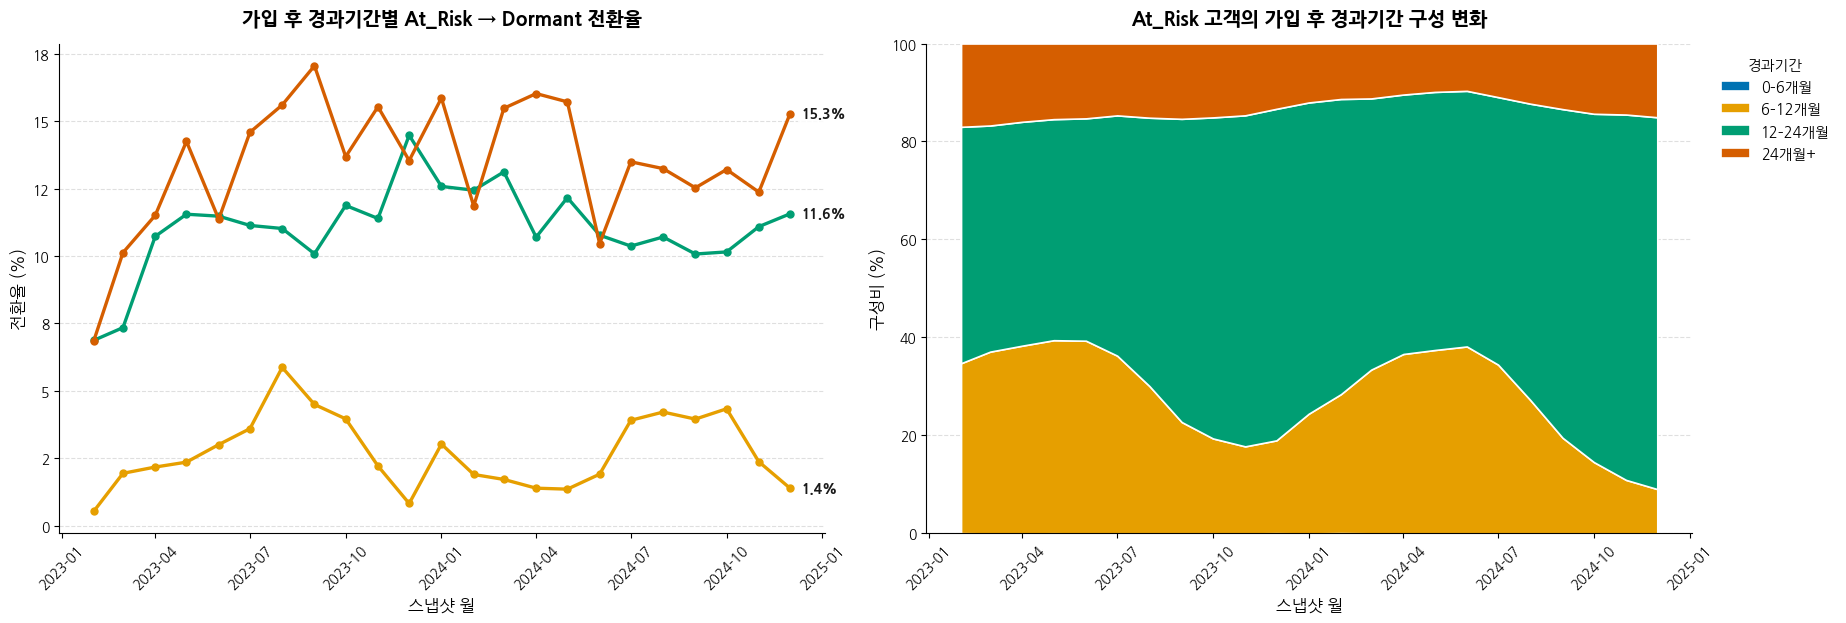

In [ ]:
# =====================================================================================
# [차트] 가입 후 경과기간(tenure) 통제  [A11]
#
# At_Risk 판정은 recency에 좌우되고, recency는 가입 후 경과기간과 강하게 얽혀 있다.
# tenure 구간을 고정한 뒤에도 전환율이 오르는지 확인하면 코호트 통제와 상호 검증이 된다.
# =====================================================================================

TENURE_BINS   = [-1, 180, 365, 730, 10**9]
TENURE_LABELS = ["0–6개월", "6–12개월", "12–24개월", "24개월+"]

sub["tenure_band"] = pd.cut(sub["tenure_prev"], bins=TENURE_BINS, labels=TENURE_LABELS)

ten = (sub.groupby(["month_cur", "tenure_band"], as_index=False, observed=True)
          .agg(n=("user_id", "size"), k=("is_to", "sum")))
ten["rate"] = ten["k"] / ten["n"] * 100
ten_plot = ten[ten["n"] >= MIN_N]

fig, axes = plt.subplots(1, 2, figsize=fig_size(6.4, plot_w=FIG_W_2PANE, legends=1))

ax = axes[0]
for i, b in enumerate(TENURE_LABELS):
    g = ten_plot[ten_plot["tenure_band"] == b].sort_values("month_cur")
    if g.empty:
        continue
    col = CAT_PALETTE[i % len(CAT_PALETTE)]
    ax.plot(g["month_cur"], g["rate"], marker="o", markersize=5, linewidth=2.4,
            color=col, label=b, zorder=5)
    last = g.iloc[-1]
    ax.annotate(f"{last['rate']:.1f}%", xy=(last["month_cur"], last["rate"]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=FS_LABEL + 1,
                fontweight="bold", color=ink(True), bbox=LABEL_BBOX, zorder=10)
finalize(ax, "가입 후 경과기간별 At_Risk → Dormant 전환율", "스냅샷 월", "전환율 (%)",
         panel=True, legend=False, unit_fmt="{:,.0f}", xtick_rotation=45, layout=False)

ax = axes[1]
_mix = (ten.pivot(index="month_cur", columns="tenure_band", values="n")
           .reindex(columns=TENURE_LABELS).fillna(0))
_mixp = _mix.div(_mix.sum(axis=1), axis=0) * 100
ax.stackplot(_mixp.index, *[_mixp[b].values for b in TENURE_LABELS], labels=TENURE_LABELS,
             colors=[CAT_PALETTE[i % len(CAT_PALETTE)] for i in range(len(TENURE_LABELS))],
             edgecolor="white", linewidth=1.2)
ax.set_ylim(0, 100)
finalize(ax, "At_Risk 고객의 가입 후 경과기간 구성 변화", "스냅샷 월", "구성비 (%)",
         panel=True, legend_title="경과기간", legend_order=list(TENURE_LABELS),
         xtick_rotation=45)
plt.show()


In [ ]:
# =====================================================================================
# [신규 · 단독 차트] 가입 후 경과기간(tenure)별 At_Risk → Dormant 전환율  — 노션 2-3절
# =====================================================================================
# [신설 이유]
#   이 차트는 지금까지 '구성 변화' 차트와 2패널로만 존재해, 노션에 단독으로 싣거나
#   본문 바로 아래에 배치할 수 없었음. 본문이 "12~24개월 +4.69%p, 24개월+ +8.42%p"를
#   서술하는 자리에 필요한 것은 왼쪽 패널 하나뿐이므로 단독 차트로 분리함.
#   (2패널 버전은 위 셀에 그대로 두어, 구성 변화와 함께 봐야 할 때 사용)
#
# [코호트 차트와 동일하게 시작점 라벨 추가]
#   본문이 시작→종료로 변화를 서술하므로 두 값이 모두 차트에 있어야 함.
#
# [해석 포인트 — 왜 이 차트가 필요한가]
#   At_Risk 판정은 recency 에 좌우되고 recency 는 가입 후 경과기간과 얽혀 있음.
#   "오래된 고객이 많아져서 전환율이 오른 것"이라면 tenure 를 고정했을 때 상승이
#   사라져야 함. 사라지지 않으면 같은 tenure 의 고객이 2024년에 더 많이 이탈한 것.
# =====================================================================================
fig, ax = plt.subplots(figsize=fig_size(7))

_rows_t = []
for i, b in enumerate(TENURE_LABELS):
    g = ten_plot[ten_plot["tenure_band"] == b].sort_values("month_cur")
    if g.empty:
        continue
    col = CAT_PALETTE[i % len(CAT_PALETTE)]
    ax.plot(g["month_cur"], g["rate"], marker="o", markersize=5, linewidth=2.4,
            color=col, label=b, zorder=5)

    first, last = g.iloc[0], g.iloc[-1]
    ax.annotate(f"{first['rate']:.1f}%", xy=(first["month_cur"], first["rate"]),
                xytext=(-9, 0), textcoords="offset points", ha="right", va="center",
                fontsize=FS_LABEL + 1, color=ink(False), bbox=LABEL_BBOX, zorder=10)
    ax.annotate(f"{last['rate']:.1f}%", xy=(last["month_cur"], last["rate"]),
                xytext=(9, 0), textcoords="offset points", ha="left", va="center",
                fontsize=FS_LABEL + 1, fontweight="bold", color=ink(True),
                bbox=LABEL_BBOX, zorder=10)
    _rows_t.append({"경과기간": b,
                    "시작": f"{first['month_cur']:%Y-%m}", "시작(%)": round(first["rate"], 2),
                    "시작 모수(명)": int(first["n"]),
                    "종료": f"{last['month_cur']:%Y-%m}", "종료(%)": round(last["rate"], 2),
                    "종료 모수(명)": int(last["n"]),
                    "변화(%p)": round(last["rate"] - first["rate"], 2)})

# 분모 미달로 차트에서 빠진 구간을 명시(무엇이 왜 없는지를 독자가 알 수 있게)
_dropped = [b for b in TENURE_LABELS if ten_plot[ten_plot["tenure_band"] == b].empty]
_note = f"  ·  {', '.join(_dropped)} 구간은 분모 {MIN_N}명 미만이라 제외" if _dropped else ""

ax.margins(x=0.07)
finalize(ax, f"가입 후 경과기간별 {FROM_SEG} → {TO_SEG} 전환율",
         "스냅샷 월 (전환이 관측된 달)", "전환율 (%)",
         subtitle="왼쪽 라벨 = 시작값, 오른쪽 라벨 = 종료값" + _note,
         legend_title="경과기간", legend_order=list(TENURE_LABELS), unit_fmt="{:,.0f}")
plt.show()

print("=== 경과기간 고정 시 전환율 변화 (차트 라벨과 동일한 값) ===")
display(pd.DataFrame(_rows_t))
if _dropped:
    print(f"※ 제외 구간: {', '.join(_dropped)} — At_Risk 판정에 최소 181일의 미구매 기간이 "
          f"필요하므로 가입 직후 구간은 모수가 구조적으로 작음")


### 3.6. Others → At_Risk 전이율
: 붕괴가 상위에서 시작되는지 확인

각 세그먼트 s에 대해:

$\text{TransitionRate}_{s \rightarrow At\_Risk, t} = \frac{\#(s_t \cap At\_Risk_{t+1})}{\#(s_t)}$
- 분모: t월 기준 세그먼트 s 고객 수
- 분자: 그중 다음 달 At_Risk로 전이된 고객 수

→ “s 세그먼트의 붕괴율”

In [456]:
segments = snapshots_df["segment"].unique()
dest_segment = "At_Risk"

transition_lst = []
for seg in segments:
    transition = get_transition_rate(snapshots_df, seg, dest_segment)
    transition_lst.append(transition)

at_risk_transition_df = pd.concat(transition_lst, ignore_index=True)

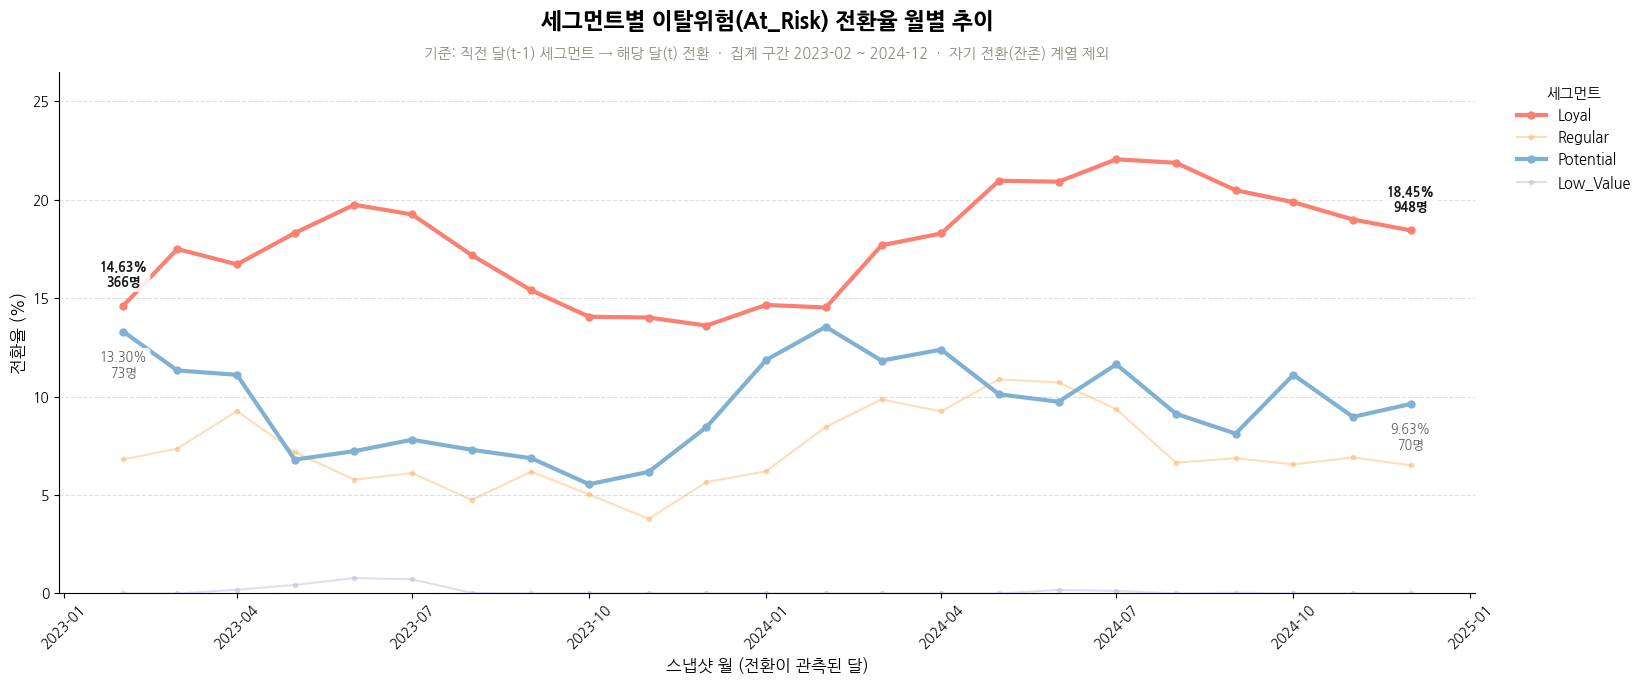

In [ ]:
# =====================================================================================
# [차트] 세그먼트별 이탈위험(At_Risk) 전환율 월별 추이
# =====================================================================================

plot_transition_themed(at_risk_transition_df, "At_Risk",
                       main_segs=["Loyal", "Potential"], label_below=("Potential",),
                       title="세그먼트별 이탈위험(At_Risk) 전환율 월별 추이")


# 4. 핵심 매출 고객의 휴면 경로 추적

Loyal 유입 경로와 2024년 매출 비중을 확인한 뒤, VIP→Loyal 진입 고객의 이후 경로를 추적합니다.

### 4.1. Others → Loyal 전환율

In [459]:
# 1. 타겟 세그먼트 설정
segments = snapshots_df["segment"].unique()
dest_segment = "Loyal"

# 2. 모든 세그먼트 -> Loyal 전이율 계산
transition_lst = []
for seg in segments:
    # 자기 자신(Loyal -> Loyal 잔존)은 타 세그먼트로부터의 '유입'이 아니므로 제외
    if seg == dest_segment:
        continue
    transition = get_transition_rate(snapshots_df, seg, dest_segment)
    transition_lst.append(transition)

loyal_transition_df = pd.concat(transition_lst, ignore_index=True)

In [461]:
loyal_avg = loyal_transition_df.copy()
loyal_avg["year"] = pd.to_datetime(loyal_avg["snapshot_month"]).dt.year

loyal_yearly_avg = (
    loyal_avg
    .groupby(["year", "from_segment"])["transition_rate"]
    .mean()
    .reset_index()
    .rename(columns={"transition_rate": "avg_transition_rate"})
    .pivot(index="from_segment", columns="year", values="avg_transition_rate")
    .round(2)
)

loyal_yearly_avg.columns = [f"{col}년 평균 전환율(%)" for col in loyal_yearly_avg.columns]
loyal_yearly_avg = loyal_yearly_avg.sort_values(loyal_yearly_avg.columns[-1], ascending=False)
loyal_yearly_avg

,2023년 평균 전환율(%),2024년 평균 전환율(%)
from_segment,,
Regular,27.21,23.93
VIP,16.18,17.57
Potential,9.96,8.90
Low_Value,4.89,4.23
At_Risk,0.16,0.15
Dormant,0.09,0.06


### 4.2. 핵심 매출 고객의 집중 분석 근거 (노션 M03·M04)

**배치:** 노션 2-3 휴면 전환율 해석 → M03 분석 범위 → C01 매출 비중 → M04 R12M → 직접 표준화.

- 각 월말 세그먼트에 같은 달 매출을 귀속한 뒤 2024년 매출을 합산합니다.
- 주문·상품 원자료와 월말 스냅샷을 사용합니다.
- 기존 A9·A12와 동일하게 주문 상태 Completed·Processing, 상품 상태 Purchased·Shipped·Packing을 사용합니다.

C01 검증 완료: {'year': 2024, 'orders': 113756, 'matched_orders': 113756, 'months': 12, 'total_revenue_krw': 17088828730.0, 'vip_loyal_share_pct': 79.81149027526125}


  segment  revenue_krw  share_pct
      VIP 9959877610.0  58.282974
    Loyal 3678971270.0  21.528516
  At_Risk          0.0   0.000000
  Regular 1023378030.0   5.988579
Potential  780457310.0   4.567061
Low_Value 1646144510.0   9.632869
  Dormant          0.0   0.000000

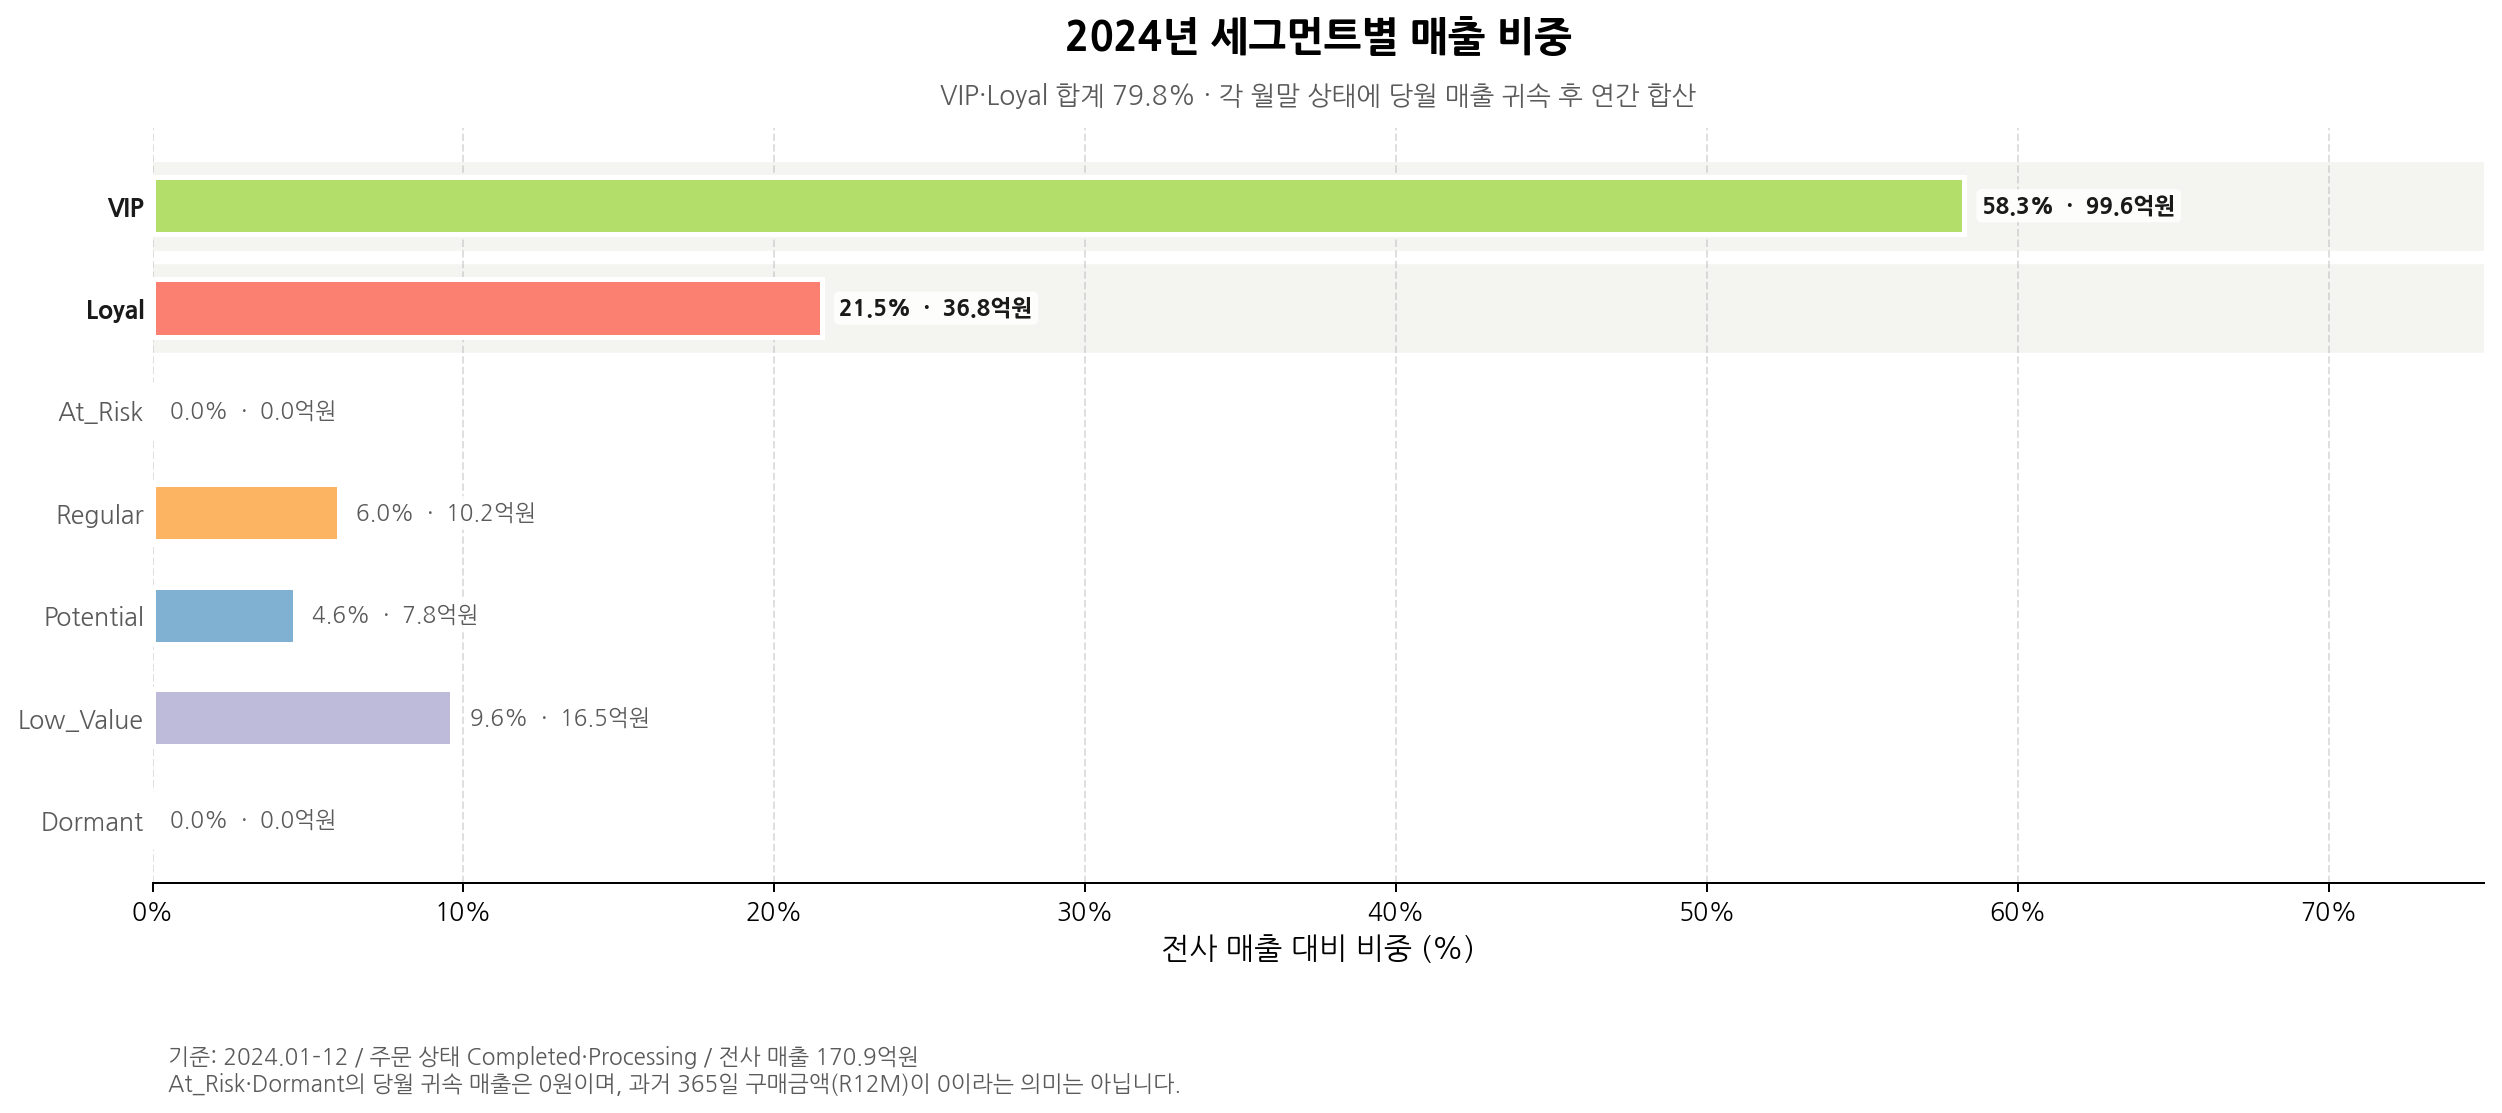

In [ ]:
# [C01 · M03/M04] 핵심 매출 고객의 집중 분석 근거 — 노션 2-3
# Layer 3: VIP·Loyal을 강조하되 모든 세그먼트를 고정 순서로 표시한다.
# 공통 테마의 색상·폰트·가로 막대 규칙을 사용한다. 보조 막대도 alpha=1.
# 선행 실행: 라이브러리, CHART THEME v2, orders_enriched 및 snapshots_df 준비.

def build_c01_revenue_share(snapshots, orders, year=2024):
    """당월 주문 매출을 같은 월말 상태에 귀속. R12M 합산이 아니다."""
    month_list = [f"{year}-{m:02d}" for m in range(1, 13)]
    snap = snapshots[["snapshot_month", "user_id", "segment"]].copy()
    snap["snapshot_month"] = snap["snapshot_month"].astype(str)
    snap = snap[snap["snapshot_month"].isin(month_list)]
    assert set(snap["snapshot_month"]) == set(month_list), "12개월 스냅샷이 필요합니다."
    assert not snap.duplicated(["snapshot_month", "user_id"]).any(), "스냅샷 키 중복"
    assert snap["segment"].notna().all(), "누락된 세그먼트"
    assert set(snap["segment"]).issubset(SEGMENT_ORDER), "미등록 세그먼트"
    order = orders.copy()
    order["created_at"] = pd.to_datetime(order["created_at"], errors="raise")
    order = order[order["status"].isin({"Completed", "Processing"}) &
                  order["created_at"].ge(f"{year}-01-01") &
                  order["created_at"].lt(f"{year+1}-01-01")].copy()
    assert not order["id"].duplicated().any(), "주문 중복"
    assert order[["user_id", "order_amount"]].notna().all().all(), "주문값 누락"
    assert np.isfinite(order["order_amount"]).all() and order["order_amount"].ge(0).all()
    order["snapshot_month"] = order["created_at"].dt.to_period("M").astype(str)
    joined = order.merge(snap, on=["snapshot_month", "user_id"], how="left",
                         validate="many_to_one", indicator=True)
    assert joined["_merge"].eq("both").all(), "월말 세그먼트 미매칭 주문"
    result = joined.groupby("segment")["order_amount"].sum().reindex(SEGMENT_ORDER, fill_value=0)
    result = result.rename("revenue_krw").rename_axis("segment").reset_index()
    total = order["order_amount"].sum()
    assert total > 0 and np.isclose(result["revenue_krw"].sum(), total, rtol=1e-12)
    result["share_pct"] = result["revenue_krw"] / total * 100
    assert np.isclose(result["share_pct"].sum(), 100)
    # 당월 구매자는 당월 말 At_Risk/Dormant 정의를 만족하지 않아야 한다.
    assert result.loc[result["segment"].isin(["At_Risk", "Dormant"]), "revenue_krw"].eq(0).all()
    audit = {"year": year, "orders": len(order), "matched_orders": len(joined),
             "months": len(month_list), "total_revenue_krw": float(total),
             "vip_loyal_share_pct": float(result.loc[result.segment.isin(["VIP", "Loyal"]), "share_pct"].sum())}
    return result, audit

c01_table, c01_audit = build_c01_revenue_share(snapshots_df, orders_enriched)
C01_UNIT_DIV, C01_UNIT_SUFFIX, C01_UNIT_FMT = 1e8, "억원", "{:,.1f}"
c01_primary = {"VIP", "Loyal"}
fig_c01, ax_c01 = plt.subplots(figsize=fig_size(6.4, legends=0))
for i, row in enumerate(c01_table.itertuples(index=False)):
    primary = row.segment in c01_primary
    if primary:
        ax_c01.axhspan(i-.42, i+.42, color="#F4F4F1", zorder=0)
    ax_c01.barh(i, row.share_pct, height=.56, color=PALETTE_SEG[row.segment],
                **bar_style(is_primary=True))
    label = f"{row.share_pct:.1f}%  ·  {C01_UNIT_FMT.format(row.revenue_krw/C01_UNIT_DIV)}{C01_UNIT_SUFFIX}"
    ax_c01.annotate(label, (row.share_pct, i), xytext=(7, 0), textcoords="offset points",
                    ha="left", va="center", fontsize=FS_LABEL, color=ink(primary),
                    fontweight="bold" if primary else "normal", bbox=LABEL_BBOX)
ax_c01.set_yticks(range(len(c01_table)), c01_table.segment)
ax_c01.invert_yaxis()
ax_c01.set_xlim(0, 75)
ax_c01.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
ax_c01.tick_params(axis="y", length=0)
for label in ax_c01.get_yticklabels():
    primary = label.get_text() in c01_primary
    label.set_fontweight("bold" if primary else "normal")
    label.set_color(ink(primary))
finalize(ax_c01, "2024년 세그먼트별 매출 비중", "전사 매출 대비 비중 (%)", None,
         subtitle=f"VIP·Loyal 합계 {c01_audit['vip_loyal_share_pct']:.1f}% · 각 월말 상태에 당월 매출 귀속 후 연간 합산",
         legend=False, grid_axis="x", layout=False)
# 부제는 파스텔 계열색이 아닌 공통 보조 잉크색으로 읽기 쉽게 표시한다.
ax_c01.texts[-1].set_color(INK_SECONDARY)
fig_c01.text(.07, .04,
             "기준: 2024.01–12 / 주문 상태 Completed·Processing / 전사 매출 "
             + C01_UNIT_FMT.format(c01_audit['total_revenue_krw']/C01_UNIT_DIV) + C01_UNIT_SUFFIX
             + "\nAt_Risk·Dormant의 당월 귀속 매출은 0원이며, 과거 365일 구매금액(R12M)이 0이라는 의미는 아닙니다.",
             fontsize=FS_LABEL, color=INK_SECONDARY, va="bottom")
fig_c01.tight_layout(rect=(0, .13, 1, 1))
c01_output_dir = Path(globals().get("C01_OUTPUT_DIR", "../outputs"))
c01_output_dir.mkdir(parents=True, exist_ok=True)
fig_c01.savefig(c01_output_dir / "c01_2024_segment_revenue_share.png", dpi=180, bbox_inches="tight", facecolor="white")
c01_table.to_csv(c01_output_dir / "c01_2024_segment_revenue_share.csv", index=False)
print(f"C01 검증 완료: {c01_audit}")
display(c01_table)
plt.show()


### 4.3. VIP→Loyal 진입 후 7개월 최초 도달 경로 (2026-10-02 재집계)

- 진입 다음 달부터 7개월 동안 VIP와 At_Risk 중 먼저 관찰된 상태로 분류합니다.(둘 다 미도달한 고객도 분모에 포함합니다.)
- 동일 고객의 다른 월 재진입은 재포함하며, 7개월 완전 관측 월만 사용합니다.
- 7개월째 상태 및 기간 내 경험률도 함께 산출하여 차이를 검증합니다.

   entry_month    n  risk_first_n  vip_first_n  neither_n  ever_risk_n  ever_vip_n  both_n  risk_at_month7_n  loyal_all7_n  risk_first_pct  vip_first_pct  neither_pct  ever_risk_pct  ever_vip_pct  risk_at_month7_pct
0   2023-02-01  370           353           17          0          358          17       5               329             0       95.405405       4.594595     0.000000      96.756757      4.594595           88.918919
1   2023-03-01  444           438            6          0          438           6       0               406             0       98.648649       1.351351     0.000000      98.648649      1.351351           91.441441
2   2023-04-01  450           442            8          0          444           8       2               399             0       98.222222       1.777778     0.000000      98.666667      1.777778           88.666667
3   2023-05-01  433           422           11          0          425          11       3               375             0       97.4595

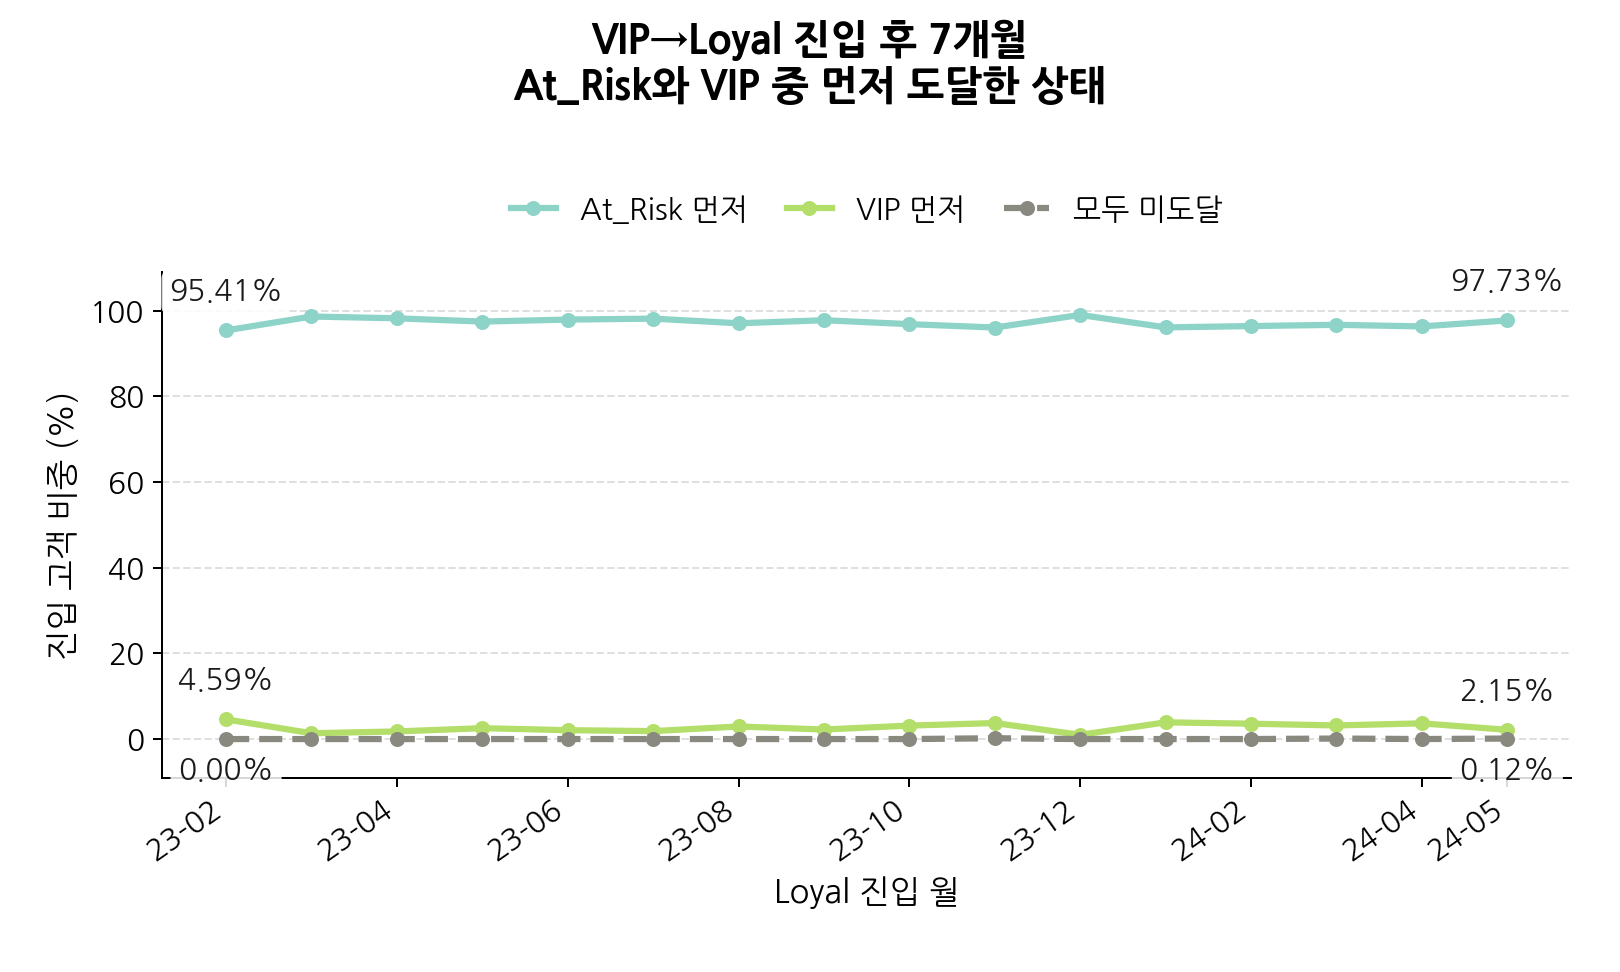

In [1]:
# VIP→Loyal 진입 월별 코호트: 이후 1~7개월의 VIP/At_Risk 최초 도달 비교.
# 같은 고객은 서로 다른 진입월에 재진입하면 해당 월 코호트에 다시 포함한다.
from pathlib import Path
s7=snapshots_df[['user_id','snapshot_month','segment']].copy()
s7['month']=pd.to_datetime(s7.snapshot_month)
assert not s7.duplicated(['user_id','month']).any()
p7=s7[['user_id','month','segment']].copy()
p7['month']+=pd.DateOffset(months=1)
p7=p7.rename(columns={'segment':'previous_segment'})
j7=s7.merge(p7,on=['user_id','month'],validate='one_to_one')
e7=j7[j7.previous_segment.eq('VIP') & j7.segment.eq('Loyal')][['user_id','month']]
rows7=[];diagnostics7=[]
for entry7,g7 in e7.groupby('month'):
    if entry7+pd.DateOffset(months=7)>s7.month.max():continue
    months7=pd.date_range(entry7+pd.DateOffset(months=1),periods=7,freq='MS')
    f7=s7[s7.user_id.isin(g7.user_id)&s7.month.isin(months7)].pivot(index='user_id',columns='month',values='segment').reindex(index=g7.user_id,columns=months7)
    assert f7.shape==(len(g7),7) and f7.notna().all().all()
    v7=f7.to_numpy();risk7=v7=='At_Risk';vip7=v7=='VIP'
    fr7=np.where(risk7.any(axis=1),risk7.argmax(axis=1)+1,99)
    fv7=np.where(vip7.any(axis=1),vip7.argmax(axis=1)+1,99)
    no7=(fr7==99)&(fv7==99)
    row7=dict(entry_month=entry7,n=len(g7),risk_first_n=int((fr7<fv7).sum()),vip_first_n=int((fv7<fr7).sum()),neither_n=int(no7.sum()),ever_risk_n=int(risk7.any(axis=1).sum()),ever_vip_n=int(vip7.any(axis=1).sum()),both_n=int((risk7.any(axis=1)&vip7.any(axis=1)).sum()),risk_at_month7_n=int(risk7[:,-1].sum()),loyal_all7_n=int((v7=='Loyal').all(axis=1).sum()))
    assert row7['risk_first_n']+row7['vip_first_n']+row7['neither_n']==row7['n']
    rows7.append(row7)
    for path7 in v7[no7]:diagnostics7.append({'entry_month':entry7,'path':' → '.join(path7)})
seven_month_summary=pd.DataFrame(rows7)
for col7 in ['risk_first','vip_first','neither','ever_risk','ever_vip','risk_at_month7']:
    seven_month_summary[col7+'_pct']=seven_month_summary[col7+'_n']/seven_month_summary.n*100
assert round(seven_month_summary.iloc[0].risk_first_pct,1)==95.4
assert round(seven_month_summary.iloc[-1].risk_first_pct,1)==97.7
out7=Path(globals().get('SEVEN_MONTH_OUTPUT_DIR','../outputs'));out7.mkdir(exist_ok=True,parents=True)
seven_month_summary.to_csv(out7/'vip_loyal_7m_first_event_audit.csv',index=False)
pd.DataFrame(diagnostics7).to_csv(out7/'vip_loyal_7m_neither_paths.csv',index=False)

# 화면용 프로필: 범례를 상단으로 이동하고 눈금·라벨을 확대한다.
fig7,ax7=plt.subplots(figsize=(SCREEN_FIG_W,5.4))
x7=np.arange(len(seven_month_summary))
for key7,label7,color7,ls7 in [('risk_first','At_Risk 먼저',PALETTE_SEG['At_Risk'],'-'),('vip_first','VIP 먼저',PALETTE_SEG['VIP'],'-'),('neither','모두 미도달',INK_MUTED,'--')]:
    y7=seven_month_summary[key7+'_pct']
    ax7.plot(x7,y7,marker='o',linewidth=2.5,markersize=5,color=color7,linestyle=ls7,label=label7)
    for pos7 in [0,len(x7)-1]:
        dy7=12 if key7!='neither' else -16
        ax7.annotate(f'{y7.iloc[pos7]:.2f}%',(pos7,y7.iloc[pos7]),xytext=(0,dy7),textcoords='offset points',ha='center',fontsize=SCREEN_FS_LABEL,color=INK_PRIMARY,bbox=LABEL_BBOX)
ticks7=list(range(0,len(x7),2))
if ticks7[-1]!=len(x7)-1:ticks7.append(len(x7)-1)
ax7.set_xticks(ticks7);ax7.set_xticklabels([f'{seven_month_summary.entry_month.iloc[i]:%y-%m}' for i in ticks7],rotation=35,ha='right')
ax7.set_ylim(-9,109);ax7.set_yticks([0,20,40,60,80,100])
finalize_screen(ax7,'','Loyal 진입 월','진입 고객 비중 (%)')
fig7.suptitle('VIP→Loyal 진입 후 7개월\nAt_Risk와 VIP 중 먼저 도달한 상태',fontsize=FS_TITLE,fontweight='bold',y=.98)
ax7.legend(loc='lower center',bbox_to_anchor=(.5,1.04),ncol=3,fontsize=SCREEN_FS_LABEL,frameon=False,columnspacing=1.3,handlelength=1.5)
fig7.subplots_adjust(left=.10,right=.97,bottom=.20,top=.72)
fig7.savefig(out7/'vip_loyal_7m_screen.png',dpi=180,facecolor='white')
display(seven_month_summary)
plt.show()


### 4.4. VIP→Loyal 진입 고객의 실제 12개월 경로 (2026-10-02 수정)

- 동일 고객의 월별 상태열에서 연속 잔존만 압축하고 최초 휴면에서 종료합니다.
- 주요 경로 2개·기타 휴면·휴면 미도달을 서로 배타적으로 집계하여 인원과 비중을 비교합니다.
- 경로의 화살표는 다음 상태 변화 순서이며 반드시 인접월이 아닙니다.
- 7개월 내 At_Risk 경험과 7개월째 상태는 같지 않습니다.
- 고객당 관측상 첫 진입 1회, 12개월 완전 관측 5,098명, 추적기간 부족 9,293명 제외.

                                   route     n        pct
0              Loyal → At_Risk → Dormant  2985  58.552373
1  Loyal → At_Risk → Low_Value → Dormant  1984  38.917222
2                      그 밖의 경로로 최초 휴면 도달     6   0.117693
3                          12개월 내 휴면 미도달   123   2.412711

    elapsed_month  ever_at_risk_n  ever_dormant_n  denominator
3               3            4914               0         5098
7               7            5014               0         5098
12             12            5079            4975         5098

    elapsed_month  first_dormant_n  risk_before_first_dormant_n  risk_direct_first_dormant_n  denominator
12             12             4975                         4974                         2988         5098

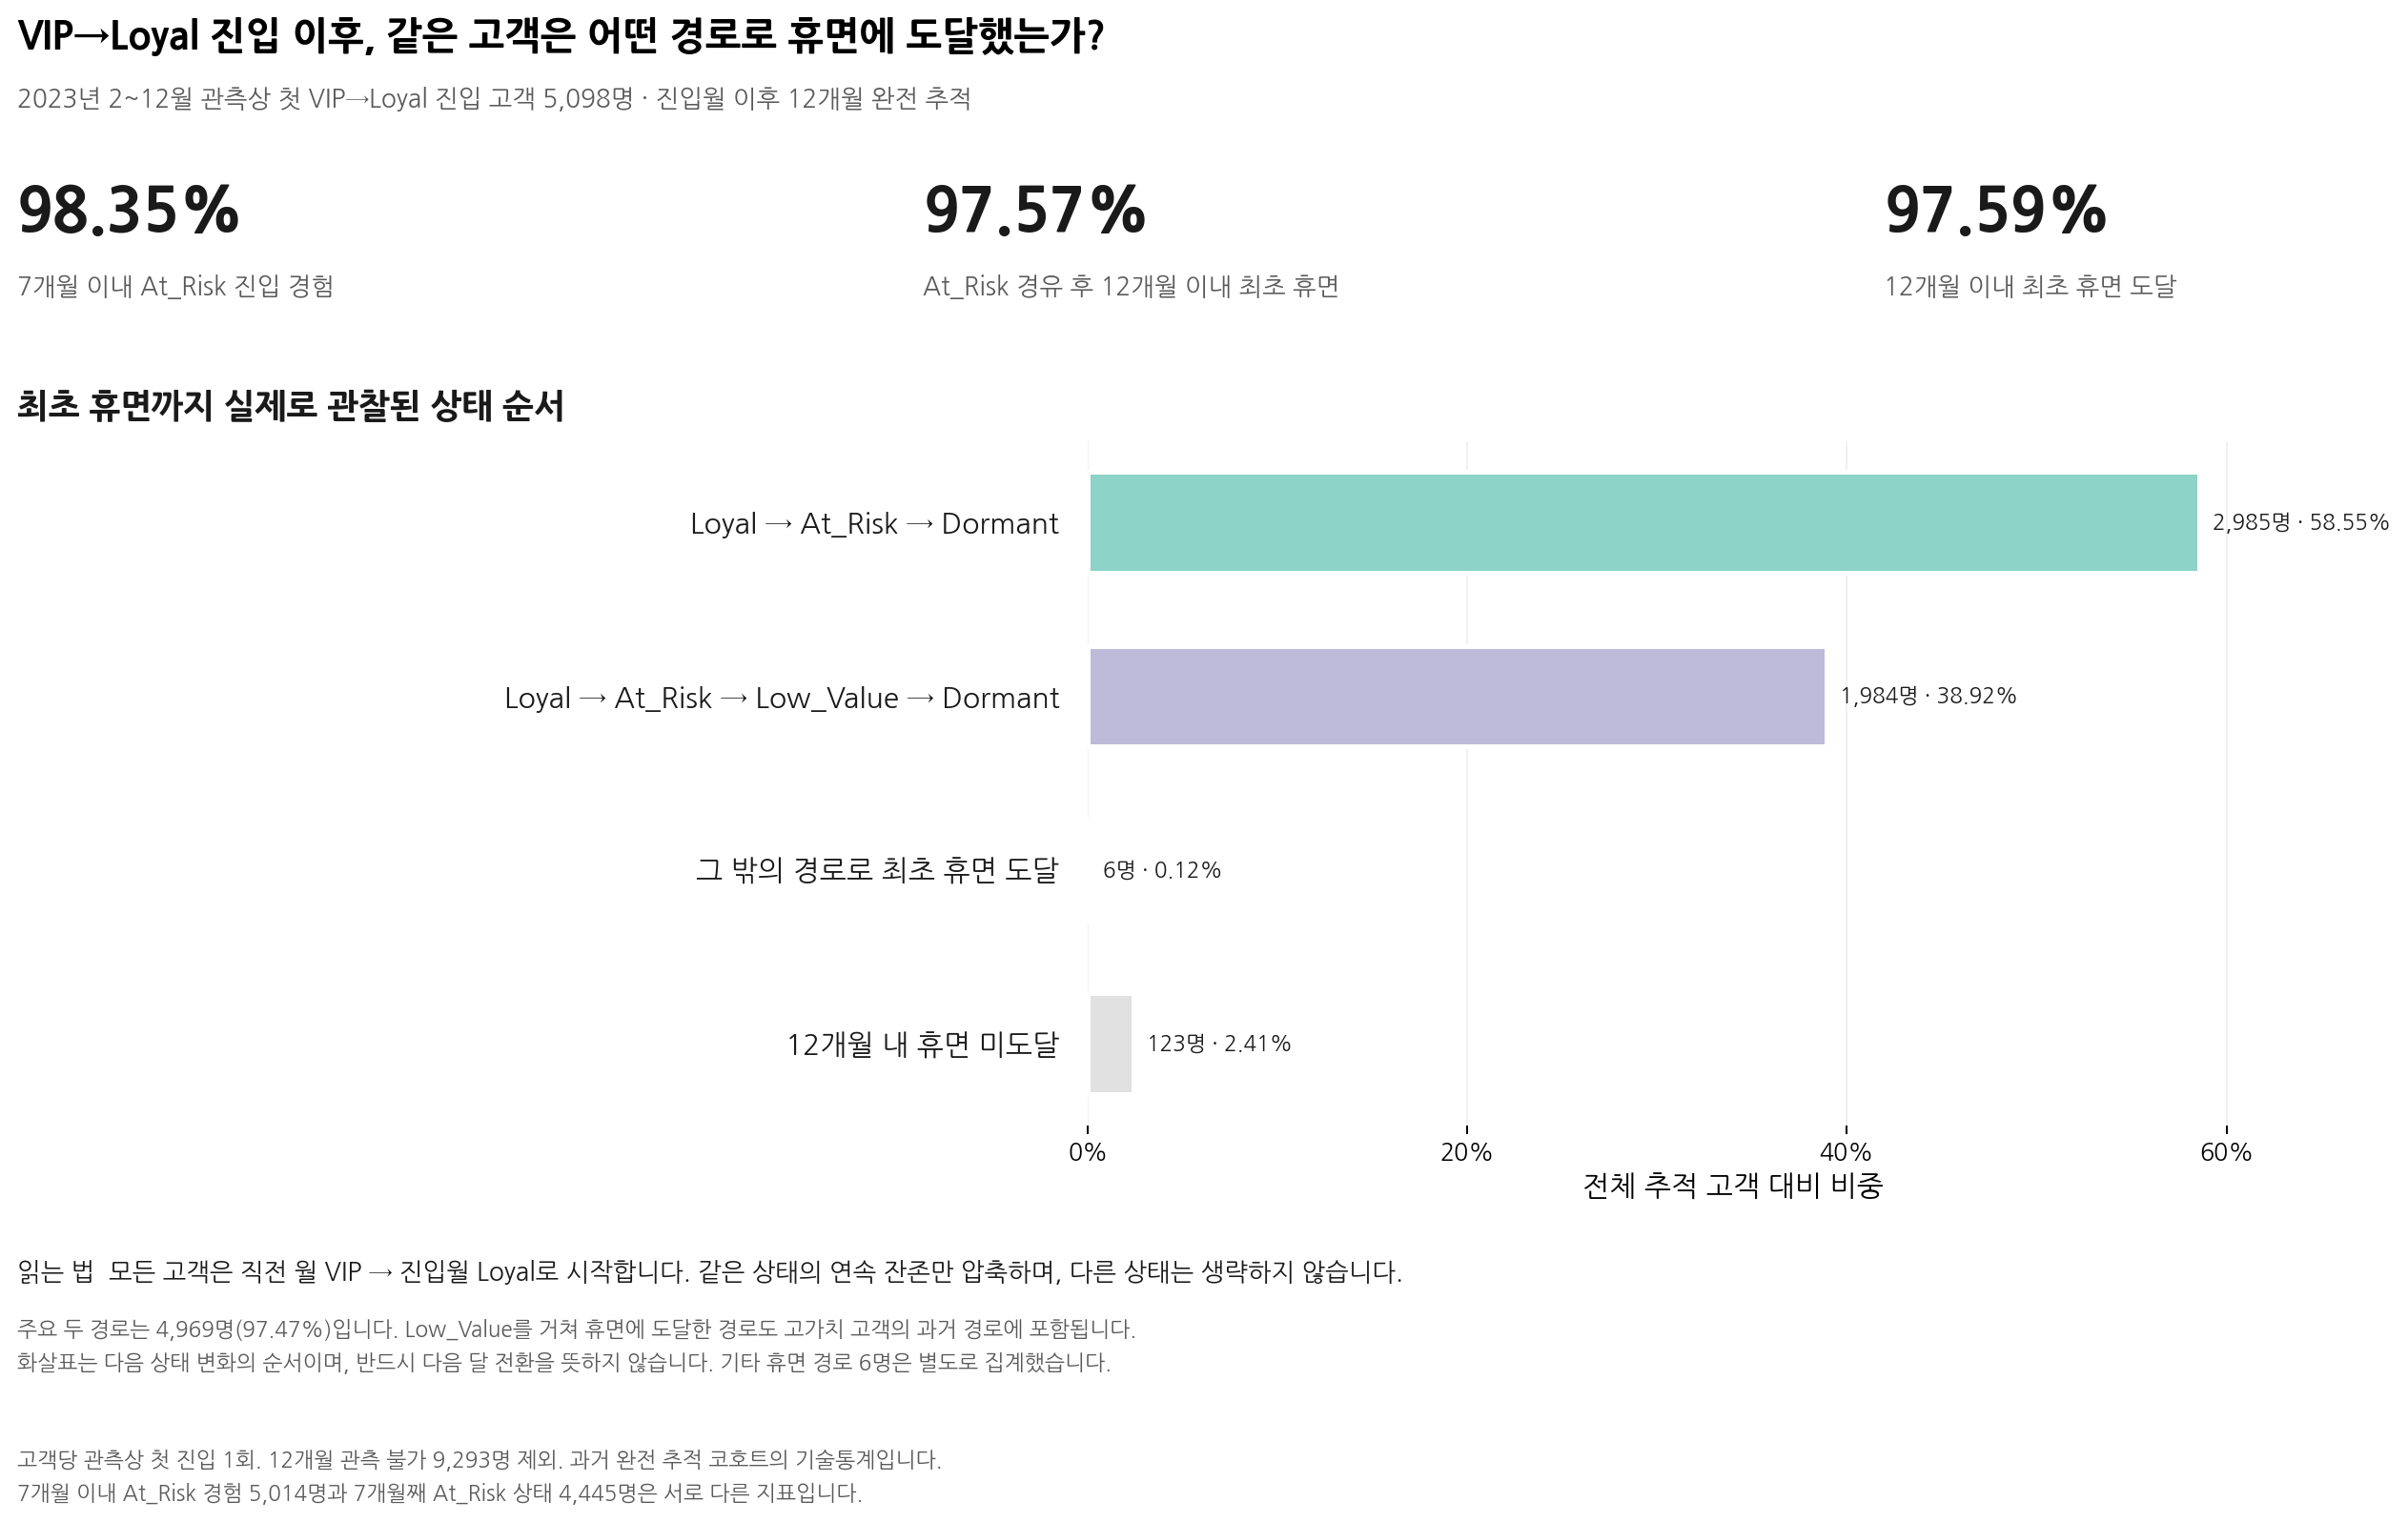

In [ ]:
# [C03] 각 고객의 관측상 첫 VIP→Loyal 진입을 선정하고 12개월 완전 추적.
# 생애 최초 진입으로 해석하지 않는다. 2023-01 이전 전이는 관측되지 않는다.
c03_horizon=12
c03_entries=(c234_pair[c234_pair.from_segment.eq('VIP')&c234_pair.to_segment.eq('Loyal')]
             .sort_values(['to_month','user_id']).drop_duplicates('user_id',keep='first')
             [['user_id','to_month']].rename(columns={'to_month':'entry_month'}))
c03_cutoff=c234_snap.month.max()-pd.DateOffset(months=c03_horizon)
c03_eligible=c03_entries[c03_entries.entry_month.le(c03_cutoff)].copy()
c03_excluded=len(c03_entries)-len(c03_eligible)
assert len(c03_eligible)>0 and not c03_eligible.user_id.duplicated().any()
c03_follow=c234_snap[['user_id','month','segment']].merge(c03_eligible,on='user_id',validate='many_to_one')
c03_follow['elapsed']=(c03_follow.month.dt.year-c03_follow.entry_month.dt.year)*12+c03_follow.month.dt.month-c03_follow.entry_month.dt.month
c03_follow=c03_follow[c03_follow.elapsed.between(0,c03_horizon)]
c03_matrix=c03_follow.pivot(index='user_id',columns='elapsed',values='segment').reindex(columns=range(c03_horizon+1))
assert c03_matrix.shape==(len(c03_eligible),c03_horizon+1) and c03_matrix.notna().all().all()
assert c03_matrix[0].eq('Loyal').all()
c03_n=len(c03_matrix)
c03_states=pd.DataFrame({m:c03_matrix[m].value_counts().reindex(SEGMENT_ORDER,fill_value=0) for m in c03_matrix}).T
c03_states.index.name='elapsed_month'
assert c03_states.sum(axis=1).eq(c03_n).all()
c03_values=c03_matrix.to_numpy()
c03_risk=c03_values=='At_Risk';c03_dorm=c03_values=='Dormant'
c03_ever_dorm=np.maximum.accumulate(c03_dorm,axis=1)
c03_risk_before=np.concatenate([np.zeros((c03_n,1),dtype=bool),np.maximum.accumulate(c03_risk,axis=1)[:,:-1]],axis=1)

# '최초' 휴면에 도달하기 전에 At_Risk를 거친 고객만 집계한다.
c03_prior_dorm=np.concatenate([np.zeros((c03_n,1),dtype=bool),c03_ever_dorm[:,:-1]],axis=1)
c03_first_dorm=c03_dorm & ~c03_prior_dorm
c03_ordered=np.maximum.accumulate(c03_first_dorm & c03_risk_before,axis=1)
c03_prev_risk=np.concatenate([np.zeros((c03_n,1),dtype=bool),c03_risk[:,:-1]],axis=1)
c03_direct=np.maximum.accumulate(c03_first_dorm & c03_prev_risk,axis=1)
c03_cumulative=pd.DataFrame({'elapsed_month':range(c03_horizon+1),
    'first_dormant_n':c03_ever_dorm.sum(axis=0),'risk_before_first_dormant_n':c03_ordered.sum(axis=0),
    'risk_direct_first_dormant_n':c03_direct.sum(axis=0)})
c03_cumulative['denominator']=c03_n
assert c03_cumulative.first_dormant_n.is_monotonic_increasing
assert c03_cumulative.risk_before_first_dormant_n.le(c03_cumulative.first_dormant_n).all()
assert c03_cumulative.risk_direct_first_dormant_n.le(c03_cumulative.risk_before_first_dormant_n).all()
c03_cohort=c03_eligible.groupby('entry_month').size().rename('eligible_n').reset_index()
c03_allcohort=c03_entries.groupby('entry_month').size().rename('first_observed_entries').reset_index()
c03_allcohort['complete_12m']=c03_allcohort.entry_month.le(c03_cutoff)
c03_allcohort.to_csv(c234_out/'c03_cohort_eligibility.csv',index=False)
c03_states.to_csv(c234_out/'c03_followup_states.csv')
c03_cumulative.to_csv(c234_out/'c03_first_dormant_cumulative.csv',index=False)

# 실제 월별 상태열에서 연속 잔존만 압축하고 최초 휴면에서 종료한다.
c03_paths=[]
for row in c03_values:
    path=[]
    for state in row:
        if not path or path[-1]!=state:path.append(state)
        if state=='Dormant':break
    c03_paths.append(tuple(path))
c03_counts=Counter(c03_paths)
c03_routes=pd.DataFrame([
    {'route':'Loyal → At_Risk → Dormant','n':c03_counts[('Loyal','At_Risk','Dormant')]},
    {'route':'Loyal → At_Risk → Low_Value → Dormant','n':c03_counts[('Loyal','At_Risk','Low_Value','Dormant')]},
    {'route':'그 밖의 경로로 최초 휴면 도달','n':int(c03_ever_dorm[:,-1].sum())-c03_counts[('Loyal','At_Risk','Dormant')]-c03_counts[('Loyal','At_Risk','Low_Value','Dormant')]},
    {'route':'12개월 내 휴면 미도달','n':int((~c03_ever_dorm[:,-1]).sum())}])
c03_routes['pct']=c03_routes.n/c03_n*100
assert c03_routes.n.sum()==c03_n
c03_routes.to_csv(c234_out/'c03_exact_paths.csv',index=False)
c03_first_risk=np.maximum.accumulate(c03_risk,axis=1).sum(axis=0)
c03_timing=pd.DataFrame({'elapsed_month':range(13),'ever_at_risk_n':c03_first_risk,'ever_dormant_n':c03_ever_dorm.sum(axis=0),'denominator':c03_n})
c03_timing.to_csv(c234_out/'c03_first_entry_timing.csv',index=False)
fig_c03=plt.figure(figsize=(16,9.5))
fig_c03.suptitle('VIP→Loyal 진입 이후, 같은 고객은 어떤 경로로 휴면에 도달했는가?',x=.04,ha='left',fontsize=FS_TITLE,fontweight='bold',y=.98)
fig_c03.text(.04,.925,f'2023년 2~12월 관측상 첫 VIP→Loyal 진입 고객 {c03_n:,}명 · 진입월 이후 12개월 완전 추적',fontsize=FS_SUB,color=INK_SECONDARY)
for x,value,label in [( .04,f'{c03_first_risk[7]/c03_n*100:.2f}%','7개월 이내 At_Risk 진입 경험'),(.37,f'{c03_ordered[:,-1].sum()/c03_n*100:.2f}%','At_Risk 경유 후 12개월 이내 최초 휴면'),(.72,f'{c03_ever_dorm[:,-1].sum()/c03_n*100:.2f}%','12개월 이내 최초 휴면 도달')]:
    fig_c03.text(x,.85,value,fontsize=25,fontweight='bold',color=INK_PRIMARY)
    fig_c03.text(x,.81,label,fontsize=FS_SUB,color=INK_SECONDARY)
ax=fig_c03.add_axes([.43,.30,.47,.42])
colors=[PALETTE_SEG['At_Risk'],PALETTE_SEG['Low_Value'],'#bcbcbc','#e1e1e1']
ax.barh(range(4),c03_routes.pct,color=colors,height=.58,edgecolor='white',linewidth=2)
ax.set_yticks(range(4));ax.set_yticklabels(c03_routes.route,fontsize=FS_AXIS,color=INK_PRIMARY)
ax.invert_yaxis();ax.set_xlim(0,68);ax.set_xticks([0,20,40,60]);ax.set_xticklabels(['0%','20%','40%','60%']);ax.set_xlabel('전체 추적 고객 대비 비중',fontsize=FS_AXIS)
ax.set_axisbelow(True);ax.grid(axis='x',alpha=.18);ax.tick_params(axis='y',length=0,pad=12)
for spine in ax.spines.values():spine.set_visible(False)
for i,r in c03_routes.iterrows():ax.text(r.pct+.7,i,f'{r.n:,}명 · {r.pct:.2f}%',va='center',fontsize=FS_LABEL,color=INK_PRIMARY)
fig_c03.text(.04,.735,'최초 휴면까지 실제로 관찰된 상태 순서',fontsize=FS_PANEL,fontweight='bold',color=INK_PRIMARY)
fig_c03.text(.04,.205,'읽는 법  모든 고객은 직전 월 VIP → 진입월 Loyal로 시작합니다. 같은 상태의 연속 잔존만 압축하며, 다른 상태는 생략하지 않습니다.',fontsize=FS_SUB,color=INK_PRIMARY)
fig_c03.text(.04,.15,'주요 두 경로는 4,969명(97.47%)입니다. Low_Value를 거쳐 휴면에 도달한 경로도 고가치 고객의 과거 경로에 포함됩니다.\n'
    '화살표는 다음 상태 변화의 순서이며, 반드시 다음 달 전환을 뜻하지 않습니다. 기타 휴면 경로 6명은 별도로 집계했습니다.',fontsize=FS_LABEL,color=INK_SECONDARY,linespacing=1.7)
fig_c03.text(.04,.07,f'고객당 관측상 첫 진입 1회. 12개월 관측 불가 {c03_excluded:,}명 제외. 과거 완전 추적 코호트의 기술통계입니다.\n'
    f'7개월 이내 At_Risk 경험 {c03_first_risk[7]:,}명과 7개월째 At_Risk 상태 {c03_states.loc[7,"At_Risk"]:,}명은 서로 다른 지표입니다.',fontsize=FS_LABEL,color=INK_SECONDARY,linespacing=1.7)
fig_c03.savefig(c234_out/'c03_vip_loyal_12m_followup.png',dpi=180,bbox_inches='tight',facecolor='white')
display(c03_routes);display(c03_timing.loc[[3,7,12]]);display(c03_cumulative.tail(1))
plt.show()


### 4.5. At_Risk 유입의 출발 집단별 규모와 가치

               to_month    n      r12m_sum  source_n   rate_pct     r12m_mean
from_segment                                                                 
Loyal        2024-12-01  948  1.057411e+09      5137  18.454351  1.115412e+06
Regular      2024-12-01   88  2.602654e+07      1351   6.513694  2.957561e+05
Potential    2024-12-01   70  2.344043e+07       727   9.628611  3.348633e+05
Low_Value    2024-12-01    0  0.000000e+00     11517   0.000000           NaN

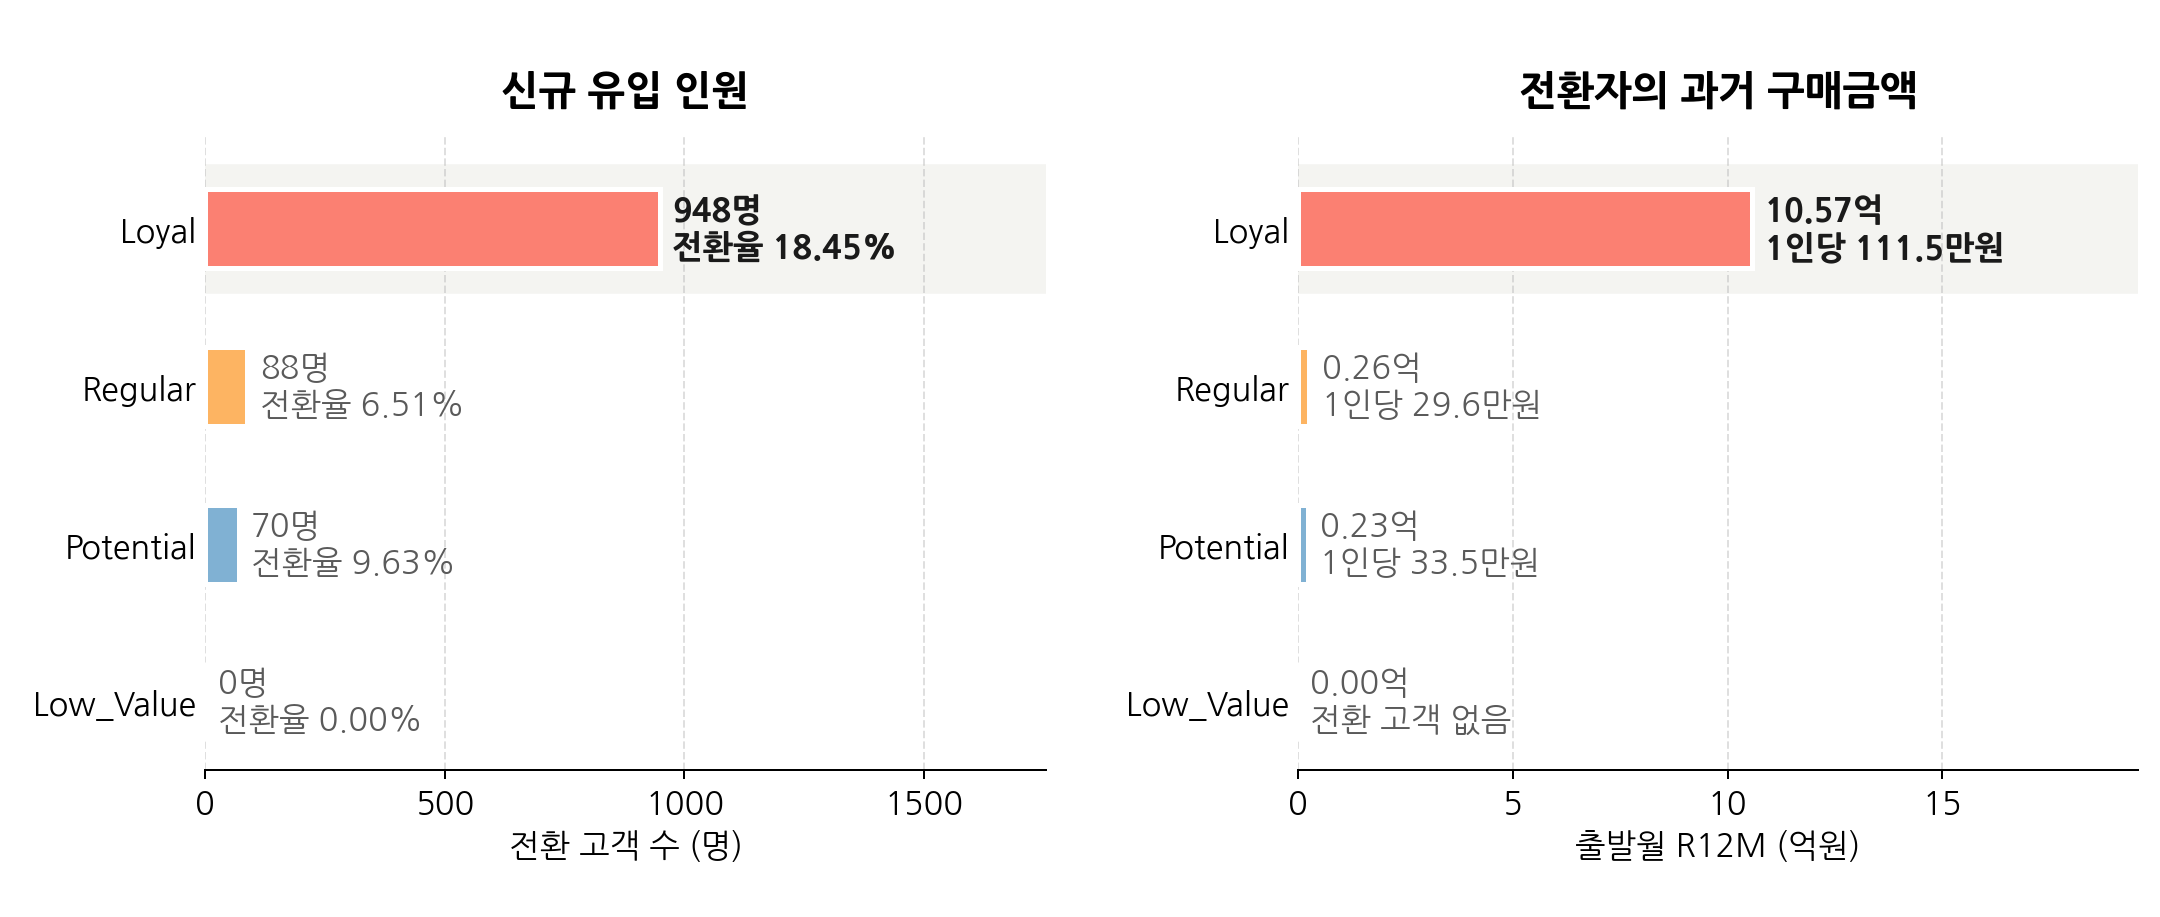

In [1]:
# [C02] 동일 전환월의 출발 세그먼트 비교. 월별 R12M을 연간 매출로 합산하지 않는다.
c02_origins = [s for s in SEGMENT_ORDER if s != 'At_Risk']
c02_monthly = c234_transition_summary('At_Risk', c02_origins)
c02_monthly.to_csv(c234_out/'c02_atrisk_inflow_monthly.csv',index=False)
c02_focus_month = c234_months[-1]
# 분석기간에 실제 유입이 한 번이라도 있는 출발 집단을 모두 표시한다.
c02_seen = set(c02_monthly.loc[c02_monthly.n.gt(0),'from_segment'])
c02_order = [s for s in c02_origins if s in c02_seen]
c02_focus = c02_monthly[c02_monthly.to_month.eq(c02_focus_month)].set_index('from_segment').loc[c02_order]
c02_same = c234_pair[c234_pair.to_month.eq(c02_focus_month)&c234_pair.from_segment.eq('At_Risk')&c234_pair.to_segment.eq('At_Risk')].user_id.nunique()

# C02는 2열 subplot을 유지하고 화면용 글자 크기와 짧은 라벨을 적용한다.
fig_c02,axes_c02=plt.subplots(1,2,figsize=(12,5.1))
for j,(col,div,title,xlabel) in enumerate([
    ('n',1,'신규 유입 인원','전환 고객 수 (명)'),
    ('r12m_sum',1e8,'전환자의 과거 구매금액','출발월 R12M (억원)')]):
    ax=axes_c02[j]
    for i,(seg,row) in enumerate(c02_focus.iterrows()):
        if seg=='Loyal':ax.axhspan(i-.4,i+.4,color='#F4F4F1',zorder=0)
        value=row[col]/div
        ax.barh(i,value,height=.5,color=PALETTE_SEG[seg],**bar_style(True))
        label=(f'{int(row.n):,}명\n전환율 {row.rate_pct:.2f}%' if j==0 else
               (f'{value:.2f}억\n1인당 {row.r12m_mean/1e4:,.1f}만원' if row.n else '0.00억\n전환 고객 없음'))
        ax.annotate(label,(value,i),xytext=(5,0),textcoords='offset points',va='center',fontsize=13,color=ink(seg=='Loyal'),fontweight='bold' if seg=='Loyal' else 'normal')
    ax.set_yticks(range(len(c02_order)),c02_order);ax.invert_yaxis();ax.tick_params(axis='y',length=0)
    ax.set_xlim(0,c02_focus[col].max()/div*1.85)
    finalize_screen(ax,title,xlabel,None,grid_axis='x')
    ax.tick_params(labelsize=13);ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
fig_c02.subplots_adjust(left=.095,right=.99,bottom=.16,top=.85,wspace=.30)
fig_c02.savefig(c234_out/'c02_atrisk_two_columns_screen.png',dpi=180,facecolor='white')
display(c02_focus)
plt.show()


# 5. 세그먼트별 매출 기여와 과거 구매금액

### 5.1. 세그먼트별 매출 변화 구성 요소 분해  `[A12]`

=== 전사 매출 134.3억 → 170.9억 (+27.3%) ===
  (매출 분석: 2023년 134억 → 2024년 171억, +27.3%)


,매출_2023(억),매출_2024(억),증감률(%),구매고객 기여(%),빈도 기여(%),AOV 기여(%),전사 증분 기여(%)
segment,,,,,,,
Low_Value,13.4,16.5,22.4,49.4,2.3,48.3,8.2
Loyal,31.2,36.8,18.1,105.3,-11.6,6.3,15.4
Potential,11.2,7.8,-30.0,139.3,6.0,-45.3,-9.1
Regular,8.6,10.2,18.5,47.1,-11.6,64.5,4.4
VIP,69.9,99.6,42.5,97.9,-6.1,8.2,81.1


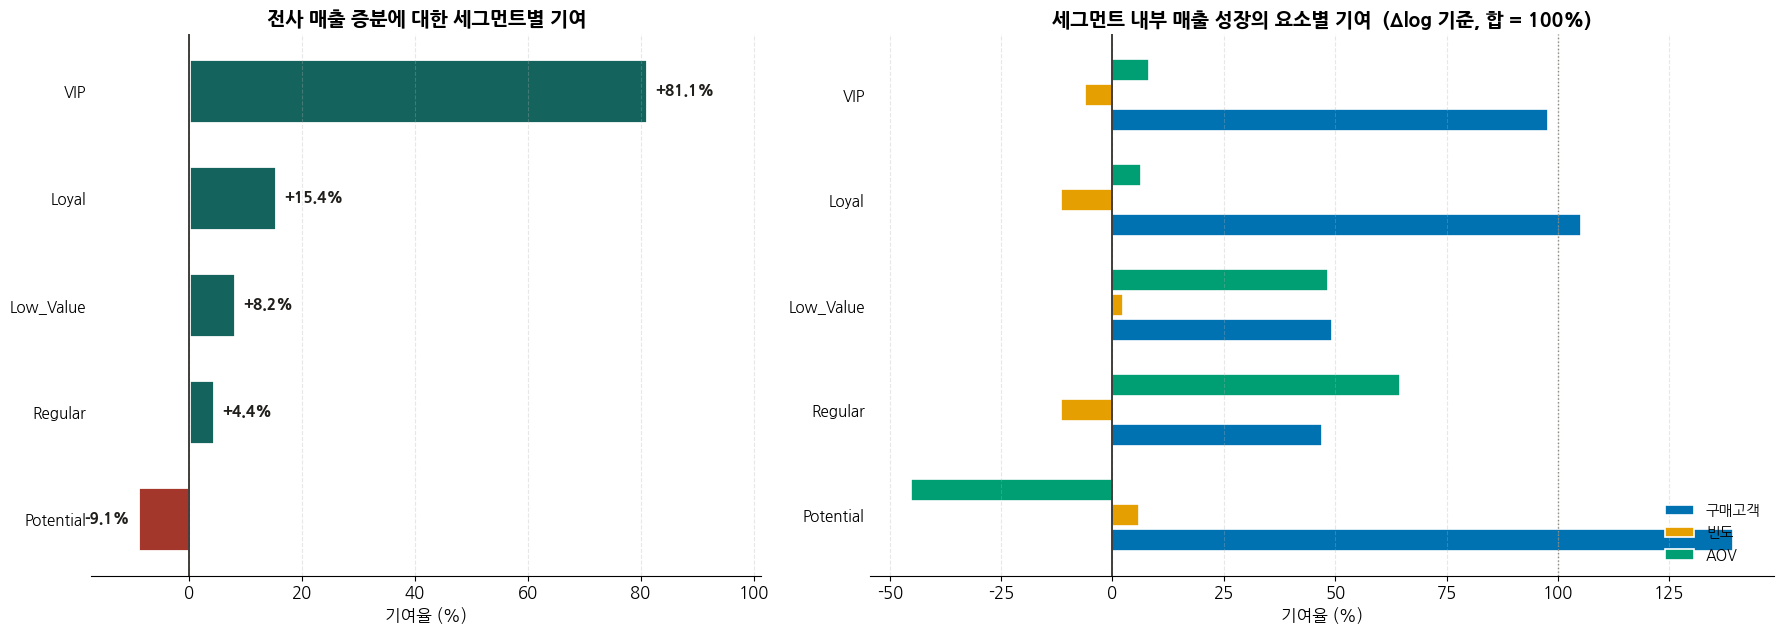


→ 전사 매출 증분의 81.1%를 `VIP` 단독으로 설명
→ 매출이 역성장한 세그먼트: Potential
→ 빈도가 매출 성장에 음(-)으로 기여한 세그먼트: Loyal, Regular, VIP
→ 모든 세그먼트에서 구매고객 수가 지배적 기여 요소 — 매출 분석의 전사 결론이 세그먼트 수준에서도 성립


In [500]:
# =====================================================================================
# [A12] 세그먼트별 매출 성장의 로그 기여도 분해
# =====================================================================================
# 매출 분석은 플랫폼 전체 매출을 `구매고객 수 × 빈도 × AOV`로 분해했다.
# 같은 분해를 세그먼트 단위로 반복하면 "어느 세그먼트에서 어느 요소가 실제로 움직였는가"가
# 특정된다. 매출은 곱의 구조이므로 로그를 취해 덧셈 관계로 바꾼다.
#     Δlog(매출) = Δlog(구매고객) + Δlog(빈도) + Δlog(AOV)
# 각 항을 Δlog(매출)로 나누면 세그먼트 내부에서의 요소별 기여율(%)이 된다.
# 함께 세그먼트별로 전사 매출 증분에 얼마나 기여했는지도 산출한다.
# =====================================================================================

a = seg_year[seg_year["yr"] == "2023"].set_index("segment")
b = seg_year[seg_year["yr"] == "2024"].set_index("segment")
common = sorted(set(a.index) & set(b.index))

tot0, tot1 = a["revenue"].sum(), b["revenue"].sum()
rows = []
for sg in common:
    d_rev = np.log(b.loc[sg, "revenue"]) - np.log(a.loc[sg, "revenue"])
    rows.append({
        "segment": sg,
        "매출_2023(억)": a.loc[sg, "revenue"] / 1e8,
        "매출_2024(억)": b.loc[sg, "revenue"] / 1e8,
        "증감률(%)": (b.loc[sg, "revenue"] / a.loc[sg, "revenue"] - 1) * 100,
        "구매고객 기여(%)": (np.log(b.loc[sg, "buyers"]) - np.log(a.loc[sg, "buyers"])) / d_rev * 100,
        "빈도 기여(%)":    (np.log(b.loc[sg, "freq"])   - np.log(a.loc[sg, "freq"]))   / d_rev * 100,
        "AOV 기여(%)":     (np.log(b.loc[sg, "aov"])    - np.log(a.loc[sg, "aov"]))    / d_rev * 100,
        "전사 증분 기여(%)": (b.loc[sg, "revenue"] - a.loc[sg, "revenue"]) / (tot1 - tot0) * 100,
    })
decomp = pd.DataFrame(rows).set_index("segment").round(1)

print(f"=== 전사 매출 {tot0/1e8:.1f}억 → {tot1/1e8:.1f}억 (+{(tot1/tot0-1)*100:.1f}%) ===")
print("  (매출 분석: 2023년 134억 → 2024년 171억, +27.3%)")
display(decomp)

# ---- 시각화 ---------------------------------------------------------------------------
POS_C2, NEG_C2 = "#14635D", "#A3372B"
CONTRIB_COLORS = {"구매고객": "#0072B2", "빈도": "#E69F00", "AOV": "#009E73"}

order = decomp["전사 증분 기여(%)"].sort_values().index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1, 1.35]})

# (좌) 전사 매출 증분 기여
ax = axes[0]
vals = decomp.loc[order, "전사 증분 기여(%)"].values
ax.barh(order, vals, color=[POS_C2 if v >= 0 else NEG_C2 for v in vals],
        height=0.6, edgecolor="white", linewidth=2)
for i, v in enumerate(vals):
    ax.annotate(f"{v:+.1f}%", xy=(v, i), xytext=(6 if v >= 0 else -6, 0),
                textcoords="offset points", va="center",
                ha="left" if v >= 0 else "right",
                fontsize=11, fontweight="bold", color="#201F1C")
ax.axvline(0, color="#201F1C", linewidth=1.2)
ax.set_title("전사 매출 증분에 대한 세그먼트별 기여", fontsize=14, fontweight="bold")
ax.set_xlabel("기여율 (%)")
ax.set_xlim(min(vals) * 1.35 - 5, max(vals) * 1.25)

# (우) 세그먼트 내부의 요소별 기여
ax = axes[1]
h = 0.24
y = np.arange(len(order))
for j, (k, col) in enumerate(CONTRIB_COLORS.items()):
    v = decomp.loc[order, f"{k} 기여(%)"].values
    ax.barh(y + (j - 1) * h, v, height=h * 0.88, color=col,
            edgecolor="white", linewidth=1.2, label=k)
ax.axvline(0, color="#201F1C", linewidth=1.2)
ax.axvline(100, color="#8A897F", linewidth=1, linestyle=":")
ax.set_yticks(y); ax.set_yticklabels(order)
ax.set_title("세그먼트 내부 매출 성장의 요소별 기여  (Δlog 기준, 합 = 100%)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("기여율 (%)")
ax.legend(frameon=False, fontsize=10.5, loc="lower right")

for a_ in axes:
    a_.grid(axis="x", linestyle="--", alpha=0.3)
    for s in ["top", "right", "left"]:
        a_.spines[s].set_visible(False)
    a_.tick_params(axis="y", length=0, labelsize=11)
plt.tight_layout()
plt.show()

# ---- 요약 -----------------------------------------------------------------------------
top = decomp["전사 증분 기여(%)"].idxmax()
neg = decomp.index[decomp["증감률(%)"] < 0].tolist()
down_f = decomp.index[decomp["빈도 기여(%)"] < 0].tolist()
print(f"\n→ 전사 매출 증분의 {decomp.loc[top,'전사 증분 기여(%)']:.1f}%를 `{top}` 단독으로 설명")
if neg:
    print(f"→ 매출이 역성장한 세그먼트: {', '.join(neg)}")
if down_f:
    print(f"→ 빈도가 매출 성장에 음(-)으로 기여한 세그먼트: {', '.join(down_f)}")
print("→ 모든 세그먼트에서 구매고객 수가 지배적 기여 요소 — 매출 분석의 전사 결론이 세그먼트 수준에서도 성립")


### 5.2. 세그먼트별 AOV / ARPPU 변화

In [471]:
def segment_aov_arppu(
    snapshots_df: pd.DataFrame,
    orders_enriched_df: pd.DataFrame,
    metric: str = "aov",
    lookback_days: int = 365,
    paid_statuses: set = frozenset({"Completed", "Processing"}),
) -> pd.DataFrame:
    """
    snapshot_month별 세그먼트별 AOV 또는 ARPPU 집계 함수.
    - AOV(Average Order Value, 주문당 평균 매출): 총 매출 / 총 주문 수
    - ARPPU(Average Revenue Per Paying User, 결제 유저당 평균 매출): 총 매출 / 결제 유저 수(구매자 수)

    Input:
      - snapshots_df (DataFrame)     : snapshot_month(str, "YYYY-MM"), user_id(int), segment(str) 필수.
      - orders_enriched_df (DataFrame): user_id(int), created_at(datetime), order_amount(float), id(str), status(str) 필수.
      - metric (str)                 : "aov", "arppu", "both". (기본값: "aov")
      - lookback_days (int)          : snapshot_month 말일 기준 소급 일수. (기본값: 365)
      - paid_statuses (set)          : 결제로 인정할 status 집합. (기본값: {"Completed", "Processing"})

    Return:
      - DataFrame (long 포맷): snapshot_month, segment, 선택한 지표(aov / arppu / aov, arppu)
    """
    if metric not in ("aov", "arppu", "both"):
        raise ValueError(f"metric은 'aov', 'arppu', 'both' 중 하나여야 합니다. 입력값: {metric!r}")

    # 1. 주문 데이터 전처리 (타입 변환 및 결제완료 건만 필터)
    orders = (
        orders_enriched_df[orders_enriched_df["status"].isin(paid_statuses)]
        .assign(created_at=pd.to_datetime(orders_enriched_df["created_at"], errors="coerce"))
        .dropna(subset=["created_at"])
        [["id", "user_id", "created_at", "order_amount"]]
    )

    # 2. 스냅샷 데이터 월별 그룹화 캐싱 (O(1) 접근)
    snapshots_grouped = dict(tuple(snapshots_df[["snapshot_month", "user_id", "segment"]].groupby("snapshot_month")))
    unique_months = snapshots_df["snapshot_month"].unique()

    results = []

    # 3. 기준월 단위로 순회
    for month in unique_months:
        month_end = pd.to_datetime(month) + pd.offsets.MonthEnd(0) + pd.Timedelta(days=1)
        month_start = month_end - pd.Timedelta(days=lookback_days)

        # 가. 해당 월 Lookback 기간 내 주문만 필터
        mask = (orders["created_at"] >= month_start) & (orders["created_at"] < month_end)  # 예. month="2023-01"일때, "2022-02-01"이상 "2023-02-01"미만
        valid_orders = orders[mask]

        # 나. 유저별 주문 집계 (1:1 조인을 위해 압축)
        # aov 계산 시 order_amount 총합, 주문 건수(id count) 필요
        user_agg = valid_orders.groupby("user_id", as_index=False).agg(
            total_revenue=("order_amount", "sum"),
            total_orders=("id", "count")
        )

        # 다. 스냅샷 매핑
        month_snapshots = snapshots_grouped.get(month)
        if month_snapshots is None:
            continue

        # 라. 스냅샷 1 : 1 유저별 집계
        merged = month_snapshots.merge(user_agg, on="user_id", how="left")

        # 마. 해당 월의 세그먼트별 지표 집계
        # ARPU 계산을 위해 결제 유저 수는 total_revenue가 null이 아닌 경우의 user_id nunique로 계산
        seg_agg = merged.groupby(["snapshot_month", "segment"], as_index=False).agg(
            total_revenue=("total_revenue", "sum"),
            total_orders=("total_orders", "sum"),
            paying_users=("user_id", lambda x: x[merged.loc[x.index, "total_revenue"].notna()].nunique())
        )

        results.append(seg_agg)

    if not results:
        cols = ["snapshot_month", "segment"]
        if metric == "both": cols += ["aov", "arppu"]
        else: cols.append(metric)
        return pd.DataFrame(columns=cols)

    # 4. 결과 병합 및 최종 지표 계산
    final_result = pd.concat(results, ignore_index=True)

    if metric in ("aov", "both"):
        final_result["aov"] = (final_result["total_revenue"] / final_result["total_orders"].replace(0, float("nan"))).round(2)
    if metric in ("arppu", "both"):
        final_result["arppu"] = (final_result["total_revenue"] / final_result["paying_users"].replace(0, float("nan"))).round(2)

    # 필요한 컬럼만 반환
    if metric == "aov":
        return final_result[["snapshot_month", "segment", "aov"]]
    elif metric == "arppu":
        return final_result[["snapshot_month", "segment", "arppu"]]
    else:
        return final_result[["snapshot_month", "segment", "aov", "arppu"]]

In [472]:
segment_aov_arppu_df = segment_aov_arppu(snapshots_df, orders_enriched, metric='both')
segment_aov_arppu_df.head()

,snapshot_month,segment,aov,arppu
0,2023-01,At_Risk,152485.12,625385.57
1,2023-01,Dormant,NaN,NaN
2,2023-01,Low_Value,70137.58,77787.44
3,2023-01,Loyal,143829.29,728750.42
4,2023-01,Potential,253044.99,300980.66


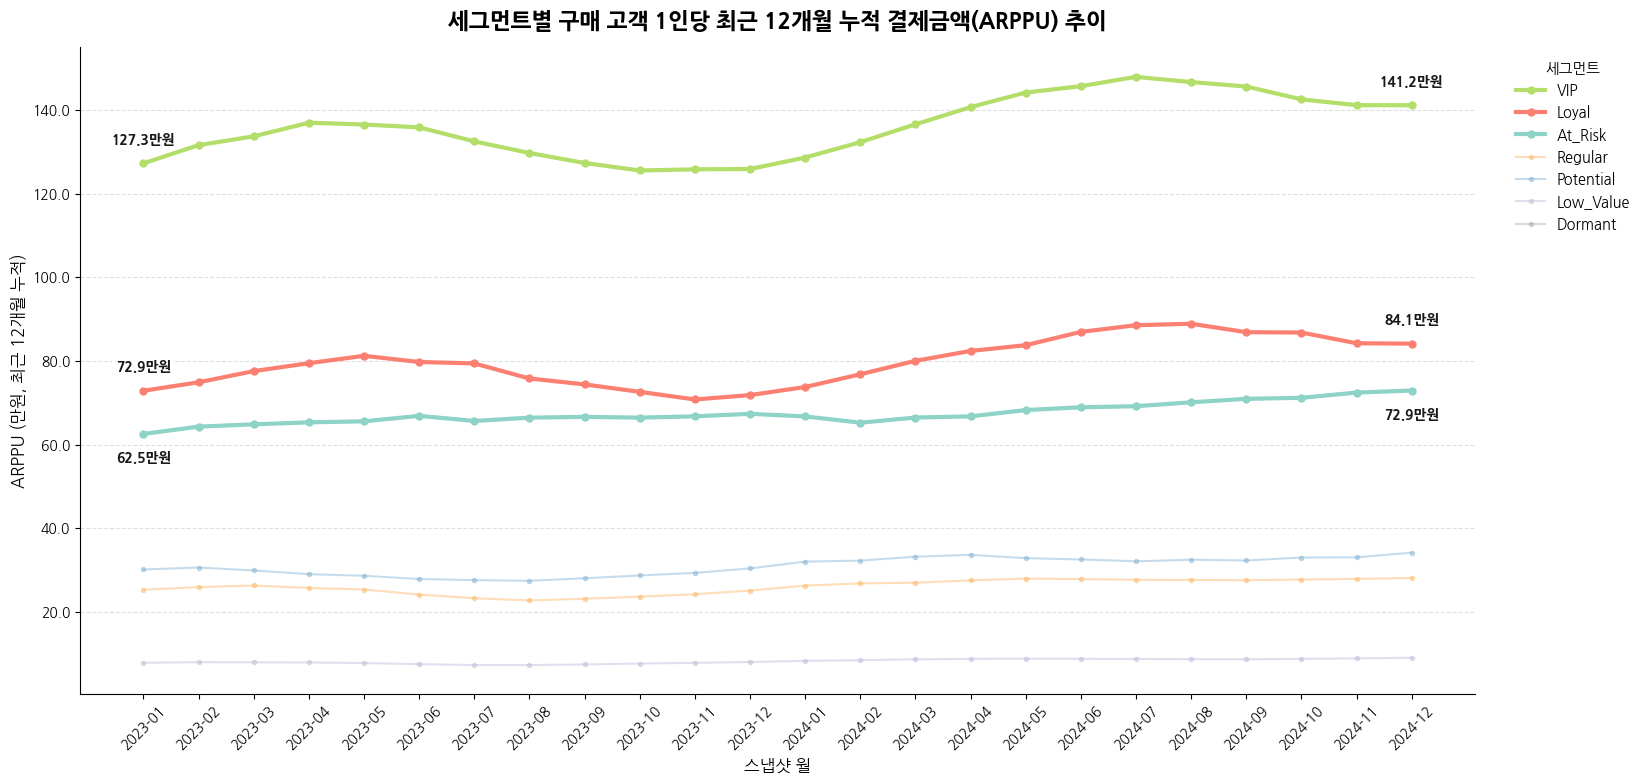

In [ ]:
# =====================================================================================
# [차트] 세그먼트별 구매 고객 1인당 최근 12개월 누적 결제금액(ARPPU) 추이
# =====================================================================================

UNIT_DIV_A, UNIT_SUFFIX_A, UNIT_FMT_A = 1e4, "만원", "{:,.1f}"
_PRIMARY_A = ["VIP", "Loyal", "At_Risk"]

_da = segment_aov_arppu_df.copy()
_da["v"] = _da["arppu"] / UNIT_DIV_A
_moa = sorted(_da["snapshot_month"].unique())

fig, ax = plt.subplots(figsize=fig_size(8))
for seg in [s for s in SEGMENT_ORDER if s in set(_da["segment"].dropna())]:
    g = _da[_da["segment"] == seg].sort_values("snapshot_month")
    ax.plot([_moa.index(m) for m in g["snapshot_month"]], g["v"], marker="o",
            color=PALETTE_SEG[seg], label=seg, **line_style(seg, primary=_PRIMARY_A, secondary=[]))

for seg in _PRIMARY_A:
    g = _da[_da["segment"] == seg]
    for m in (_moa[0], _moa[-1]):
        r = g[g["snapshot_month"] == m]
        if r.empty:
            continue
        y = r["v"].values[0]
        va, dy = ("top", -13) if seg == "At_Risk" else ("bottom", 12)
        ax.annotate(f"{UNIT_FMT_A.format(y)}{UNIT_SUFFIX_A}", xy=(_moa.index(m), y),
                    xytext=(0, dy), textcoords="offset points", ha="center", va=va,
                    fontsize=FS_LABEL + 1, fontweight="bold",
                    color=ink(True), bbox=LABEL_BBOX, zorder=10)

ax.set_xticks(range(len(_moa))); ax.set_xticklabels([str(m) for m in _moa], rotation=45)
finalize(ax, "세그먼트별 구매 고객 1인당 최근 12개월 누적 결제금액(ARPPU) 추이",
         "스냅샷 월", f"ARPPU ({UNIT_SUFFIX_A}, 최근 12개월 누적)", unit_fmt=UNIT_FMT_A)
plt.show()


In [478]:
# 1. 2023년 1월부터 2024년 12월까지의 데이터만 필터링
# (snapshot_month가 문자열 또는 datetime/Period 형식일 수 있으므로 안전하게 문자열 기반으로 2023, 2024 필터링)
df_filtered = segment_aov_arppu_df[
    segment_aov_arppu_df["snapshot_month"].astype(str).str.startswith("2023") |
    segment_aov_arppu_df["snapshot_month"].astype(str).str.startswith("2024")
].copy()

# 세그먼트별, 월별 정렬 (시간순 정렬)
df_filtered = df_filtered.sort_values(by=["segment", "snapshot_month"])

# 2. 결과 저장을 위한 리스트 준비
results = []
segments = df_filtered["segment"].unique()

for seg in segments:
    seg_data = df_filtered[df_filtered["segment"] == seg].copy()
    
    # 2023년 1월과 2024년 12월 데이터 추출 (문자열 포함 여부로 확인)
    first_month_data = seg_data[seg_data["snapshot_month"].astype(str).str.contains("2023-01")]
    last_month_data = seg_data[seg_data["snapshot_month"].astype(str).str.contains("2024-12")]
    
    # (1) 전체 기간 대비 증감률 (23년 1월 대비 24년 12월)
    if not first_month_data.empty and not last_month_data.empty:
        aov_first = first_month_data["aov"].values[0]
        aov_last = last_month_data["aov"].values[0]
        aov_total_growth = ((aov_last - aov_first) / aov_first) * 100
        
        arppu_first = first_month_data["arppu"].values[0]
        arppu_last = last_month_data["arppu"].values[0]
        arppu_total_growth = ((arppu_last - arppu_first) / arppu_first) * 100
    else:
        aov_total_growth = np.nan
        arppu_total_growth = np.nan

    # (2) 월평균 증감률 (MoM Growth Rate의 평균)
    # 이전 달 대비 현재 달의 증감률(MoM)을 각각 구한 뒤, 그 값들의 평균을 계산
    seg_data["aov_mom"] = seg_data["aov"].pct_change() * 100
    seg_data["arppu_mom"] = seg_data["arppu"].pct_change() * 100
    
    aov_avg_monthly_growth = seg_data["aov_mom"].mean()
    arppu_avg_monthly_growth = seg_data["arppu_mom"].mean()
    
    results.append({
        "Segment": seg,
        "AOV 전체 증감률(23.01->24.12)(%)": aov_total_growth,
        "AOV 월평균 증감률(%)": aov_avg_monthly_growth,
        "ARPPU 전체 증감률(23.01->24.12)(%)": arppu_total_growth,
        "ARPPU 월평균 증감률(%)": arppu_avg_monthly_growth
    })

# 3. 데이터프레임으로 변환 및 소수점 둘째 자리 반올림
growth_df = pd.DataFrame(results).set_index("Segment").round(2)

# 결과 확인
growth_df

,AOV 전체 증감률(23.01->24.12)(%),AOV 월평균 증감률(%),ARPPU 전체 증감률(23.01->24.12)(%),ARPPU 월평균 증감률(%)
Segment,,,,
At_Risk,10.64,0.45,16.59,0.68
Dormant,NaN,NaN,NaN,NaN
Low_Value,11.13,0.47,15.30,0.64
Loyal,5.21,0.22,15.46,0.66
Potential,16.24,0.68,13.37,0.57
Regular,4.45,0.21,11.05,0.48
VIP,3.85,0.17,10.92,0.47


<!--
#### 예상 손실액 진단
-->

# 6. 분석 결론 · 휴면 전환 손실의 VIP 경로 비중

### 6.1. 실제 휴면 전환자의 VIP 경로와 구매가치

**실제 월별 휴면 전환자 중 VIP 경로 비중**을 측정합니다.

- 월 t의 non-Dormant→Dormant 전환 사건을 집계합니다.
    - 원자료에서 출발 상태가 At_Risk 또는 Low_Value인지 검증합니다.
    - 월별 고객은 중복 없으며 분기 합계는 전환 건수입니다.
- 전환 이전 가장 최근 VIP부터 연속 잔존만 압축해 VIP→Loyal→At_Risk→Dormant 또는 VIP→Loyal→At_Risk→Low_Value→Dormant와 정확히 일치하는 경우를 분류합니다.
    - 진입 이후 12개월 이내 휴면 전환만 포함하며 실제 관측된 일치 경로 중 12개월 초과 사례가 없는지도 확인합니다.
- 경로 관측 기회를 동일하게 만들기 위해 비교 차트는 **2024-02~12**로 제한합니다.
    - VIP 세그먼트 고객의 휴면 전환까지 소요되는 최장 기간(13개월)의 과거 스냅샷이 확보되는 시점입니다.
    - 기타·미확인은 두 정확한 경로가 확인되지 않은 고객이며 과거 VIP 경험이 없다는 뜻은 아닙니다.
- 직접 경로의 분모는 At_Risk→Dormant, 두 경로 합계의 분모는 전체 휴면 전환(At_Risk 또는 Low_Value→Dormant)입니다.

**[집계 지표 정의]**
- 출발월 R12M: t월 1일로부터 과거 365일 주문금액 합계.
- 마지막 구매일 기준 R12M: 마지막 유효 구매일을 포함한 365일(종료는 그다음 날 0시).

**[집계 방법]**
- 주문 Completed·Processing, 상품 Purchased·Shipped·Packing, sale_price 합산.
- 모든 전환자의 출발월 금액을 스냅샷 monetary와 대조합니다. 마지막 구매일 기준 365일이 원자료 범위 안에 있는지도 검증합니다.

In [ ]:
vd_root=Path('..')
vd_out=Path(globals().get('VD_OUTPUT_DIR',vd_root/'outputs'))
vd_out.mkdir(parents=True,exist_ok=True)
vd_s=pd.read_parquet(vd_root/'data/snapshots_df.parquet').copy()
vd_s['month']=pd.to_datetime(vd_s.snapshot_month)
assert not vd_s.duplicated(['user_id','month']).any()
vd_months=pd.date_range(vd_s.month.min(),vd_s.month.max(),freq='MS')
vd_matrix=vd_s.pivot(index='user_id',columns='month',values='segment').reindex(columns=vd_months)
vd_records=[]
vd_direct=('VIP','Loyal','At_Risk','Dormant')
vd_via=('VIP','Loyal','At_Risk','Low_Value','Dormant')
for uid,row in vd_matrix.iterrows():
    states=row.to_numpy()
    for t in range(1,len(states)):
        if states[t]!='Dormant' or states[t-1] not in ['At_Risk','Low_Value']:continue
        # 가장 최근 VIP부터 연속 잔존만 압축한다. 중간 상태는 생략하지 않는다.
        vip_positions=[j for j in range(t) if states[j]=='VIP']
        route='기타·미확인';entry=-1;elapsed=np.nan
        if vip_positions:
            j=vip_positions[-1]; path=[]
            for state in states[j:t+1]:
                if not path or path[-1]!=state:path.append(state)
            if tuple(path) in (vd_direct,vd_via):
                entry=j+1;elapsed=t-entry
                route='직접' if tuple(path)==vd_direct else 'Low_Value 경유'
        vd_records.append({'user_id':uid,'month':vd_months[t],'from_segment':states[t-1],
            'observed_route':route,'entry_elapsed':elapsed,
            'route':route if route!='기타·미확인' and elapsed<=12 else '기타·미확인'})
vd_events=pd.DataFrame(vd_records)
vd_events['from_month']=vd_events.month-pd.offsets.MonthBegin(1)
vd_events=vd_events.merge(vd_s[['user_id','month','monetary','last_order_dt']].rename(
    columns={'month':'from_month','monetary':'source_r12m','last_order_dt':'snapshot_last_order'}),
    on=['user_id','from_month'],validate='one_to_one')
assert vd_events.source_r12m.notna().all()

# 원 주문/상품에서 기존 보고서와 같은 유효 주문금액을 재구성한다.
vd_orders=pd.read_csv(vd_root/'data/orders.csv',usecols=['id','user_id','status','created_at'],parse_dates=['created_at'])
vd_items=pd.read_csv(vd_root/'data/order_items.csv',usecols=['order_id','status','sale_price'])
vd_amounts=vd_items.loc[vd_items.status.isin(['Purchased','Shipped','Packing'])].groupby('order_id').sale_price.sum()
vd_orders['amount']=vd_orders.id.map(vd_amounts)
vd_orders=vd_orders[vd_orders.status.isin(['Completed','Processing']) & vd_orders.amount.notna()].copy()
assert not vd_orders.id.duplicated().any()
vd_order_groups={uid:g.sort_values('created_at') for uid,g in vd_orders.groupby('user_id')}
vd_min_day=vd_orders.created_at.min().normalize()
vd_values=[]
for r in vd_events.itertuples():
    g=vd_order_groups[r.user_id]
    source_end=r.month
    eligible=g[g.created_at.lt(source_end)]
    last=eligible.created_at.max()
    end=last.normalize()+pd.Timedelta(days=1);start=end-pd.Timedelta(days=365)
    active_value=eligible.loc[eligible.created_at.ge(start)&eligible.created_at.lt(end),'amount'].sum()
    source_value=eligible.loc[eligible.created_at.ge(source_end-pd.Timedelta(days=365)),'amount'].sum()
    assert abs(source_value-r.source_r12m)<.01
    assert last==pd.Timestamp(r.snapshot_last_order)
    vd_values.append((last,active_value,start>=vd_min_day))
vd_events[['last_purchase','last_purchase_r12m','last_window_complete']]=pd.DataFrame(vd_values,index=vd_events.index)
vd_events['last_purchase_r12m']=vd_events.last_purchase_r12m.astype(float)
vd_events['target']=vd_events.route.ne('기타·미확인')

# 12개월 경로의 시작 직전 VIP 월까지 같은 관측 기회를 확보: 2024-02 이후.
vd_events['comparable']=vd_events.month.ge(vd_months.min()+pd.DateOffset(months=13))
vd_rows=[]
for month,g in vd_events.groupby('month'):
    for scope,base in [('At_Risk 직접',g[g.from_segment.eq('At_Risk')]),('전체 휴면 전환',g)]:
        h=base[base.target]
        vd_rows.append({'month':month,'scope':scope,'n':len(base),'target_n':len(h),
            'source_r12m':base.source_r12m.sum(),'target_source_r12m':h.source_r12m.sum(),
            'last_r12m':base.last_purchase_r12m.sum(),'target_last_r12m':h.last_purchase_r12m.sum(),
            'count_share':len(h)/len(base)*100 if len(base) else np.nan,
            'value_share':h.source_r12m.sum()/base.source_r12m.sum()*100,
            'last_value_share':h.last_purchase_r12m.sum()/base.last_purchase_r12m.sum()*100})
vd_monthly=pd.DataFrame(vd_rows)
vd_dec=vd_events[vd_events.month.eq('2024-12-01')]
assert len(vd_dec[vd_dec.from_segment.eq('At_Risk')])==716
assert abs(vd_dec.loc[vd_dec.from_segment.eq('At_Risk'),'source_r12m'].sum()-294140460)<.01
assert len(vd_dec[vd_dec.from_segment.eq('Low_Value')])==1123
assert vd_events.loc[vd_events.comparable,'last_window_complete'].all(), '마지막 구매일 365일 원자료 관측 부족'
assert vd_events[vd_events.target & vd_events.from_segment.eq('At_Risk')].route.eq('직접').all()
assert vd_events[vd_events.target & vd_events.from_segment.eq('Low_Value')].route.eq('Low_Value 경유').all()

# 당월 휴면 유입의 출발 상태가 두 상태로만 구성되는지도 독립 확인.
vd_actual=sum(((vd_matrix[m]=='Dormant') & vd_matrix[vd_months[i-1]].notna() &
               (vd_matrix[vd_months[i-1]]!='Dormant')).sum() for i,m in enumerate(vd_months) if i>0)
assert vd_actual==len(vd_events)
vd_events.to_csv(vd_out/'vd_event_audit.csv',index=False)
vd_monthly.to_csv(vd_out/'vd_monthly_summary.csv',index=False)
vd_period_rows=[]
for period,start,end in [('2024 Q2','2024-04-01','2024-06-01'),('2024 Q4','2024-10-01','2024-12-01')]:
    for scope in vd_monthly.scope.unique():
        g=vd_monthly[vd_monthly.month.between(start,end)&vd_monthly.scope.eq(scope)]
        sums=g[['n','target_n','source_r12m','target_source_r12m','last_r12m','target_last_r12m']].sum()
        vd_period_rows.append({'period':period,'scope':scope,**sums.to_dict(),
            'count_share':sums.target_n/sums.n*100,'value_share':sums.target_source_r12m/sums.source_r12m*100})
vd_periods=pd.DataFrame(vd_period_rows)
vd_periods.to_csv(vd_out/'vd_period_summary.csv',index=False)
vd_routes=vd_dec.groupby(['from_segment','route']).agg(n=('user_id','size'),source_r12m=('source_r12m','sum'),
    last_r12m=('last_purchase_r12m','sum')).reset_index()
vd_routes.to_csv(vd_out/'vd_dec_routes.csv',index=False)
print('원자료 R12M 대조, 모든 휴면 유입 분모, 경로 배타성, 마지막 구매일 관측구간 검증 완료')
display(vd_monthly[vd_monthly.month.isin(pd.to_datetime(['2024-02-01','2024-12-01']))])
display(vd_periods);display(vd_routes)
print('12개월 초과 경로:',len(vd_events[vd_events.observed_route.ne('기타·미확인') & ~vd_events.target]))


원자료 R12M 대조, 모든 휴면 유입 분모, 경로 배타성, 마지막 구매일 관측구간 검증 완료


,month,scope,n,target_n,source_r12m,target_source_r12m,last_r12m,target_last_r12m,count_share,value_share,last_value_share
24,2024-02-01,At_Risk 직접,384,244,152491810.0,107773190.0,4.157083e+08,3.543720e+08,63.541667,70.674740,85.245355
25,2024-02-01,전체 휴면 전환,921,401,197372370.0,122047420.0,6.764990e+08,5.570211e+08,43.539631,61.836122,82.338793
44,2024-12-01,At_Risk 직접,716,471,294140460.0,212529990.0,7.803107e+08,6.625912e+08,65.782123,72.254592,84.913763
45,2024-12-01,전체 휴면 전환,1839,820,396582340.0,248342880.0,1.344771e+09,1.089677e+09,44.589451,62.620761,81.030678


,period,scope,n,target_n,source_r12m,target_source_r12m,last_r12m,target_last_r12m,count_share,value_share
0,2024 Q2,At_Risk 직접,1222.0,755.0,5.041996e+08,342096930.0,1.348709e+09,1.129198e+09,61.783961,67.849499
1,2024 Q2,전체 휴면 전환,3760.0,1304.0,7.210491e+08,396356430.0,2.340272e+09,1.857698e+09,34.680851,54.969408
2,2024 Q4,At_Risk 직접,2043.0,1305.0,8.175735e+08,564450200.0,2.116753e+09,1.765743e+09,63.876652,69.039690
3,2024 Q4,전체 휴면 전환,5533.0,2299.0,1.128151e+09,661375050.0,3.732888e+09,2.952616e+09,41.550696,58.624714


,from_segment,route,n,source_r12m,last_r12m
0,At_Risk,기타·미확인,245,81610470.0,117719520.0
1,At_Risk,직접,471,212529990.0,662591190.0
2,Low_Value,Low_Value 경유,349,35812890.0,427085930.0
3,Low_Value,기타·미확인,774,66628990.0,137374440.0


12개월 초과 경로: 0


<!--
### 전체 프로젝트 결론 2-1 ④용 요약 차트
2024년 12월 실제 휴면 전환자 전체를 분모로, VIP→Loyal→At_Risk→Dormant 및 Low_Value 경유 경로의 인원·마지막 구매일 포함 365일 구매금액 비중을 비교한다. CHART THEME v2 화면용 프로필 적용.
-->

### 6.2. VIP 휴면 경로 시각화
2024년 12월 전체 휴면 전환자 중 주요 2개 경로(VIP→Loyal→At_Risk→Dormant 및 Low_Value 경유)에 대해 다음 2개 항목을 시각화합니다.
1. 인원 비중
2. 구매금액 비중

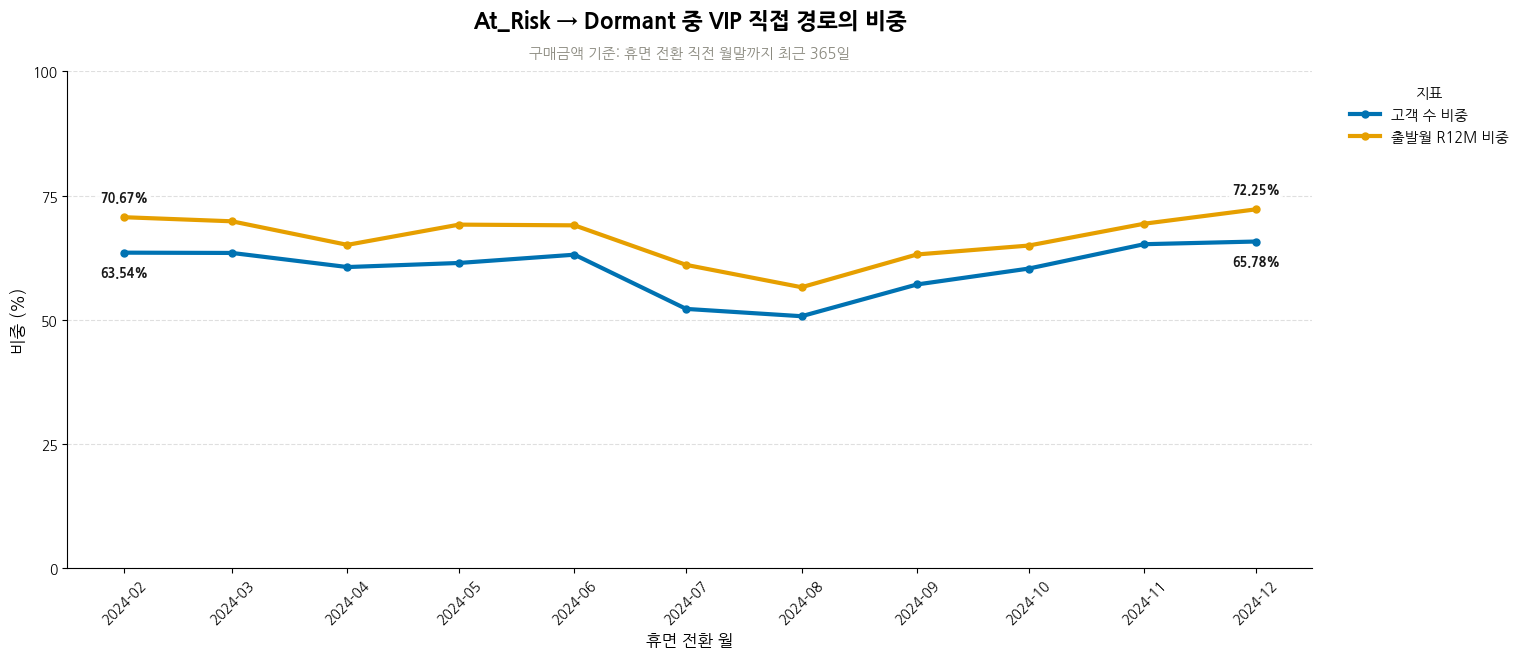

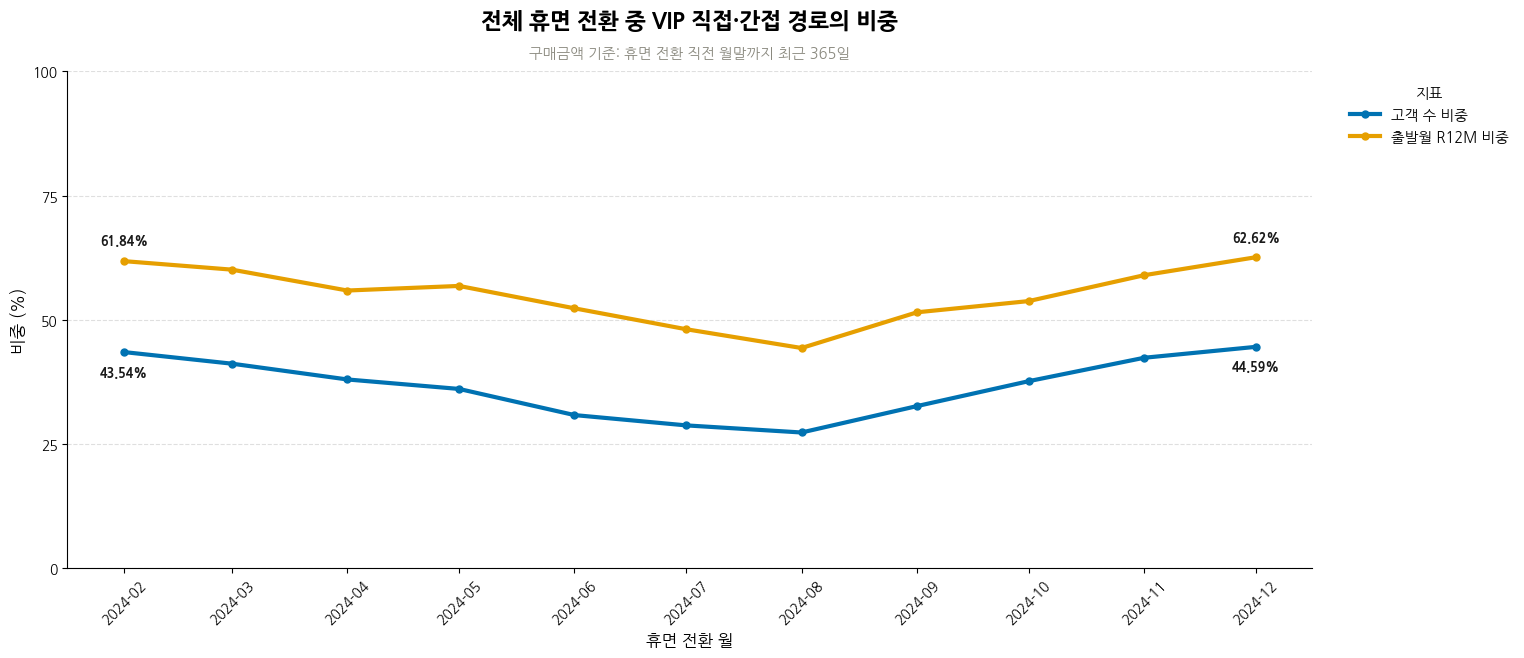

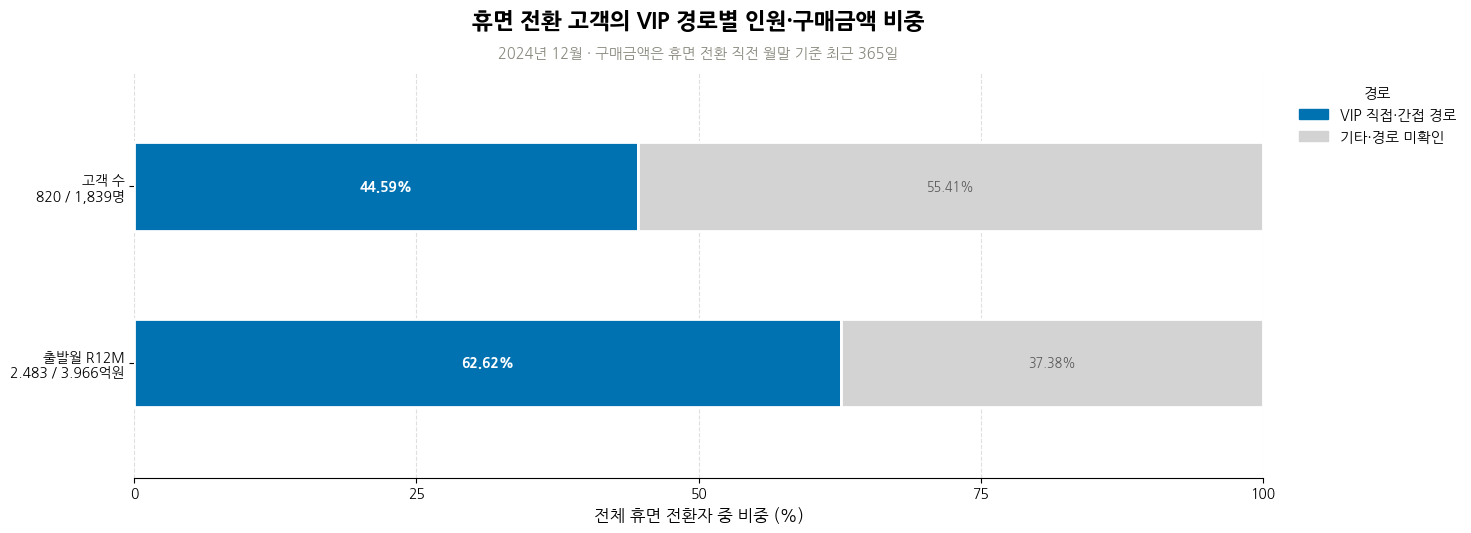

{'customer_share': 44.58945078847199, 'source_r12m_share': 62.62076117660711, 'source_r12m': 248342880, 'denominator_r12m': 396582340}


In [ ]:
vd_out = Path('../outputs')
rev_monthly = pd.read_csv(vd_out/'vd_monthly_summary.csv', parse_dates=['month'])
rev_routes = pd.read_csv(vd_out/'vd_dec_routes.csv')

# 기본 CHART THEME v2 직접 사용: 화면용 프로필 및 다중 패널 사용 안 함.
for scope, title, filename in [
    ('At_Risk 직접','At_Risk → Dormant 중 VIP 직접 경로의 비중','vd_direct_common_v2.png'),
    ('전체 휴면 전환','전체 휴면 전환 중 VIP 직접·간접 경로의 비중','vd_both_common_v2.png')]:
    d=rev_monthly[rev_monthly.scope.eq(scope)&rev_monthly.month.ge('2024-02-01')].sort_values('month')
    fig=plt.figure(figsize=fig_size(7)); ax=fig.add_axes([.1,.1,.8,.8])
    names=['고객 수 비중','출발월 R12M 비중']

    for col,label,color,offset in [('count_share',names[0],CAT_PALETTE[0],-17),('value_share',names[1],CAT_PALETTE[1],12)]:
        ax.plot(d.month,d[col],marker='o',color=color,label=label,**line_style(label,primary=names,secondary=[]))

        for k in [0,len(d)-1]:
            row=d.iloc[k]
            ax.annotate(f'{row[col]:.2f}%',(row.month,row[col]),xytext=(0,offset),textcoords='offset points',ha='center',fontsize=FS_LABEL,fontweight='bold',color=INK_PRIMARY,bbox=LABEL_BBOX)

    ax.set_ylim(0,100); ax.set_yticks([0,25,50,75,100])
    ax.set_xticks(d.month); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    finalize(ax,title,'휴면 전환 월','비중 (%)',subtitle='구매금액 기준: 휴면 전환 직전 월말까지 최근 365일',legend_title='지표',legend_order=names,xtick_rotation=45,layout=False)

    # 공통 범례 여백을 포함한 캔버스에서 단일 축을 배치한다.
    fig.subplots_adjust() if False else None
    ax.set_position([.065,.16,.75,.71])
    fig.savefig(vd_out/filename,dpi=180,bbox_inches='tight',facecolor='white');plt.show()

target=rev_routes[rev_routes.route.isin(['직접','Low_Value 경유'])]
shares=[target.n.sum()/rev_routes.n.sum()*100,target.source_r12m.sum()/rev_routes.source_r12m.sum()*100]

assert round(shares[1],2)==62.62
assert int(target.source_r12m.sum())==248342880

fig=plt.figure(figsize=fig_size(5.8));ax=fig.add_axes([.13,.16,.68,.70])

for y,s in enumerate(shares):
    ax.barh(y,s,height=.5,color=CAT_PALETTE[0],**bar_style())
    ax.barh(y,100-s,left=s,height=.5,color='#D3D3D3',**bar_style())
    ax.text(s/2,y,f'{s:.2f}%',ha='center',va='center',fontsize=FS_LABEL+1,fontweight='bold',color='white')
    ax.text(s+(100-s)/2,y,f'{100-s:.2f}%',ha='center',va='center',fontsize=FS_LABEL,color=INK_SECONDARY)

ax.set_yticks([0,1],['고객 수\n820 / 1,839명','출발월 R12M\n2.483 / 3.966억원'])
ax.set_ylim(1.65,-.65);ax.set_xlim(0,100);ax.set_xticks([0,25,50,75,100])
names=['VIP 직접·간접 경로','기타·경로 미확인']
finalize(ax,'휴면 전환 고객의 VIP 경로별 인원·구매금액 비중','전체 휴면 전환자 중 비중 (%)',subtitle='2024년 12월 · 구매금액은 휴면 전환 직전 월말 기준 최근 365일',grid_axis='x',legend_title='경로',legend_order=names,handles=[Patch(color=CAT_PALETTE[0]),Patch(color='#D3D3D3')],labels=names,layout=False)

fig.savefig(vd_out/'vd_conclusion4_source_common_v2.png',dpi=180,bbox_inches='tight',facecolor='white');plt.show()
print({'customer_share':shares[0],'source_r12m_share':shares[1],'source_r12m':int(target.source_r12m.sum()),'denominator_r12m':int(rev_routes.source_r12m.sum())})
